# BÁO CÁO CUỐI KỲ — ADY201m
## Phân loại nhãn tiền tiểu đường/tiểu đường trong khảo sát BRFSS2015 ở người từ 60 tuổi trở lên
**Nhóm 6 — AI2104**

| Thành viên | Mã sinh viên |
|---|---|
| Trần Tuấn Hiệp | HE211144 |
| Nguyễn Thế Hải | HE211655 |
| Trần Công Du | HE211007 |

Báo cáo kết nối xác định vấn đề, dữ liệu thô, tiền xử lý, SQL, phân tích và trực quan Python, so sánh Logistic Regression cùng các mô hình cây. Nhãn 1 gồm tiền tiểu đường/tiểu đường tự khai; kết quả mô tả mẫu khảo sát, không phải dự báo phát bệnh tương lai.

**Cách đọc:** phần I–III trình bày vấn đề, dữ liệu và tiền xử lý; phần IV trình bày EDA, biến ứng viên và VIF; phần V thiết lập thử nghiệm tuần tự; phần VI so sánh mô hình qua CV trên Train. Phần VII đánh giá cuối trên Test; phần VIII kết luận, nêu giới hạn và giả thuyết nghiên cứu tiếp theo. Nhóm dừng dự án ở phần VIII.

**Trạng thái biên tập:** Nhóm đã chạy EDA, VIF, CV so sánh 21/17 biến và năm lượt thử tương tác. Nhóm đã chốt Logistic Regression 22 biến, XGBoost 23 biến và đánh giá cuối trên Test tại phần VII. Nhóm đã rà soát sự nhất quán giữa mục tiêu, phương pháp, số liệu và kết luận; nhóm giữ nguyên mô hình và dự đoán đã lưu.


In [1]:
from pathlib import Path
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","pandas","numpy","scipy","matplotlib","seaborn","scikit-learn","xgboost","imbalanced-learn","joblib","threadpoolctl"])
import pandas as pd

# Đọc CSV đã chọn người từ 60 tuổi trở lên
search_roots = [Path.cwd(), *Path.cwd().parents]
CSV_PATH = next((candidate for root in search_roots
                 for candidate in (root / "data.csv", root / "data_đầu_vào" / "data.csv")
                 if candidate.is_file()), None)
if CSV_PATH is None:
    raise FileNotFoundError("Đặt data.csv trong data_đầu_vào của dự án hoặc cạnh notebook đang chạy.")
FINAL_ROOT = CSV_PATH.parent.parent if CSV_PATH.parent.name == "data_đầu_vào" else CSV_PATH.parent
df_brfss_raw = pd.read_csv(CSV_PATH, float_precision="round_trip")
if "_AGEG5YR" not in df_brfss_raw.columns:
    raise ValueError("data.csv thiếu cột tuổi nguồn _AGEG5YR.")
if df_brfss_raw.empty or not df_brfss_raw["_AGEG5YR"].isin([9, 10, 11, 12, 13]).all():
    raise ValueError("data.csv phải chứa hồ sơ từ 60 tuổi trở lên: _AGEG5YR mã 9–13.")
print("CSV đầu vào:", CSV_PATH)
print("Kích thước trước làm sạch:", df_brfss_raw.shape)
display(df_brfss_raw.head())


CSV đầu vào: C:\Users\Admin\Documents\ChatGPT\ady201m\notebook_da_sua\run_edited\data.csv
Kích thước trước làm sạch: (202412, 330)


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDINFR4,...,_VEG23,_FRUITEX,_VEGETEX,_TOTINDA,METVL11_,METVL21_,MAXVO2_,FC60_,ACTIN11_,ACTIN21_,PADUR1_,PADUR2_,PAFREQ1_,PAFREQ2_,_MINAC11,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,1.0,1.0,1292015,1,29,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,15.0,18.0,10.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2469.0,423.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
1,1.0,1.0,2012015,2,1,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,2.0,1.000000e+00,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,15.0,88.0,88.0,1.0,2.0,2.0,1.0,3.0,NaN,1.0,1.0,1.0,7.0,...,1.0,1.000000e+00,1.000000e+00,9.0,NaN,NaN,2173.0,373.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,NaN
2,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,30.0,30.0,30.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2469.0,423.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,9.0
3,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,2.0,1.000000e+00,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,20.0,88.0,30.0,1.0,1.0,2.0,1.0,3.0,NaN,1.0,1.0,2.0,2.0,...,1.0,1.000000e+00,5.397605e-79,2.0,NaN,NaN,2543.0,436.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
4,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,1.0,5.397605e-79,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,88.0,88.0,NaN,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,...,1.0,5.397605e-79,5.397605e-79,1.0,50.0,33.0,2099.0,360.0,2.0,1.0,60.0,30.0,1000.0,7000.0,60.0,210.0,5.397605e-79,5.397605e-79,120.0,210.0,330.0,60.0,5.397605e-79,60.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,3.0,1.0,1.0,1.0,1.0,2.0


# I. Vấn đề và phương pháp nghiên cứu


#### BUSINESS CONTEXT & PROJECT JUSTIFICATION

**Bối cảnh:** Nhóm hướng đến tình huống người từ 60 tuổi trở lên muốn được đánh giá ban đầu về tình trạng tiền tiểu đường/tiểu đường trong thời gian chờ kết quả xét nghiệm. Nhóm tìm hiểu khả năng sử dụng học máy để khai thác các thông tin sức khỏe, hành vi và nhân khẩu học mà người tham gia cung cấp trong khảo sát. Qua nghiên cứu này, nhóm muốn đánh giá tiềm năng hỗ trợ nhân viên y tế tham khảo thông tin trước khi đưa ra quyết định chuyên môn.

**Vấn đề nghiên cứu:** Nhóm nghiên cứu khả năng của các mô hình học máy truyền thống trong việc phân loại nhãn gộp tiền tiểu đường/tiểu đường ở người từ 60 tuổi trở lên dựa trên các đặc điểm khảo sát. Nhóm so sánh kết quả giữa các mô hình để đánh giá khả năng nhận diện trường hợp mang nhãn dương và mức độ phân loại sai.

**Lý do chọn nhóm tuổi từ 60 trở lên:** Nhóm lựa chọn người từ 60 tuổi trở lên vì nguy cơ mắc tiểu đường tăng theo tuổi, nên đây là nhóm có nguy cơ cao hơn và cần được hỗ trợ đánh giá ban đầu [nguồn nhóm bổ sung]. Nhóm giới hạn phạm vi tuổi để tìm hiểu khả năng phân loại nhãn khảo sát trong nhóm đối tượng này. Nhóm không diễn giải mối liên hệ với tuổi như quan hệ nhân quả và không suy ra tỷ lệ bệnh trong dân số từ mẫu khảo sát.

**Đối tượng sử dụng và quyết định hỗ trợ:** Nhóm xác định người từ 60 tuổi trở lên là đối tượng hưởng lợi dự kiến và nhân viên y tế là người sử dụng kết quả tham khảo. Trong phạm vi đề tài, nhóm đánh giá mô hình trên dữ liệu khảo sát. Nhân viên y tế giữ quyền quyết định về xét nghiệm, chẩn đoán và chăm sóc người bệnh.

**Phạm vi và giới hạn:** Nhóm giữ nhãn gộp hiện tại: lớp 1 gồm tiền tiểu đường và tiểu đường tự khai (DIABETE3=1 hoặc 4); lớp 0 gồm người trả lời không mắc tiểu đường (DIABETE3=3). Nhóm loại hồ sơ chỉ tiểu đường khi mang thai (DIABETE3=2). Nhóm đánh giá khả năng phân loại nhãn khảo sát trong mẫu sau làm sạch; nhóm không sử dụng kết quả để khẳng định khả năng dự đoán phát bệnh trong tương lai hoặc quan hệ nhân quả.


#### CORE RESEARCH QUESTIONS

1. **Trong mẫu người từ 60 tuổi trở lên, nhóm quan sát thấy những đặc điểm sức khỏe, hành vi và nhân khẩu học nào có liên quan đến nhãn gộp tiền tiểu đường/tiểu đường?**

2. **Nhóm đạt được mức Average Precision (AP), Accuracy, Precision, Recall và F1-score nào khi sử dụng các mô hình học máy truyền thống để phân loại nhãn gộp này từ các đặc điểm khảo sát?**

3. **Khi so sánh các mô hình, nhóm ghi nhận sự đánh đổi giữa khả năng nhận diện lớp 1 và mức báo nhầm ra sao?**

Nhóm sử dụng SQL để kiểm tra và chuẩn bị dữ liệu; nhóm sử dụng pandas/NumPy để phân tích các câu hỏi nghiên cứu và tổng hợp kết quả mô hình trong các phần sau.


#### DATA SCIENCE PROBLEM FORMULATION

- **Loại bài toán:** Nhóm thực hiện bài toán học có giám sát, phân loại nhị phân trong phạm vi nghiên cứu học thuật.
- **Đơn vị phân tích:** Nhóm phân tích từng bản ghi khảo sát của người từ 60 tuổi trở lên sau khi áp dụng các điều kiện chọn mẫu và làm sạch dữ liệu.
- **Biến mục tiêu:** Nhóm sử dụng `Diabetes_binary`, gán lớp 0 cho `DIABETE3=3` và lớp 1 cho `DIABETE3=1` hoặc `4`. Nhóm loại hồ sơ chỉ tiểu đường khi mang thai (`DIABETE3=2`) và trình bày cách xử lý nhãn thiếu hoặc mã phản hồi không hợp lệ ở phần tiền xử lý.
- **Đầu vào:** Nhóm sử dụng 21 đặc điểm sức khỏe, hành vi và nhân khẩu học làm bộ ứng viên ban đầu. Nhóm sẽ trình bày các bộ đặc trưng dùng trong thử nghiệm tại phần lựa chọn đặc trưng.
- **Đầu ra:** Với mỗi bản ghi, nhóm sử dụng mô hình để phân loại vào lớp 0 hoặc lớp 1 theo định nghĩa nhãn gộp.
- **Đánh giá:** Nhóm chọn mô hình và biến theo AP trung bình qua 5 fold trên Train, dùng chung fold giữa các phương án. Sau khi chốt, nhóm đánh giá hai mô hình cuối trên Test bằng AP, ROC AUC, Accuracy, Precision, Recall và F1-score; nhóm lấy lớp 1 làm lớp dương. Nhóm sử dụng ma trận nhầm lẫn để phân tích số trường hợp bỏ sót và báo nhầm. Nhóm giữ ngưỡng phân loại 0,5 trong các thử nghiệm.
- **Phạm vi diễn giải:** Nhóm đánh giá khả năng phân loại nhãn tự khai trong mẫu khảo sát sau làm sạch. Nhóm chưa kiểm chứng khả năng ứng dụng tại bệnh viện hoặc dự báo phát bệnh trong tương lai.


# II. Nguồn dữ liệu và khám phá ban đầu

### DATA SOURCE & COLLECTION METHOD

Nhóm sử dụng `data_đầu_vào/data.csv` làm đầu vào của báo cáo. Nhóm tạo tệp này từ `data_đầu_vào/2015.csv` bằng cách chọn `_AGEG5YR` mã 9–13, gồm người từ 60 tuổi trở lên. Nhóm giữ 202,412 hồ sơ và 330 cột nguồn, giữ nguyên thứ tự hồ sơ, giá trị thiếu và mã khảo sát. Nhóm chưa làm sạch, loại nhãn hoặc xóa hồ sơ trùng khi tạo tệp.

Nhóm sử dụng dữ liệu khảo sát BRFSS2015 do CDC công bố và tham khảo bộ biến của Alex Teboul để chọn 21 đặc trưng ứng viên cùng một biến mục tiêu. Nhóm sẽ loại `DIABETE3=2`, xử lý mã phản hồi và tạo nhãn gộp tiền tiểu đường/tiểu đường trong phần tiền xử lý.

Nhóm đọc trực tiếp `data.csv` bằng pandas khi chạy báo cáo. Nhóm không cần giải nén ZIP hoặc đọc XPT. Nhóm tính số hồ sơ trước và sau làm sạch từ đầu vào đã chọn tuổi này.

**Nguồn:** [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html), [codebook, trang 112](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), [bộ biến tham khảo](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset).


#### DATA DICTIONARY

Nhóm lựa chọn 21 đặc trưng ứng viên và một biến mục tiêu từ 330 cột trong `data.csv`. Bảng dưới đây trình bày tên biến nguồn, ý nghĩa, loại biến và cách biểu diễn dự kiến trong phân tích. Nhóm sẽ trình bày quy tắc xử lý giá trị thiếu và mã phản hồi không hợp lệ tại phần tiền xử lý.

| Tên cột nguồn | Tên dùng trong phân tích | Ý nghĩa | Loại biến | Mã/đơn vị trong nguồn | Mã/đơn vị sau xử lý |
|---|---|---|---|---|---|
| DIABETE3 | Diabetes_binary | Người tham gia tự khai về tình trạng tiểu đường | Nhị phân sau gộp nhãn; biến mục tiêu | 1: có; 2: chỉ khi mang thai; 3: không; 4: tiền tiểu đường/borderline; 7/9: không biết/từ chối | 3 → 0; 1 hoặc 4 → 1; nhóm loại hồ sơ mã 2 |
| _RFHYPE5 | HighBP | Người tham gia từng nhận thông báo về huyết áp cao | Nhị phân | 1: không; 2: có; 9: không rõ/từ chối/thiếu | 1 → 0; 2 → 1 |
| TOLDHI2 | HighChol | Người tham gia từng nhận thông báo về cholesterol cao | Nhị phân | 1: có; 2: không; 7/9: không biết/từ chối | 1 → 1; 2 → 0 |
| _CHOLCHK | CholCheck | Người tham gia đã kiểm tra cholesterol trong 5 năm qua | Nhị phân sau gộp mã | 1: trong 5 năm; 2: ngoài 5 năm; 3: chưa từng; 9: không rõ/từ chối/thiếu | 1 → 1; 2 hoặc 3 → 0 |
| _BMI5 | BMI | Chỉ số khối cơ thể của người tham gia | Định lượng | BMI × 100; nguồn lưu hai chữ số thập phân ngầm | Nhóm chia 100 để đổi sang kg/m² và giữ phần thập phân |
| SMOKE100 | Smoker | Người tham gia từng hút ít nhất 100 điếu thuốc trong đời | Nhị phân | 1: có; 2: không; 7/9: không biết/từ chối | 1 → 1; 2 → 0 |
| CVDSTRK3 | Stroke | Người tham gia từng nhận thông báo bị đột quỵ | Nhị phân | 1: có; 2: không; 7/9: không biết/từ chối | 1 → 1; 2 → 0 |
| _MICHD | HeartDiseaseorAttack | Người tham gia tự khai tiền sử bệnh mạch vành hoặc nhồi máu cơ tim | Nhị phân | 1: có; 2: không | 1 → 1; 2 → 0 |
| _TOTINDA | PhysActivity | Người tham gia có hoạt động thể chất ngoài công việc trong 30 ngày qua | Nhị phân | 1: có; 2: không; 9: không rõ/từ chối/thiếu | 1 → 1; 2 → 0 |
| _FRTLT1 | Fruits | Người tham gia tiêu thụ trái cây, gồm nước ép trái cây 100%, từ một lần/ngày | Nhị phân | 1: từ một lần/ngày; 2: dưới một lần/ngày; 9: không rõ/từ chối/thiếu | 1 → 1; 2 → 0 |
| _VEGLT1 | Veggies | Người tham gia tiêu thụ rau từ một lần/ngày theo các nhóm thực phẩm trong khảo sát | Nhị phân | 1: từ một lần/ngày; 2: dưới một lần/ngày; 9: không rõ/từ chối/thiếu | 1 → 1; 2 → 0 |
| _RFDRHV5 | HvyAlcoholConsump | Người tham gia uống rượu bia mức cao theo tiêu chí khảo sát: nam trên 14, nữ trên 7 đơn vị uống/tuần | Nhị phân | 1: không; 2: có; 9: không rõ/từ chối/thiếu | 1 → 0; 2 → 1 |
| HLTHPLN1 | AnyHealthcare | Người tham gia có bảo hiểm hoặc hình thức chi trả chăm sóc sức khỏe | Nhị phân | 1: có; 2: không; 7/9: không biết/từ chối | 1 → 1; 2 → 0 |
| MEDCOST | NoDocbcCost | Người tham gia từng cần khám nhưng không thể do chi phí trong 12 tháng qua | Nhị phân | 1: có; 2: không; 7/9: không biết/từ chối | 1 → 1; 2 → 0 |
| GENHLTH | GenHlth | Người tham gia tự đánh giá sức khỏe tổng quát | Thứ bậc | 1: Excellent; 2: Very good; 3: Good; 4: Fair; 5: Poor; 7/9: không biết/từ chối | Nhóm giữ mã 1–5, từ mức sức khỏe tốt nhất đến kém nhất |
| MENTHLTH | MentHlth | Người tham gia báo số ngày sức khỏe tinh thần không tốt trong 30 ngày qua | Định lượng rời rạc | 1–30: số ngày; 88: không có ngày nào; 77/99: không biết/từ chối | Nhóm giữ 1–30; đổi 88 → 0 ngày |
| PHYSHLTH | PhysHlth | Người tham gia báo số ngày sức khỏe thể chất không tốt trong 30 ngày qua | Định lượng rời rạc | 1–30: số ngày; 88: không có ngày nào; 77/99: không biết/từ chối | Nhóm giữ 1–30; đổi 88 → 0 ngày |
| DIFFWALK | DiffWalk | Người tham gia gặp khó khăn nghiêm trọng khi đi bộ hoặc leo cầu thang | Nhị phân | 1: có; 2: không; 7/9: không biết/từ chối | 1 → 1; 2 → 0 |
| SEX | Sex | Giới tính của người tham gia theo mã khảo sát | Nhị phân | 1: nam; 2: nữ | 1 → 1 (nam); 2 → 0 (nữ) |
| _AGEG5YR | Age | Nhóm tuổi của người tham gia | Thứ bậc | Trong data.csv: 9: 60–64; 10: 65–69; 11: 70–74; 12: 75–79; 13: từ 80 trở lên | Nhóm giữ mã 9–13 |
| EDUCA | Education | Trình độ học vấn của người tham gia | Thứ bậc | 1: chưa đi học/mẫu giáo; 2: lớp 1–8; 3: lớp 9–11; 4: tốt nghiệp trung học; 5: học CĐ/ĐH 1–3 năm; 6: học CĐ/ĐH từ 4 năm và tốt nghiệp; 9: từ chối | Nhóm giữ mã 1–6 |
| INCOME2 | Income | Thu nhập hộ gia đình mỗi năm của người tham gia | Thứ bậc | USD: 1: dưới 10.000; 2: 10.000–<15.000; 3: 15.000–<20.000; 4: 20.000–<25.000; 5: 25.000–<35.000; 6: 35.000–<50.000; 7: 50.000–<75.000; 8: từ 75.000; 77/99: không biết/từ chối | Nhóm giữ mã 1–8 |

**Ghi chú đọc bảng:** Nhóm mô tả loại biến theo ý nghĩa thống kê và sẽ kiểm tra kiểu lưu trữ trong phần tiền xử lý. Nhóm trình bày mã phản hồi đặc biệt theo tài liệu nguồn; nhóm chưa khẳng định tất cả các mã đó đều xuất hiện trong mẫu từ 60 tuổi trở lên. Nhóm sẽ thống kê ô trống/NaN và xử lý riêng với mã câu trả lời hợp lệ. Nhóm kiểm tra kết quả áp dụng các quy tắc này và đối chiếu nguồn tại phần III.

**Cách đo:** Nhóm dùng Age dưới dạng nhóm tuổi; nhóm 13 gồm người từ 80 tuổi trở lên, không có giới hạn trên xác định trong cách mã hóa này. Với Fruits và Veggies, nhóm đo tần suất tiêu thụ; người có mã đầu ra 0 vẫn có thể tiêu thụ dưới một lần/ngày. Nhóm giữ các mức thu nhập và học vấn dưới dạng thứ bậc.

**Nguồn mô tả:** Nhóm đối chiếu mã nguồn với [BRFSS2015 Codebook của CDC](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf) và tham khảo bộ 21 đặc trưng trong [Diabetes Health Indicators Dataset của Alex Teboul](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset). Nhóm định nghĩa tên biến phân tích và quy tắc gộp nhãn cho đề tài này.


### Căn cứ lựa chọn 21 biến đầu vào từ dữ liệu BRFSS2015

Nhóm chọn 21 đặc trưng ứng viên theo [bộ Diabetes Health Indicators của Alex Teboul](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) để xây dựng bộ đầu vào ban đầu. Nhóm đối chiếu ý nghĩa và cách mã hóa với [tài liệu BRFSS2015](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), đồng thời tham khảo nghiên cứu liên quan để giải thích lý do xem xét từng nhóm đặc trưng. Nhóm chưa xác định đây là bộ biến tối ưu cho người từ 60 tuổi trở lên. Trong các phần sau, nhóm sẽ phân tích dữ liệu và đánh giá mô hình để xem xét mức độ phù hợp của bộ biến này.

**Lý do đưa từng biến vào bộ ứng viên**

Nhóm trình bày ý nghĩa, mã và đơn vị của biến trong từ điển dữ liệu. Tại đây, nhóm nêu mục đích xem xét từng biến. Người đọc tra mã R1–R10 trong bảng tài liệu bên dưới; nhóm sử dụng các tài liệu để xây dựng căn cứ xem xét, chưa xem đó là bằng chứng về hiệu quả của từng biến trên mẫu mới.

| Đặc trưng | Lý do nhóm xem xét | Tài liệu tham khảo |
|---|---|---|
| HighBP | Nhóm xem xét tình trạng huyết áp cao khi phân tích các đặc điểm sức khỏe liên quan đến nhãn. | R3 |
| HighChol | Nhóm xem xét tình trạng cholesterol cao cùng các đặc điểm chuyển hóa khác. | R3 |
| CholCheck | Nhóm xem xét lịch sử kiểm tra sức khỏe vì nhãn nghiên cứu dựa trên tình trạng người tham gia đã biết và tự khai. | R2 |
| BMI | Nhóm xem xét thể trạng của người tham gia cùng tuổi và các đặc điểm sức khỏe. | R7 |
| Smoker | Nhóm đưa tiền sử hút thuốc vào nhóm hành vi cần kiểm tra mối liên hệ với nhãn. | R4 |
| Stroke | Nhóm xem xét tiền sử đột quỵ trong nhóm bệnh đi kèm. | R8 |
| HeartDiseaseorAttack | Nhóm xem xét tiền sử bệnh tim mạch khi phân tích tình trạng sức khỏe của người tham gia. | R1 |
| PhysActivity | Nhóm xem xét hoạt động thể chất trong nhóm hành vi liên quan đến sức khỏe. | R7 |
| Fruits | Nhóm xem xét thói quen tiêu thụ trái cây; nhóm sẽ kiểm tra giá trị phân loại của cách đo trong khảo sát. | R9 |
| Veggies | Nhóm xem xét thói quen tiêu thụ rau và kiểm tra mối liên hệ trong mẫu nghiên cứu. | R10 |
| HvyAlcoholConsump | Nhóm đưa hành vi uống rượu bia vào bộ ứng viên để phân tích cùng các hành vi khác. | R4 |
| AnyHealthcare | Nhóm xem xét điều kiện tiếp cận chăm sóc sức khỏe trong bài toán phân loại nhãn tự khai. | R1 |
| NoDocbcCost | Nhóm xem xét rào cản chi phí khi người tham gia có nhu cầu khám bệnh. | R6 |
| GenHlth | Nhóm xem xét đánh giá sức khỏe tổng quát của người tham gia cùng các thông tin bệnh đi kèm. | R1 |
| MentHlth | Nhóm đưa tình trạng sức khỏe tinh thần tự khai vào bộ ứng viên để kiểm tra đóng góp khi phân loại. | R1 |
| PhysHlth | Nhóm xem xét tình trạng sức khỏe thể chất tự khai khi phân tích nhãn. | R2 |
| DiffWalk | Nhóm xem xét hạn chế vận động trong phạm vi người từ 60 tuổi trở lên. | R2 |
| Sex | Nhóm kiểm tra khác biệt theo giới tính và đóng góp của biến này trong mô hình. | R1 |
| Age | Nhóm kiểm tra khác biệt giữa các nhóm tuổi trong phạm vi từ 60 tuổi trở lên. | R7 |
| Education | Nhóm xem xét bối cảnh học vấn của người tham gia cùng các đặc điểm kinh tế–xã hội. | R5 |
| Income | Nhóm xem xét nguồn lực kinh tế của hộ gia đình trong mối liên hệ với nhãn. | R5 |

**Tài liệu tham khảo và phạm vi sử dụng**

| Mã | Nguồn | Nội dung nhóm tham khảo | Giới hạn đối với nhóm |
|---|---|---|---|
| R1 | [Xie và cộng sự, 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Chọn biến BRFSS theo tài liệu, kết hợp sức khỏe, hành vi và nhân khẩu/xã hội | BRFSS2014, chọn 27 biến, loại người dưới 30 và tiền tiểu đường; không cùng bộ 21 hoặc nhãn gộp |
| R2 | [Nghiên cứu tối ưu bảng hỏi, 2024](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | BRFSS2021 có bộ 21 biến gần bộ của nhóm, khảo sát rút gọn câu hỏi | Khác năm và mã hóa; AlcoholConsump là lượng uống, không giống HvyAlcoholConsump nhị phân; không sao chép thứ hạng/hiệu năng |
| R3 | [Muhammad và cộng sự, 2025](https://journals.sagepub.com/doi/abs/10.1177/21501319251400546) | BRFSS2023 Tennessee hỗ trợ giá trị dự đoán của BMI, huyết áp, cholesterol và bối cảnh xã hội | Quần thể một bang, cách xếp tiền tiểu đường/tiểu đường thai kỳ khác nhóm |
| R4 | [Whitehall II, 2012](https://pubmed.ncbi.nlm.nih.gov/22915665/) | Nghiên cứu dọc xét hành vi, BMI và dấu hiệu chuyển hóa cùng bất bình đẳng xã hội | Đo lường khác các câu hỏi nhị phân BRFSS; không xác nhận từng proxy có cùng tác dụng |
| R5 | [Agardh và cộng sự, 2011](https://pubmed.ncbi.nlm.nih.gov/21335614/) | Tổng quan/meta-analysis hỗ trợ xem xét thu nhập và học vấn | Liên hệ quần thể, không xác định đóng góp riêng trong mô hình nhóm |
| R6 | [Towne và cộng sự, 2017](https://pubmed.ncbi.nlm.nih.gov/28445431/) | BRFSS2011–2015 nghiên cứu chẩn đoán tự khai báo và bỏ khám do chi phí | Bằng chứng bối cảnh tiếp cận chăm sóc, không chứng minh nguyên nhân sinh học |
| R7 | [NIDDK: các yếu tố nguy cơ tiểu đường type 2](https://www.niddk.nih.gov/health-information/diabetes/overview/risk-factors-type-2-diabetes) | Nhóm tham khảo căn cứ xem xét tuổi, thể trạng và hoạt động thể chất | Nhóm sử dụng nhãn gộp tự khai và phải kiểm tra đóng góp dự đoán trên mẫu nghiên cứu |
| R8 | [NIDDK: tiểu đường, bệnh tim và đột quỵ](https://www.niddk.nih.gov/health-information/diabetes/overview/preventing-problems/heart-disease-stroke) | Nhóm tham khảo mối liên hệ giữa tiểu đường và bệnh tim mạch khi xem xét bệnh đi kèm | Nhóm chưa xác định thứ tự xuất hiện của các bệnh từ dữ liệu này |
| R9 | [Muraki và cộng sự, 2013](https://www.bmj.com/content/347/bmj.f5001) | Nhóm tham khảo nghiên cứu về tiêu thụ trái cây và tiểu đường | Các tác giả phân biệt loại trái cây và nước ép; nhóm cần thận trọng khi dùng biến tần suất gộp |
| R10 | [Nghiên cứu JPHC về rau, trái cây và tiểu đường](https://pubmed.ncbi.nlm.nih.gov/22571826/) | Nhóm tham khảo cách nghiên cứu thói quen ăn uống trong mối liên hệ với tiểu đường | Nhóm cần kiểm chứng trên mẫu BRFSS vì quần thể và cách đo khác nhau |

Nhóm phân biệt căn cứ chọn biến ban đầu với bằng chứng từ thử nghiệm của đề tài. Nhóm chưa dùng kết quả của các nghiên cứu khác để gán thứ hạng quan trọng hoặc mức hiệu quả cho 21 đặc trưng trong mẫu từ 60 tuổi trở lên.

**Phạm vi lựa chọn và bước đánh giá tiếp theo**

Nhóm chọn 21 đặc trưng và một nhãn từ 330 cột đầu vào. Với 308 cột còn lại, nhóm cần phân biệt thông tin định danh, thiết kế khảo sát, cách đo thay thế, chủ đề khác và thông tin có thể tiết lộ nhãn. Nhóm chưa thực hiện so sánh để kết luận bộ 21 tốt hơn các phương án mở rộng.

Nhóm sẽ đánh giá mối liên hệ và đóng góp của các biến trên dữ liệu huấn luyện theo thiết kế thử nghiệm. Nhóm sẽ trình bày cách chia dữ liệu, lựa chọn đặc trưng và đánh giá mô hình tại các phần tương ứng. Nhóm dành tập kiểm tra cho bước đánh giá sau khi chốt phương án. Nhóm trình bày thiết kế CV 5 fold tại phần V và kết quả các lượt thử tại phần VI; nhóm đánh giá cuối trên Test tại phần VII.


### Khám phá dữ liệu ban đầu

Nhóm trình bày tổng quan `data.csv`, kiểm tra chất lượng 22 biến ứng viên và xem phân bố trước làm sạch. Nhóm dùng dữ liệu đầu vào để đếm hồ sơ và mô tả năm nhóm tuổi. Với các bảng chất lượng và biểu đồ đặc trưng, nhóm dùng mẫu sau khi loại `DIABETE3=2` theo định nghĩa nhãn đã chốt. Nhóm giữ các mã nhãn còn lại, giá trị thiếu và mã không biết/từ chối ở bước này.


In [2]:
import pandas as pd
import sqlite3, numpy as np
import warnings
rename_dict = {'DIABETE3': 'Diabetes_binary', '_RFHYPE5': 'HighBP', 'TOLDHI2': 'HighChol', '_CHOLCHK': 'CholCheck', '_BMI5': 'BMI', 'SMOKE100': 'Smoker', 'CVDSTRK3': 'Stroke', '_MICHD': 'HeartDiseaseorAttack', '_TOTINDA': 'PhysActivity', '_FRTLT1': 'Fruits', '_VEGLT1': 'Veggies', '_RFDRHV5': 'HvyAlcoholConsump', 'HLTHPLN1': 'AnyHealthcare', 'MEDCOST': 'NoDocbcCost', 'GENHLTH': 'GenHlth', 'MENTHLTH': 'MentHlth', 'PHYSHLTH': 'PhysHlth', 'DIFFWALK': 'DiffWalk', 'SEX': 'Sex', '_AGEG5YR': 'Age', 'EDUCA': 'Education', 'INCOME2': 'Income'}
SOURCE_COLS=list(rename_dict)
SQL_PATH=FINAL_ROOT/"báo cáo"/".runtime_final_age60plus"/"sql_preprocessing.sqlite"
SQL_PATH.parent.mkdir(parents=True,exist_ok=True)
if "PREP_DB" in globals(): PREP_DB.close()
PREP_DB=sqlite3.connect(SQL_PATH)
def qi(name): return '"'+name.replace('"','""')+'"'
def prep_table(query,params=(),index_col=None):
    return pd.read_sql_query(query,PREP_DB,params=params,index_col=index_col)
def prep_scalar(query,params=()): return PREP_DB.execute(query,params).fetchone()[0]
def prep_frame(name): return prep_table(f'SELECT * FROM {qi(name)} ORDER BY _source_row',index_col='_source_row').rename_axis(None)
def duplicate_count(name,columns):
    fields=','.join(qi(c) for c in columns)
    return prep_scalar(f'SELECT (SELECT COUNT(*) FROM {qi(name)})-COUNT(*) FROM (SELECT {fields} FROM {qi(name)} GROUP BY {fields})')
def missing_table(name,columns):
    # One aggregate scan even for the full 330-column source.
    aggregates=','.join(f'COUNT(*)-COUNT({qi(c)}) AS m{i}' for i,c in enumerate(columns))
    parts=' UNION ALL '.join(f'SELECT ? AS Feature,m{i} AS missing_count,100.0*m{i}/_n AS missing_percent FROM counts' for i in range(len(columns)))
    return prep_table(f'WITH counts AS MATERIALIZED (SELECT COUNT(*) AS _n,{aggregates} FROM {qi(name)}) '+parts,tuple(columns))
def prep_quantile(name,expression,p):
    count=prep_scalar(f'SELECT COUNT({expression}) FROM {qi(name)}')
    if not count:return np.nan
    position=(count-1)*p;offset=int(position)
    return prep_scalar(f'SELECT MIN(value)+?*(MAX(value)-MIN(value)) FROM (SELECT {expression} AS value FROM {qi(name)} WHERE {expression} IS NOT NULL ORDER BY value LIMIT 2 OFFSET ?)',(position-offset,offset))
def prep_distribution(series,mapping,order=None):
    # pandas carries the already aggregated SQL result to the plotting code.
    name='raw_scope' if series.name in SOURCE_COLS else 'clean_sql'
    cases=' '.join('WHEN '+str(int(k))+" THEN '"+v.replace("'","''")+"'" for k,v in mapping.items())
    field=qi(series.name)
    expression=f"CASE WHEN {field} IS NULL THEN 'NaN' ELSE CASE {field} {cases} ELSE 'Mã khác' END END"
    result=prep_table(f'SELECT {expression} AS label,COUNT(*) AS n FROM {name} GROUP BY {expression}').set_index('label')['n']
    order=order or list(dict.fromkeys(mapping.values()))+['Mã khác','NaN']
    return result.reindex(order,fill_value=0)
def prep_bmi_stats(name,expression):
    q1=prep_quantile(name,expression,.25);q3=prep_quantile(name,expression,.75)
    lo=q1-1.5*(q3-q1);hi=q3+1.5*(q3-q1)
    result=prep_table(f'SELECT COUNT({expression}) AS n,COUNT(*)-COUNT({expression}) AS missing,MIN({expression}) AS minimum,MAX({expression}) AS maximum,SUM({expression}<? OR {expression}>?) AS outside FROM {name}',(lo,hi)).iloc[0].to_dict()
    return {**result,'q1':q1,'median':prep_quantile(name,expression,.5),'q3':q3,'lo':lo,'hi':hi}
print('Sử dụng data.csv đã đọc ở cell đầu; SQL chọn biến và chuẩn bị mẫu.')
source_shape=df_brfss_raw.shape
source_columns=list(df_brfss_raw.columns)
with warnings.catch_warnings():
    warnings.simplefilter('ignore',pd.errors.PerformanceWarning)
    df_brfss_raw.to_sql('source_data',PREP_DB,index=True,index_label='_source_row',if_exists='replace',chunksize=1000)
for name in ['selected_all','age_scope','raw_scope','clean_work','clean_sql','dedup_sql','drop4']:
    PREP_DB.execute(f'DROP TABLE IF EXISTS {name}')
fields=','.join(qi(c) for c in SOURCE_COLS)
PREP_DB.execute(f'CREATE TABLE selected_all AS SELECT _source_row,{fields} FROM source_data')
PREP_DB.execute('CREATE TABLE age_scope AS SELECT * FROM selected_all ')
PREP_DB.execute('CREATE TABLE raw_scope AS SELECT * FROM age_scope WHERE DIABETE3!=2 OR DIABETE3 IS NULL')
df_selected_all=prep_frame('selected_all');df_age_raw=prep_frame('age_scope');df_selected_raw=prep_frame('raw_scope')
counts=[prep_scalar(f'SELECT COUNT(*) FROM {t}') for t in ['selected_all','age_scope','raw_scope']]
cohort_audit=pd.DataFrame([
 ['CSV đầu vào từ 60 tuổi trở lên (22 cột ứng viên)',counts[0],0,counts[0]],
 ['Giữ phạm vi tuổi đã kiểm tra ở cell đọc CSV',counts[0],counts[0]-counts[1],counts[1]],
 ['Loại DIABETE3=2 (chỉ khi mang thai)',counts[1],counts[1]-counts[2],counts[2]]],columns=['Bước','Trước','Đã loại','Còn lại'])
assert prep_scalar('SELECT COUNT(*) FROM raw_scope WHERE _AGEG5YR NOT BETWEEN 9 AND 13 OR DIABETE3=2')==0
PREP_DB.commit()
del df_brfss_raw


Sử dụng data.csv đã đọc ở cell đầu; SQL chọn biến và chuẩn bị mẫu.


#### 1. Tổng quan đầu vào

,Tệp,Số hồ sơ,Số cột nguồn,Số biến ứng viên và nhãn
0,data.csv,202412,330,22


,Nhóm tuổi,n,Tỷ lệ (%)
0,60–64,49794,24.60
1,65–69,49264,24.34
2,70–74,38362,18.95
3,75–79,28232,13.95
4,Từ 80 trở lên,36760,18.16


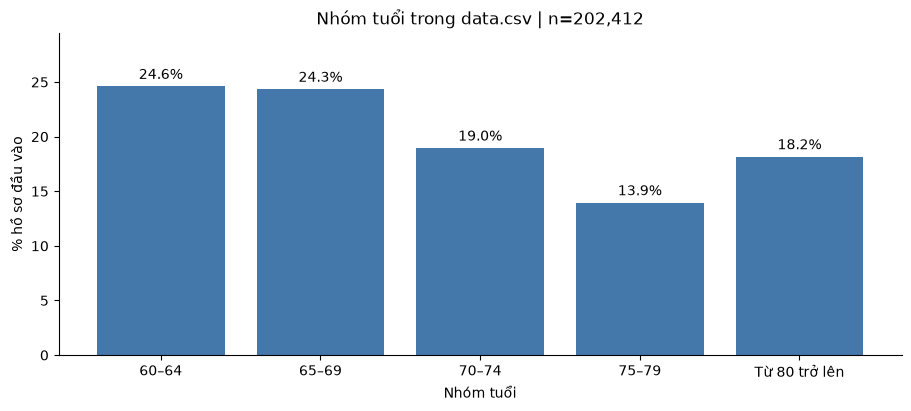

Nhóm ghi nhận nhiều hồ sơ nhất ở tuổi **60–64** (49,794; 24.60%) và ít nhất ở tuổi **75–79** (28,232; 13.95%). Nhóm tính tỷ lệ trên hồ sơ đầu vào, chưa áp dụng trọng số khảo sát.

In [3]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

display(Markdown("#### 1. Tổng quan đầu vào"))
display(pd.DataFrame({"Tệp": ["data.csv"], "Số hồ sơ": [source_shape[0]],
                      "Số cột nguồn": [source_shape[1]], "Số biến ứng viên và nhãn": [len(SOURCE_COLS)]}))
initial_age_labels = {9: "60–64", 10: "65–69", 11: "70–74", 12: "75–79", 13: "Từ 80 trở lên"}
input_age_summary = prep_table('SELECT _AGEG5YR AS Age, COUNT(*) AS n FROM source_data GROUP BY _AGEG5YR ORDER BY _AGEG5YR')
input_age_summary["Nhóm tuổi"] = input_age_summary.Age.map(initial_age_labels)
input_age_summary["Tỷ lệ (%)"] = 100 * input_age_summary.n / source_shape[0]
display(input_age_summary[["Nhóm tuổi", "n", "Tỷ lệ (%)"]].round(2))
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
bars = ax.bar(input_age_summary["Nhóm tuổi"], input_age_summary["Tỷ lệ (%)"], color="#4477AA")
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in input_age_summary["Tỷ lệ (%)"]], padding=3)
ax.set(title=f"Nhóm tuổi trong data.csv | n={source_shape[0]:,}", xlabel="Nhóm tuổi", ylabel="% hồ sơ đầu vào")
ax.set_ylim(0, input_age_summary["Tỷ lệ (%)"].max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
largest_age = input_age_summary.loc[input_age_summary.n.idxmax()]
smallest_age = input_age_summary.loc[input_age_summary.n.idxmin()]
display(Markdown(f"Nhóm ghi nhận nhiều hồ sơ nhất ở tuổi **{largest_age['Nhóm tuổi']}** ({int(largest_age.n):,}; {largest_age['Tỷ lệ (%)']:.2f}%) và ít nhất ở tuổi **{smallest_age['Nhóm tuổi']}** ({int(smallest_age.n):,}; {smallest_age['Tỷ lệ (%)']:.2f}%). Nhóm tính tỷ lệ trên hồ sơ đầu vào, chưa áp dụng trọng số khảo sát."))


In [4]:
display(Markdown("#### 2. Chất lượng 22 biến ứng viên"))
initial_n = len(df_selected_raw)
display(Markdown(f"Nhóm kiểm tra **{initial_n:,} hồ sơ** trước làm sạch, sau khi loại DIABETE3=2."))
special_codes = {
    "DIABETE3": [7, 9], "_RFHYPE5": [9], "TOLDHI2": [7, 9], "_CHOLCHK": [9],
    "_BMI5": [], "SMOKE100": [7, 9], "CVDSTRK3": [7, 9], "_MICHD": [],
    "_TOTINDA": [9], "_FRTLT1": [9], "_VEGLT1": [9], "_RFDRHV5": [9],
    "HLTHPLN1": [7, 9], "MEDCOST": [7, 9], "GENHLTH": [7, 9],
    "MENTHLTH": [77, 99], "PHYSHLTH": [77, 99], "DIFFWALK": [7, 9],
    "SEX": [], "_AGEG5YR": [14], "EDUCA": [9], "INCOME2": [77, 99],
}
quality_rows = []
for col in SOURCE_COLS:
    field = qi(col)
    codes = special_codes[col]
    condition = f'{field} IN ({",".join(map(str, codes))})' if codes else '0'
    values = prep_table(f'SELECT COUNT(*)-COUNT({field}) AS nan_count, COALESCE(SUM({condition}),0) AS special_count FROM raw_scope').iloc[0]
    quality_rows.append({"Biến": col, "NaN": int(values.nan_count), "Mã đặc biệt": int(values.special_count),
                         "NaN (%)": 100 * values.nan_count / initial_n,
                         "Mã đặc biệt (%)": 100 * values.special_count / initial_n})
initial_quality = pd.DataFrame(quality_rows)
display(initial_quality.round(2))
initial_duplicates = duplicate_count('raw_scope', SOURCE_COLS)
display(pd.DataFrame({"Phép kiểm tra": ["Hồ sơ trùng 22 biến, ngoài lần đầu"],
                      "Số hồ sơ": [initial_duplicates], "Tỷ lệ (%)": [100 * initial_duplicates / initial_n]}).round(2))
largest_nan = initial_quality.loc[initial_quality.NaN.idxmax()]
largest_special = initial_quality.loc[initial_quality["Mã đặc biệt"].idxmax()]
display(Markdown(f"Nhóm ghi nhận **{largest_nan['Biến']}** có nhiều NaN nhất ({int(largest_nan.NaN):,}; {largest_nan['NaN (%)']:.2f}%) và **{largest_special['Biến']}** có nhiều mã đặc biệt nhất ({int(largest_special['Mã đặc biệt']):,}; {largest_special['Mã đặc biệt (%)']:.2f}%). Nhóm đếm {initial_duplicates:,} hồ sơ trùng ngoài lần đầu trên 22 biến; nhóm chưa kết luận các hồ sơ này thuộc cùng một người. Nhóm giữ mã 88 của biến số ngày trong câu trả lời hợp lệ và chưa loại hồ sơ ở bước kiểm tra chất lượng."))


#### 2. Chất lượng 22 biến ứng viên

Nhóm kiểm tra **201,596 hồ sơ** trước làm sạch, sau khi loại DIABETE3=2.

,Biến,NaN,Mã đặc biệt,NaN (%),Mã đặc biệt (%)
0,DIABETE3,5,335,0.00,0.17
1,_RFHYPE5,0,695,0.00,0.34
2,TOLDHI2,9412,2154,4.67,1.07
3,_CHOLCHK,0,5755,0.00,2.85
4,_BMI5,13657,0,6.77,0.00
5,SMOKE100,5732,1495,2.84,0.74
6,CVDSTRK3,0,761,0.00,0.38
7,_MICHD,2532,0,1.26,0.00
8,_TOTINDA,0,14940,0.00,7.41
9,_FRTLT1,0,19355,0.00,9.60


,Phép kiểm tra,Số hồ sơ,Tỷ lệ (%)
0,"Hồ sơ trùng 22 biến, ngoài lần đầu",2107,1.05


Nhóm ghi nhận **_BMI5** có nhiều NaN nhất (13,657; 6.77%) và **INCOME2** có nhiều mã đặc biệt nhất (41,283; 20.48%). Nhóm đếm 2,107 hồ sơ trùng ngoài lần đầu trên 22 biến; nhóm chưa kết luận các hồ sơ này thuộc cùng một người. Nhóm giữ mã 88 của biến số ngày trong câu trả lời hợp lệ và chưa loại hồ sơ ở bước kiểm tra chất lượng.

In [5]:
import matplotlib.pyplot as plt
from IPython.display import Markdown

def iqr_summary(frame):
    name,expression=('raw_scope','_BMI5/100.0') if 'clean_sql' not in [r[0] for r in PREP_DB.execute("SELECT name FROM sqlite_master WHERE type='table'")] else ('clean_sql','BMI')
    s=prep_bmi_stats(name,expression)
    return pd.DataFrame({'Q1':[s['q1']],'Q3':[s['q3']],'IQR':[s['q3']-s['q1']],'Biên dưới':[s['lo']],'Biên trên':[s['hi']],'Ngoài biên':[s['outside']],'Ngoài biên (%)':[100*s['outside']/s['n']]},index=['BMI'])


#### 3. Phân bố trước làm sạch
**Mẫu từ 60 tuổi trở lên, đã loại DIABETE3=2: 201,596 dòng × 22 cột.** Các tỷ lệ dùng toàn bộ số dòng làm mẫu số, kể cả NaN. Chia nhóm biến để tránh chênh lệch thang đo; giữ nguyên tỷ lệ thực tế, không cân bằng mẫu. Đây là tỷ lệ trong file, chưa dùng trọng số khảo sát.

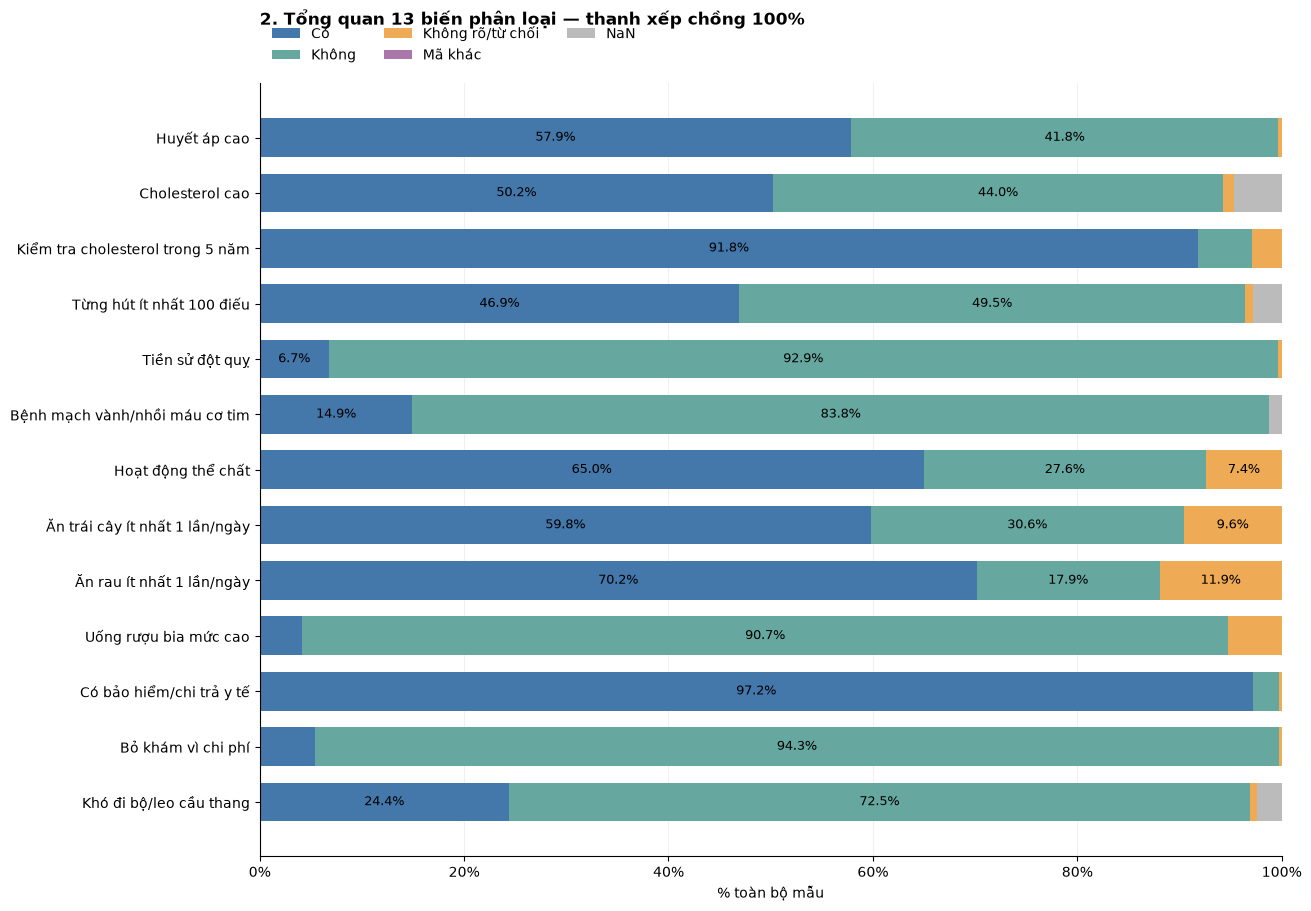

**Tỷ lệ chi tiết (%):** bảng dưới giữ cả nhóm nhỏ không đủ chỗ ghi trên thanh. Giới tính được trình bày bằng biểu đồ tròn riêng bên dưới.

label,Có,Không,Không rõ/từ chối,Mã khác,NaN
Huyết áp cao,57.86,41.80,0.34,0.0,0.00
Cholesterol cao,50.22,44.04,1.07,0.0,4.67
Kiểm tra cholesterol trong 5 năm,91.80,5.34,2.85,0.0,0.00
Từng hút ít nhất 100 điếu,46.91,49.51,0.74,0.0,2.84
Tiền sử đột quỵ,6.73,92.89,0.38,0.0,0.00
Bệnh mạch vành/nhồi máu cơ tim,14.94,83.80,0.00,0.0,1.26
Hoạt động thể chất,64.95,27.64,7.41,0.0,0.00
Ăn trái cây ít nhất 1 lần/ngày,59.80,30.60,9.60,0.0,0.00
Ăn rau ít nhất 1 lần/ngày,70.15,17.91,11.94,0.0,0.00
Uống rượu bia mức cao,4.11,90.67,5.21,0.0,0.00


Nhóm ghi nhận tỷ lệ trả lời có cao nhất ở **Có bảo hiểm/chi trả y tế** (97.15%) và thấp nhất ở **Uống rượu bia mức cao** (4.11%). Nhóm so sánh cơ cấu câu trả lời trong mẫu, chưa dùng các tỷ lệ này để kết luận biến nào dự đoán tốt hơn.

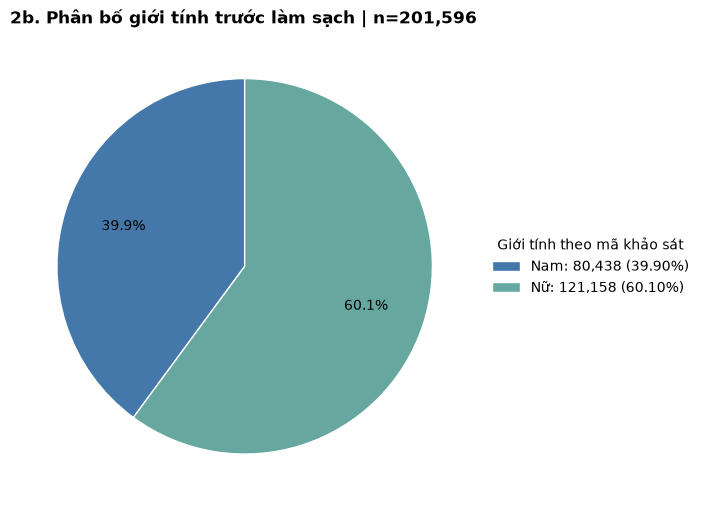

Với **Nhóm tuổi**, nhóm ghi nhận mức **60–64** nhiều nhất: 49,566 hồ sơ (24.59%).

Với **Học vấn**, nhóm ghi nhận mức **Tốt nghiệp CĐ/ĐH ≥4 năm** nhiều nhất: 70,218 hồ sơ (34.83%).

Với **Thu nhập hộ/năm (USD)**, nhóm ghi nhận mức **≥75.000** nhiều nhất: 39,006 hồ sơ (19.35%).

Với **Tự đánh giá sức khỏe**, nhóm ghi nhận mức **Tốt** nhiều nhất: 65,327 hồ sơ (32.40%).

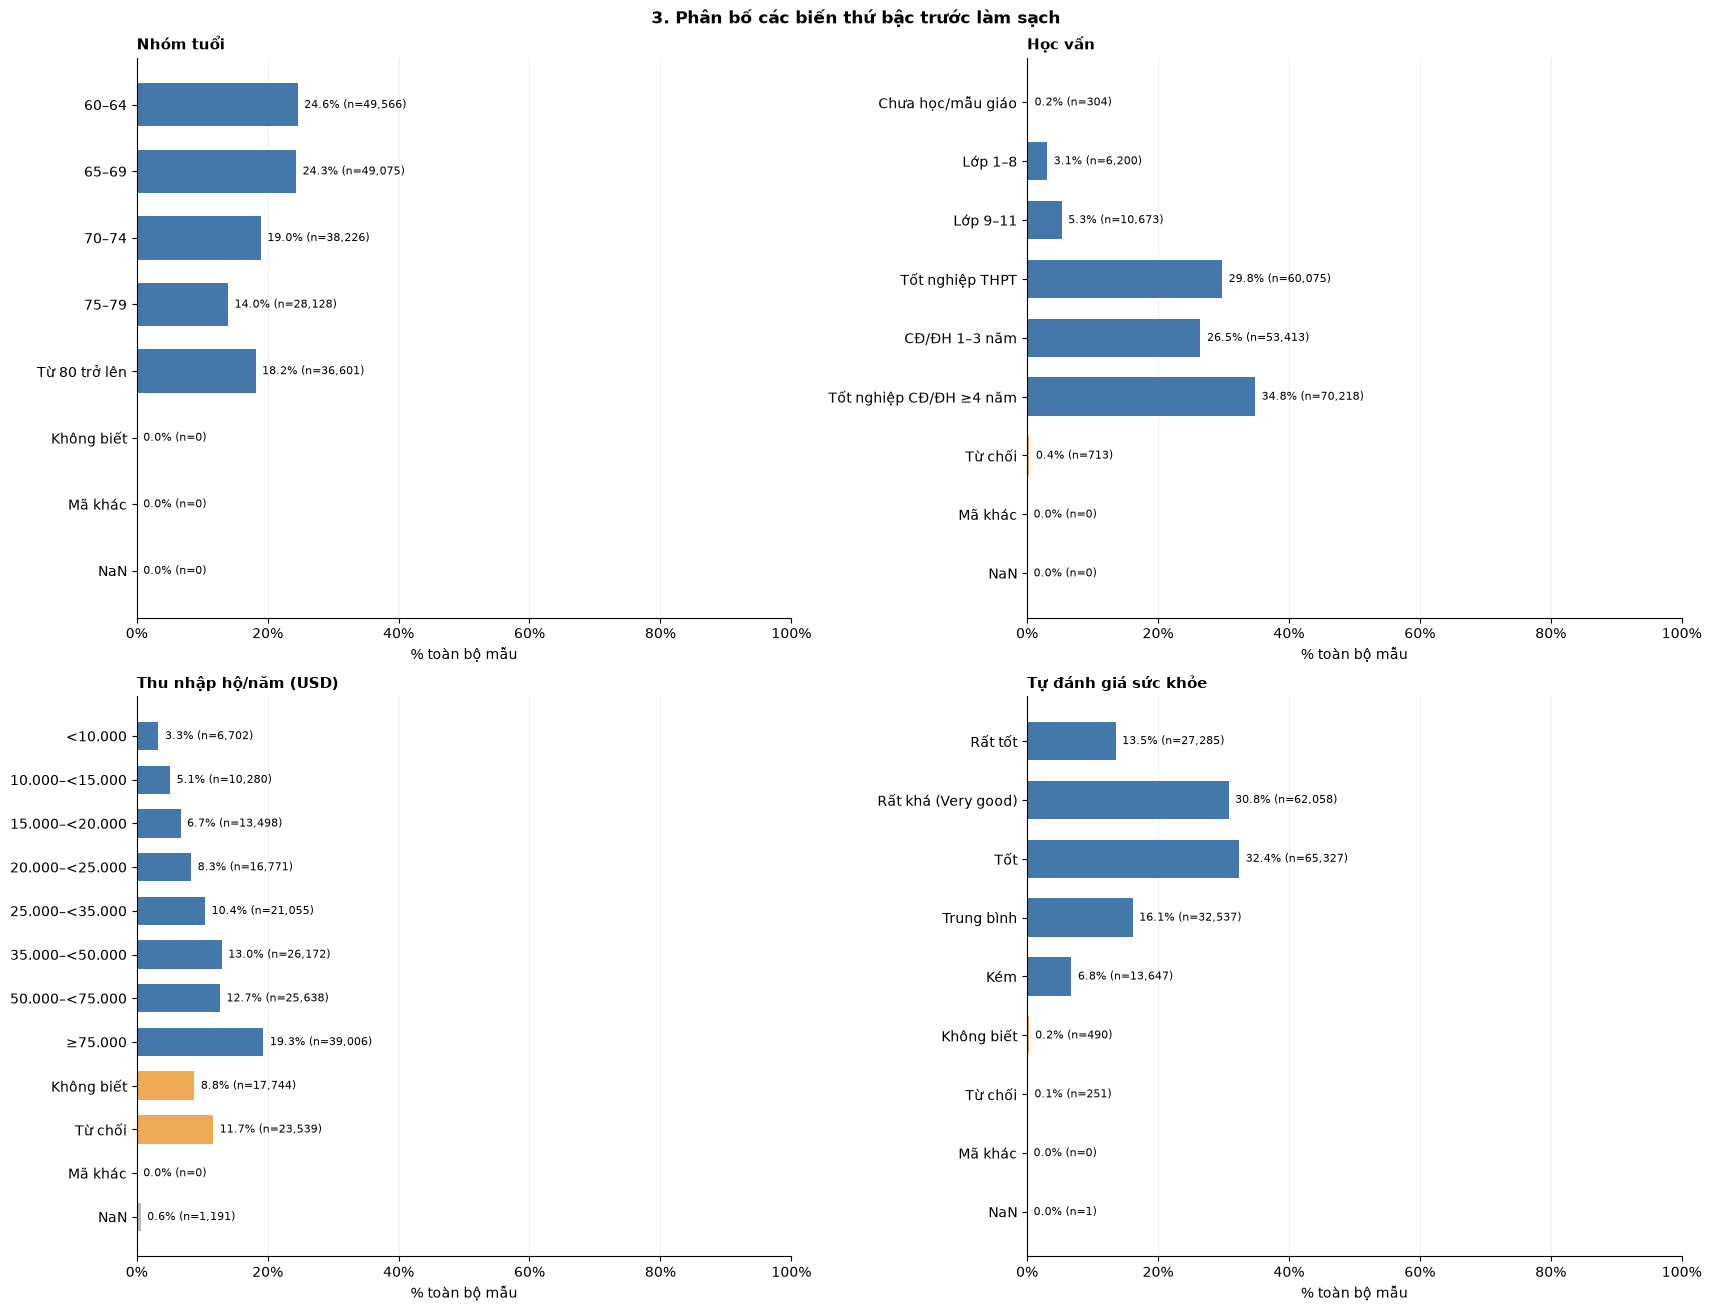

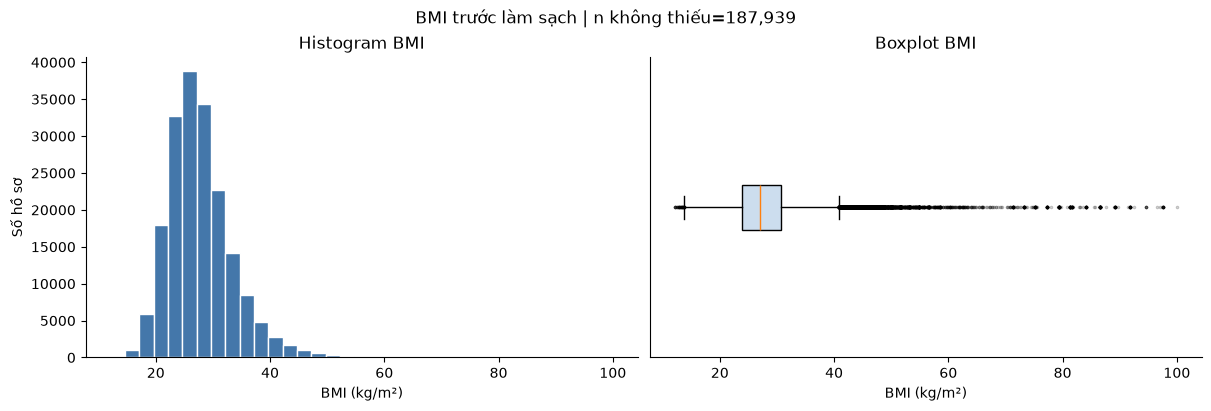

Nhóm ghi nhận BMI trung vị **26.96 kg/m²**, khoảng tứ phân vị **23.91–30.67** và **5,705 hồ sơ ngoài biên IQR**. Nhóm giữ phần thập phân và các điểm ngoài biên khi mô tả; nhóm chưa xem điểm ngoài biên là dữ liệu sai.

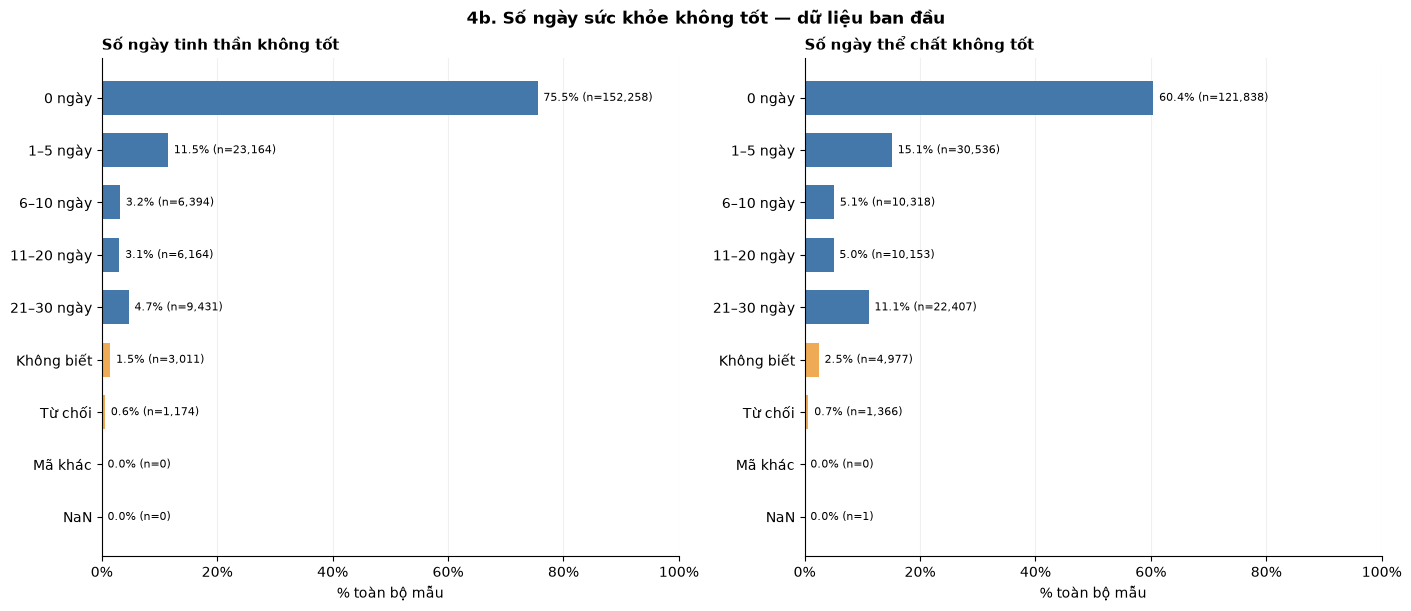

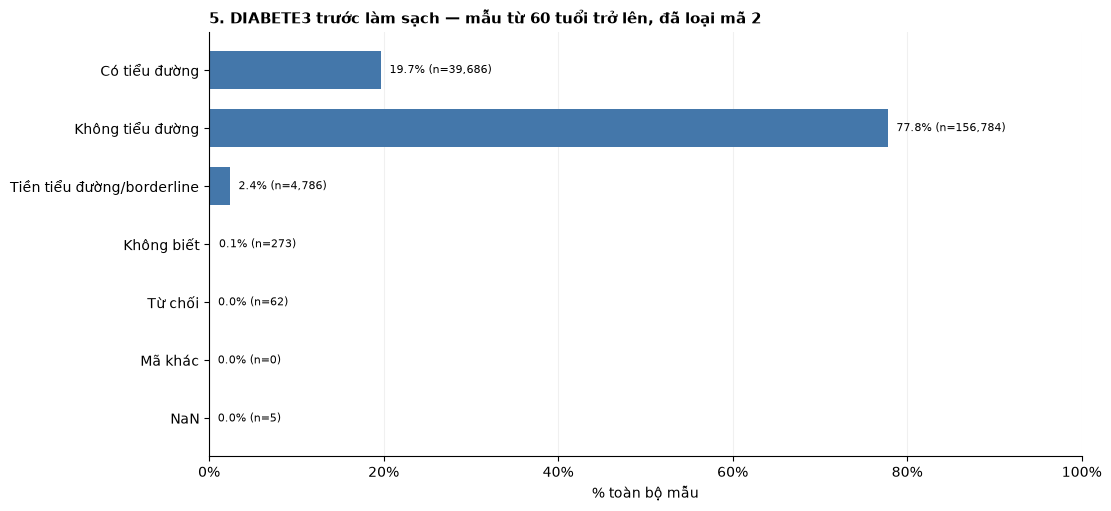

,Số hồ sơ,Tỷ lệ (%)
label,,
Có tiểu đường,39686,19.69
Không tiểu đường,156784,77.77
Tiền tiểu đường/borderline,4786,2.37
Không biết,273,0.14
Từ chối,62,0.03
Mã khác,0,0.00
NaN,5,0.00


Nhóm ghi nhận **39,686** hồ sơ mã 1 và **4,786** hồ sơ mã 4. Nhóm giữ hai mức này riêng ở bước khám phá; nhóm sẽ gộp chúng thành lớp 1 trong phần tiền xử lý.

**Cách đọc:** thanh 100% giúp so sánh cơ cấu các biến; các nhóm ít mẫu vẫn được giữ và ghi trong bảng tỷ lệ. NaN và mã không biết/từ chối là hai loại khác nhau. BMI chia 100 và giữ phần thập phân; boxplot hiển thị điểm ngoài biên IQR. 88 ở số ngày được hiển thị là 0 ngày. **Ô vẽ không thay đổi mẫu đã chọn, không sửa dữ liệu nguồn và không cân bằng lại các lớp.**

In [6]:
# TỔNG QUAN DỮ LIỆU BAN ĐẦU — MỤC 2.2
# Chỉ đổi nhãn/đơn vị để hiển thị; không sửa df_selected_raw.
def plot_initial_bmi_boxplot(raw):
    bmi = prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope WHERE _BMI5 IS NOT NULL ORDER BY _source_row')['BMI']
    if bmi.empty:
        raise ValueError("Mẫu nghiên cứu không có BMI để vẽ.")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    axes[0].hist(bmi, bins=35, color="#4477AA", edgecolor="white")
    axes[0].set(title="Histogram BMI", xlabel="BMI (kg/m²)", ylabel="Số hồ sơ")
    axes[1].boxplot(bmi, orientation="horizontal", patch_artist=True,
                    boxprops={"facecolor": "#CCDDEE"},
                    flierprops={"marker": ".", "markersize": 3, "alpha": .25})
    axes[1].set(title="Boxplot BMI", xlabel="BMI (kg/m²)", yticks=[])
    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"BMI trước làm sạch | n không thiếu={len(bmi):,}")
    plt.show()
    stats = prep_bmi_stats('raw_scope', '_BMI5/100.0')
    display(Markdown(f"Nhóm ghi nhận BMI trung vị **{stats['median']:.2f} kg/m²**, khoảng tứ phân vị **{stats['q1']:.2f}–{stats['q3']:.2f}** và **{int(stats['outside']):,} hồ sơ ngoài biên IQR**. Nhóm giữ phần thập phân và các điểm ngoài biên khi mô tả; nhóm chưa xem điểm ngoài biên là dữ liệu sai."))


def plot_initial_overview(raw):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter
    from IPython.display import display, Markdown

    n = len(raw)
    if n == 0:
        raise ValueError('Dữ liệu ban đầu chưa có dòng nào.')
    blue, teal, orange, gray = '#4477AA', '#66A89F', '#EEAA55', '#BBBBBB'
    display(Markdown(
        '#### 3. Phân bố trước làm sạch\n'
        f'**Mẫu từ 60 tuổi trở lên, đã loại DIABETE3=2: {n:,} dòng × {raw.shape[1]} cột.** '
        'Các tỷ lệ dùng toàn bộ số dòng làm mẫu số, kể cả NaN. '
        'Chia nhóm biến để tránh chênh lệch thang đo; giữ nguyên tỷ lệ thực tế, '
        'không cân bằng mẫu. Đây là tỷ lệ trong file, chưa dùng trọng số khảo sát.'))

    def style(ax, horizontal=False):
        ax.set_axisbelow(True)
        axis = 'x' if horizontal else 'y'
        ax.grid(axis=axis, alpha=.18)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(PercentFormatter(100))

    def distribution(series, mapping):
        return prep_distribution(series,mapping)

    def barh(ax, counts, title):
        pct = counts / n * 100
        colors = [gray if k == 'NaN' else orange if k in
                  ['Không biết', 'Từ chối', 'Mã khác'] else blue for k in counts.index]
        bars = ax.barh(counts.index, pct, color=colors, height=.65)
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_title(title, loc='left', fontsize=11, fontweight='bold')
        ax.set_xlabel('% toàn bộ mẫu')
        for b, p, count in zip(bars, pct, counts):
            ax.text(min(p + 1, 97), b.get_y()+b.get_height()/2,
                    f'{p:.1f}% (n={count:,})', va='center', fontsize=8,
                    ha='right' if p > 94 else 'left')
        style(ax, True)

    with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10}):
        # 2. Các biến phân loại. Mã nguồn được đọc theo từng biến.
        specs = [
            ('_RFHYPE5', 'Huyết áp cao', {1:'Không', 2:'Có', 9:'Không rõ/từ chối'}),
            ('TOLDHI2', 'Cholesterol cao', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('_CHOLCHK', 'Kiểm tra cholesterol trong 5 năm', {1:'Có', 2:'Không', 3:'Không', 9:'Không rõ/từ chối'}),
            ('SMOKE100', 'Từng hút ít nhất 100 điếu', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('CVDSTRK3', 'Tiền sử đột quỵ', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('_MICHD', 'Bệnh mạch vành/nhồi máu cơ tim', {1:'Có', 2:'Không'}),
            ('_TOTINDA', 'Hoạt động thể chất', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_FRTLT1', 'Ăn trái cây ít nhất 1 lần/ngày', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_VEGLT1', 'Ăn rau ít nhất 1 lần/ngày', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_RFDRHV5', 'Uống rượu bia mức cao', {1:'Không', 2:'Có', 9:'Không rõ/từ chối'}),
            ('HLTHPLN1', 'Có bảo hiểm/chi trả y tế', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('MEDCOST', 'Bỏ khám vì chi phí', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('DIFFWALK', 'Khó đi bộ/leo cầu thang', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'})]
        categories = ['Có', 'Không', 'Không rõ/từ chối', 'Mã khác', 'NaN']
        rows = []
        for col, title, mapping in specs:
            rows.append(prep_distribution(raw[col],mapping,categories)/n*100)
        table = pd.DataFrame(rows, index=[title for _, title, _ in specs])
        fig, ax = plt.subplots(figsize=(13, 9), layout='constrained')
        left = np.zeros(len(table))
        for category, color in zip(categories, [blue, teal, orange, '#AA77AA', gray]):
            widths = table[category].to_numpy()
            ax.barh(table.index, widths, left=left, color=color, label=category, height=.7)
            for y, (start, width) in enumerate(zip(left, widths)):
                if width >= 6:
                    ax.text(start+width/2, y, f'{width:.1f}%', ha='center', va='center', fontsize=9)
            left += widths
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_xlabel('% toàn bộ mẫu')
        ax.set_title('2. Tổng quan 13 biến phân loại — thanh xếp chồng 100%',
                     loc='left', fontweight='bold', pad=42)
        ax.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.01), frameon=False)
        style(ax, True)
        plt.show()
        display(Markdown('**Tỷ lệ chi tiết (%):** bảng dưới giữ cả nhóm nhỏ không đủ chỗ ghi trên thanh. '
                         'Giới tính được trình bày bằng biểu đồ tròn riêng bên dưới.'))
        display(table.round(2))
        highest = table['Có'].idxmax()
        lowest = table['Có'].idxmin()
        display(Markdown(f"Nhóm ghi nhận tỷ lệ trả lời có cao nhất ở **{highest}** ({table.loc[highest, 'Có']:.2f}%) và thấp nhất ở **{lowest}** ({table.loc[lowest, 'Có']:.2f}%). Nhóm so sánh cơ cấu câu trả lời trong mẫu, chưa dùng các tỷ lệ này để kết luận biến nào dự đoán tốt hơn."))

        # 2b. Giới tính tách riêng thành biểu đồ tròn, giữ cả NaN/mã khác.
        sex_counts = distribution(raw['SEX'], {1:'Nam', 2:'Nữ', 9:'Không rõ/từ chối'})
        sex_counts = sex_counts[sex_counts > 0]
        sex_palette = {'Nam':blue, 'Nữ':teal, 'Không rõ/từ chối':orange,
                       'Mã khác':'#AA77AA', 'NaN':gray}
        fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
        wedges, _, _ = ax.pie(sex_counts.values,
            colors=[sex_palette[k] for k in sex_counts.index], startangle=90,
            autopct=lambda p: f'{p:.1f}%' if p >= 1 else '',
            pctdistance=.68, wedgeprops={'edgecolor':'white', 'linewidth':1})
        ax.legend(wedges, [f'{k}: {v:,} ({v/n*100:.2f}%)'
                          for k,v in sex_counts.items()],
                  title='Giới tính theo mã khảo sát', loc='center left',
                  bbox_to_anchor=(1, .5), frameon=False)
        ax.set_title(f'2b. Phân bố giới tính trước làm sạch | n={n:,}',
                     loc='left', fontweight='bold')
        ax.set_aspect('equal')
        plt.show()

        # 3. Biến thứ bậc, giữ đúng thứ tự và tách mã phản hồi.
        age = ['60–64','65–69','70–74','75–79','Từ 80 trở lên']
        ordinal = [
            ('_AGEG5YR', 'Nhóm tuổi', {**dict(enumerate(age, 9)), 14:'Không biết'}),
            ('EDUCA', 'Học vấn', {1:'Chưa học/mẫu giáo', 2:'Lớp 1–8', 3:'Lớp 9–11',
                4:'Tốt nghiệp THPT', 5:'CĐ/ĐH 1–3 năm', 6:'Tốt nghiệp CĐ/ĐH ≥4 năm', 9:'Từ chối'}),
            ('INCOME2', 'Thu nhập hộ/năm (USD)', {1:'<10.000', 2:'10.000–<15.000',
                3:'15.000–<20.000', 4:'20.000–<25.000', 5:'25.000–<35.000',
                6:'35.000–<50.000', 7:'50.000–<75.000', 8:'≥75.000', 77:'Không biết', 99:'Từ chối'}),
            ('GENHLTH', 'Tự đánh giá sức khỏe', {1:'Rất tốt', 2:'Rất khá (Very good)',
                3:'Tốt', 4:'Trung bình', 5:'Kém', 7:'Không biết', 9:'Từ chối'})]
        fig, axes = plt.subplots(2, 2, figsize=(17, 13), layout='constrained')
        fig.suptitle('3. Phân bố các biến thứ bậc trước làm sạch', fontweight='bold')
        for ax, (col, title, mapping) in zip(axes.flat, ordinal):
            counts = distribution(raw[col], mapping)
            barh(ax, counts, title)
            most = counts.idxmax()
            display(Markdown(f"Với **{title}**, nhóm ghi nhận mức **{most}** nhiều nhất: {int(counts.loc[most]):,} hồ sơ ({100*counts.loc[most]/n:.2f}%)."))
        plt.show()

        # 4a. Boxplot BMI: giữ toàn bộ miền và vẽ các điểm ngoài biên.
        plot_initial_bmi_boxplot(raw)

        # 4b. Hai biểu đồ số ngày giữ cách đếm và giải mã hiện tại.
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
        days_mapping = {0:'0 ngày', 88:'0 ngày',
                        **{i:'1–5 ngày' for i in range(1, 6)},
                        **{i:'6–10 ngày' for i in range(6, 11)},
                        **{i:'11–20 ngày' for i in range(11, 21)},
                        **{i:'21–30 ngày' for i in range(21, 31)},
                        77:'Không biết', 99:'Từ chối'}
        for ax, col, title in zip(axes, ['MENTHLTH', 'PHYSHLTH'],
                                  ['Số ngày tinh thần không tốt', 'Số ngày thể chất không tốt']):
            barh(ax, distribution(raw[col], days_mapping), title)
        fig.suptitle('4b. Số ngày sức khỏe không tốt — dữ liệu ban đầu', fontweight='bold')
        plt.show()

        # 5. Nhãn gốc: chưa gộp Diabetes_binary.
        target_map = {1:'Có tiểu đường', 3:'Không tiểu đường',
                      4:'Tiền tiểu đường/borderline', 7:'Không biết', 9:'Từ chối'}
        fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
        barh(ax, distribution(raw['DIABETE3'], target_map),
             '5. DIABETE3 trước làm sạch — mẫu từ 60 tuổi trở lên, đã loại mã 2')
        plt.show()
        target_counts = distribution(raw['DIABETE3'], target_map)
        target_table = target_counts.rename('Số hồ sơ').to_frame()
        target_table['Tỷ lệ (%)'] = 100 * target_counts / n
        display(target_table.round(2))
        display(Markdown(f"Nhóm ghi nhận **{int(target_counts.get('Có tiểu đường', 0)):,}** hồ sơ mã 1 và **{int(target_counts.get('Tiền tiểu đường/borderline', 0)):,}** hồ sơ mã 4. Nhóm giữ hai mức này riêng ở bước khám phá; nhóm sẽ gộp chúng thành lớp 1 trong phần tiền xử lý."))
        display(Markdown('**Cách đọc:** thanh 100% giúp so sánh cơ cấu các biến; '
            'các nhóm ít mẫu vẫn được giữ và ghi trong bảng tỷ lệ. '
            'NaN và mã không biết/từ chối là hai loại khác nhau. '
            'BMI chia 100 và giữ phần thập phân; boxplot hiển thị điểm ngoài biên IQR. 88 ở số ngày được hiển thị là 0 ngày. '
            '**Ô vẽ không thay đổi mẫu đã chọn, không sửa dữ liệu nguồn và không cân bằng lại các lớp.**'))

plot_initial_overview(df_selected_raw)


### Nhận xét từ bước khám phá

Nhóm đặt nhận xét theo số liệu cạnh bảng chất lượng và các biểu đồ. Nhóm dùng năm nhóm tuổi mã 9–13, giữ nhãn DIABETE3 gốc và phân biệt NaN với mã không biết/từ chối. Nhóm giữ BMI dạng số thập phân sau khi chia 100. Nhóm sẽ quyết định cách xử lý giá trị thiếu, hồ sơ trùng và ngoại lệ ở phần tiền xử lý.

Nhóm mô tả tỷ lệ trong mẫu, chưa áp dụng trọng số khảo sát hoặc suy luận quan hệ nhân quả.


# III. Làm sạch và tiền xử lý dữ liệu

SQLite thực hiện lọc, đổi mã, kiểm tra missing/duplicate, kiểm tra miền giá trị và tổng hợp trước/sau. Python đọc CSV, chuyển kết quả SQL thành dữ liệu vẽ, giữ BMI dạng float64, ép nhãn cùng 14 biến nhị phân sang boolean và giữ Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16 khi chuyển kết quả thành DataFrame và kiểm tra đối chiếu. Sau phần này kết nối được đóng; toàn bộ EDA, chia tập, feature engineering, huấn luyện và đánh giá dùng pandas/NumPy cùng các thư viện mô hình.


#### CHECK DUPLICATE DATA

Nhóm kiểm tra hồ sơ trùng để mô tả dữ liệu và giữ các hồ sơ trùng trong tập phân tích. Hai người tham gia có thể trả lời giống nhau trên 22 biến, nên nhóm chưa có căn cứ xác định các hồ sơ đó thuộc cùng một người. Nhóm dùng một bộ dữ liệu sau làm sạch cho các bước tiếp theo.


In [7]:
for name,cols in [('source_data',source_columns),('selected_all',SOURCE_COLS),('raw_scope',SOURCE_COLS)]:
    print(name, 'duplicate ngoài lần đầu:', duplicate_count(name,cols))
scope_query="""SELECT _AGEG5YR AS Age,COUNT(*) AS n,
SUM(DIABETE3 IN (1,4)) AS positive_count
FROM raw_scope GROUP BY _AGEG5YR ORDER BY _AGEG5YR"""
print(scope_query);display(prep_table(scope_query))


source_data duplicate ngoài lần đầu: 0
selected_all duplicate ngoài lần đầu: 2107
raw_scope duplicate ngoài lần đầu: 2107
SELECT _AGEG5YR AS Age,COUNT(*) AS n,
SUM(DIABETE3 IN (1,4)) AS positive_count
FROM raw_scope GROUP BY _AGEG5YR ORDER BY _AGEG5YR


,Age,n,positive_count
0,9.0,49566,9644
1,10.0,49075,11125
2,11.0,38226,9353
3,12.0,28128,6856
4,13.0,36601,7494


**Nhận xét (Mục 3.1):** Nhóm ghi nhận 2.107 hồ sơ trùng ngoài lần đầu trên 22 biến trước làm sạch. Sau làm sạch, nhóm giữ 121.839 hồ sơ, gồm 1.277 hồ sơ trùng ngoài lần đầu. Nhóm giữ các hồ sơ này theo quyết định của đề tài.


#### CHECK & HANDLE MISSING VALUES

**Phương án nhóm đã chốt:** Nhóm giữ quy trình loại dòng có NaN trên 22 biến gồm 21 đặc trưng và nhãn. Sau bước này, nhóm loại các hồ sơ mang mã không biết/từ chối theo quy tắc riêng của từng biến. Nhóm không điền mean, median hoặc mode; nhóm giữ nguyên mã phản hồi cho đến bước xử lý của biến tương ứng.

Nhóm chọn phân tích các hồ sơ có đủ câu trả lời hợp lệ theo bộ biến đã xác định. Nhóm thống kê số ô NaN, số dòng thiếu và số hồ sơ loại ở từng bước để báo cáo mức mất mẫu. Nhóm chưa khẳng định cách xử lý này là phương án tối ưu hoặc bảo đảm tính đại diện của mẫu.

Nhóm giữ mã 88 của MENTHLTH/PHYSHLTH như câu trả lời hợp lệ và chuyển thành 0 ngày. Nhóm giữ BMI thập phân sau khi chia 100 và giữ hồ sơ trùng sau làm sạch.

**Phạm vi đếm:** Nhóm bắt đầu từ 201.596 hồ sơ từ 60 tuổi trở lên sau khi loại DIABETE3=2. Trong nhật ký xử lý, nhóm đếm một hồ sơ ở bước đầu tiên loại hồ sơ đó. Vì vậy, số dòng loại ở mỗi bước phụ thuộc thứ tự xử lý; người đọc cần phân biệt số này với tổng số mã không hợp lệ của biến trên mẫu ban đầu.

**Phân biệt bước minh họa:** Bảng ngay dưới chỉ thử lọc NaN ở bốn biến để cho thấy vẫn còn thiếu ở các biến khác. Nhóm tạo bảng phụ `drop4`, không dùng bảng này làm đầu vào mô hình. Nhóm bắt đầu quy trình làm sạch chính từ `raw_scope` và loại dòng thiếu trên cả 22 cột ở cell kế tiếp.


In [8]:
nan_drop_columns=['TOLDHI2','_BMI5','SMOKE100','_MICHD']
PREP_DB.execute('CREATE TABLE drop4 AS SELECT * FROM raw_scope WHERE '+' AND '.join(qi(c)+' IS NOT NULL' for c in nan_drop_columns))
remaining_nan_columns=[c for c in SOURCE_COLS if c not in nan_drop_columns]
remaining_nan_summary=missing_table('drop4',remaining_nan_columns)
display(remaining_nan_summary)
print('Trước/sau lọc bốn biến:',prep_scalar('SELECT COUNT(*) FROM raw_scope'),prep_scalar('SELECT COUNT(*) FROM drop4'))
print('Dòng còn NaN:',prep_scalar('SELECT COUNT(*) FROM drop4 WHERE '+' OR '.join(qi(c)+' IS NULL' for c in remaining_nan_columns)))


Trước/sau lọc bốn biến: 201596 174792
Dòng còn NaN: 9


,Feature,missing_count,missing_percent
0,DIABETE3,5,0.002861
1,_RFHYPE5,0,0.000000
2,_CHOLCHK,0,0.000000
3,CVDSTRK3,0,0.000000
4,_TOTINDA,0,0.000000
5,_FRTLT1,0,0.000000
6,_VEGLT1,0,0.000000
7,_RFDRHV5,0,0.000000
8,HLTHPLN1,0,0.000000
9,MEDCOST,1,0.000572


In [9]:
missing_summary=missing_table('raw_scope',SOURCE_COLS).set_index('Feature').rename(columns={'missing_count':'Số ô NaN','missing_percent':'Tỷ lệ NaN (%)'}).sort_values('Số ô NaN',ascending=False)
display(missing_summary)
PREP_DB.execute('CREATE TABLE clean_work AS SELECT * FROM raw_scope')
audit_rows=[]
def sql_clean_step(label,condition='1=1',column=None,expression=None):
    before=prep_scalar('SELECT COUNT(*) FROM clean_work')
    if column is not None and expression is not None: PREP_DB.execute(f'UPDATE clean_work SET {qi(column)}={expression}')
    PREP_DB.execute(f'DELETE FROM clean_work WHERE NOT ({condition})')
    after=prep_scalar('SELECT COUNT(*) FROM clean_work')
    audit_rows.append([label,before,before-after,after])
sql_clean_step('NaN',' AND '.join(qi(c)+' IS NOT NULL' for c in SOURCE_COLS))
sql_clean_step('DIABETE3','"DIABETE3" NOT IN (7,9)','DIABETE3','CASE "DIABETE3" WHEN 3 THEN 0 WHEN 1 THEN 1 WHEN 4 THEN 1 ELSE "DIABETE3" END')
sql_clean_step('_RFHYPE5','"_RFHYPE5" NOT IN (9)','_RFHYPE5','CASE "_RFHYPE5" WHEN 1 THEN 0 WHEN 2 THEN 1 ELSE "_RFHYPE5" END')
sql_clean_step('TOLDHI2','"TOLDHI2" NOT IN (7,9)','TOLDHI2','CASE "TOLDHI2" WHEN 2 THEN 0 ELSE "TOLDHI2" END')
sql_clean_step('_CHOLCHK','"_CHOLCHK" NOT IN (9)','_CHOLCHK','CASE "_CHOLCHK" WHEN 3 THEN 0 WHEN 2 THEN 0 ELSE "_CHOLCHK" END')
sql_clean_step('_BMI5','1=1','_BMI5','_BMI5/100.0')
sql_clean_step('SMOKE100','"SMOKE100" NOT IN (7,9)','SMOKE100','CASE "SMOKE100" WHEN 2 THEN 0 ELSE "SMOKE100" END')
sql_clean_step('CVDSTRK3','"CVDSTRK3" NOT IN (7,9)','CVDSTRK3','CASE "CVDSTRK3" WHEN 2 THEN 0 ELSE "CVDSTRK3" END')
sql_clean_step('_MICHD','1=1','_MICHD','CASE "_MICHD" WHEN 2 THEN 0 ELSE "_MICHD" END')
sql_clean_step('_TOTINDA','"_TOTINDA" NOT IN (9)','_TOTINDA','CASE "_TOTINDA" WHEN 2 THEN 0 ELSE "_TOTINDA" END')
sql_clean_step('_FRTLT1','"_FRTLT1" NOT IN (9)','_FRTLT1','CASE "_FRTLT1" WHEN 2 THEN 0 ELSE "_FRTLT1" END')
sql_clean_step('_VEGLT1','"_VEGLT1" NOT IN (9)','_VEGLT1','CASE "_VEGLT1" WHEN 2 THEN 0 ELSE "_VEGLT1" END')
sql_clean_step('_RFDRHV5','"_RFDRHV5" NOT IN (9)','_RFDRHV5','CASE "_RFDRHV5" WHEN 1 THEN 0 WHEN 2 THEN 1 ELSE "_RFDRHV5" END')
sql_clean_step('HLTHPLN1','"HLTHPLN1" NOT IN (7,9)','HLTHPLN1','CASE "HLTHPLN1" WHEN 2 THEN 0 ELSE "HLTHPLN1" END')
sql_clean_step('MEDCOST','"MEDCOST" NOT IN (7,9)','MEDCOST','CASE "MEDCOST" WHEN 2 THEN 0 ELSE "MEDCOST" END')
sql_clean_step('GENHLTH','"GENHLTH" NOT IN (7,9)','GENHLTH',None)
sql_clean_step('MENTHLTH','"MENTHLTH" NOT IN (77,99)','MENTHLTH','CASE "MENTHLTH" WHEN 88 THEN 0 ELSE "MENTHLTH" END')
sql_clean_step('PHYSHLTH','"PHYSHLTH" NOT IN (77,99)','PHYSHLTH','CASE "PHYSHLTH" WHEN 88 THEN 0 ELSE "PHYSHLTH" END')
sql_clean_step('DIFFWALK','"DIFFWALK" NOT IN (7,9)','DIFFWALK','CASE "DIFFWALK" WHEN 2 THEN 0 ELSE "DIFFWALK" END')
sql_clean_step('SEX','1=1','SEX','CASE "SEX" WHEN 2 THEN 0 ELSE "SEX" END')
sql_clean_step('_AGEG5YR','"_AGEG5YR" NOT IN (14)','_AGEG5YR',None)
sql_clean_step('EDUCA','"EDUCA" NOT IN (9)','EDUCA',None)
sql_clean_step('INCOME2','"INCOME2" NOT IN (77,99)','INCOME2',None)
PREP_DB.commit()
brfss_df_selected=prep_frame('clean_work')
display(pd.DataFrame(audit_rows,columns=['step','before','removed','after']))


,Số ô NaN,Tỷ lệ NaN (%)
Feature,,
_BMI5,13657,6.774440
TOLDHI2,9412,4.668743
SMOKE100,5732,2.843310
DIFFWALK,4962,2.461358
_MICHD,2532,1.255977
INCOME2,1191,0.590786
DIABETE3,5,0.002480
PHYSHLTH,1,0.000496
GENHLTH,1,0.000496


,step,before,removed,after
0,NaN,201596,26813,174783
1,DIABETE3,174783,217,174566
2,_RFHYPE5,174566,461,174105
3,TOLDHI2,174105,1734,172371
4,_CHOLCHK,172371,2386,169985
5,_BMI5,169985,0,169985
6,SMOKE100,169985,1057,168928
7,CVDSTRK3,168928,501,168427
8,_MICHD,168427,0,168427
9,_TOTINDA,168427,6859,161568


**Kết quả thực thi (Mục 3.2):** Trong 201.596 hồ sơ trước làm sạch, nhóm đếm 37.494 ô NaN trên 26.813 hồ sơ. Sau khi loại dòng có NaN trên 22 biến, nhóm còn 174.783 hồ sơ. Qua các bước xử lý mã khảo sát, nhóm loại thêm 52.944 hồ sơ và giữ 121.839 hồ sơ. Tổng số hồ sơ giảm 39,56% so với mẫu trước làm sạch.

Nhóm đã chốt và chạy quy tắc: loại dòng thiếu, loại các mã không biết/từ chối theo từng biến, chuyển mã 88 của số ngày thành 0 và gộp nhãn 1/4 thành lớp dương. Nhóm giữ BMI thập phân và chưa điền giá trị thiếu. Trong nhật ký, nhóm đếm một hồ sơ ở bước đầu tiên loại hồ sơ đó.

Nhóm cần xem xét thiên lệch chọn mẫu khi loại dòng thiếu. Với HighChol, nhóm cần phân biệt thiếu do nhánh câu hỏi với câu trả lời không có cholesterol cao. Nhóm giữ phương án này và nêu mức mất mẫu 39,56% khi trình bày giới hạn nghiên cứu.


#### DATA TYPE CASTING & FORMAT STANDARDIZATION

Nhóm chuyển mã theo định nghĩa của từng biến trong từ điển dữ liệu. Nhóm kiểm tra giá trị thiếu, tính hữu hạn và miền hợp lệ trước khi chuyển kiểu. Nhóm giữ BMI dạng float64 để bảo toàn phần thập phân; nhóm lưu nhãn cùng 14 biến nhị phân dạng boolean và giữ Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16. Sau chuyển kiểu, nhóm đối chiếu các giá trị với dữ liệu trước chuyển đổi và kiểm tra nhãn theo DIABETE3 nguồn.

| Nhóm biến | Quy tắc nhóm áp dụng |
|---|---|
| Nhãn tiểu đường | Nhóm gộp DIABETE3=1/4 thành lớp 1 và chuyển mã 3 thành lớp 0; nhóm đã loại mã 2 ở bước chọn mẫu. |
| Biến nhị phân | Nhóm chuyển về 0/1 theo ý nghĩa từng biến. Với HighBP, nhóm chuyển mã nguồn 1→0 và 2→1; với HighChol, nhóm giữ 1→1 và chuyển 2→0. |
| Kiểu dữ liệu nhãn và biến nhị phân | Nhóm ép Diabetes_binary và 14 biến nhị phân sang boolean ngay tại bước này: 0 → False, 1 → True. |
| Số ngày sức khỏe kém | Nhóm chuyển mã 88 thành 0 ngày và giữ các giá trị hợp lệ từ 1 đến 30, lưu dạng int16. |
| BMI | Nhóm chia _BMI5 cho 100, giữ phần thập phân và lưu dạng float64. |
| Biến thứ bậc | Nhóm giữ mã Age 9–13, Education 1–6, Income 1–8 và GenHlth 1–5, lưu dạng int16. |

Nhóm áp dụng quy tắc chuyển mã riêng cho từng cột. Người đọc cần tra ý nghĩa của mã nguồn trước khi diễn giải có/không. Với Age và Income, nhóm dùng số để biểu diễn nhóm tuổi và khoảng thu nhập: Age=9 tương ứng 60–64 tuổi; Income=6 tương ứng thu nhập hộ từ 35.000 đến dưới 50.000 USD/năm. Nhóm sẽ trình bày cách mã hóa các biến thứ bậc cho từng mô hình tại phần chuẩn bị đặc trưng.


In [10]:
valid_ranges={'GenHlth':(1,5),'MentHlth':(0,30),'PhysHlth':(0,30),'Age':(9,13),'Education':(1,6),'Income':(1,8)}
select=', '.join(qi(old)+' AS '+qi(new) for old,new in rename_dict.items())
PREP_DB.execute('CREATE TABLE clean_sql AS SELECT _source_row,'+select+' FROM clean_work')
check_rows=[]
for col in rename_dict.values():
    field=qi(col)
    domain=f'{field} BETWEEN {valid_ranges[col][0]} AND {valid_ranges[col][1]}' if col in valid_ranges else (f'{field}>0' if col=='BMI' else f'{field} IN (0,1)')
    fractional = '0' if col == 'BMI' else f'SUM({field}!=CAST({field} AS INTEGER))'
    check_rows.append(prep_table(f"SELECT ? AS 'Biến',SUM({field} IS NULL) AS Missing,SUM({field} IS NOT NULL AND ABS({field})>1.7976931348623157e308) AS 'Non-finite',{fractional} AS 'Phần thập phân không hợp lệ',SUM(NOT ({domain})) AS 'Vi phạm logic/Khoảng' FROM clean_sql",(col,)))
validity_summary=pd.concat(check_rows,ignore_index=True)
display(validity_summary)
total_errors=int(validity_summary.iloc[:,1:].to_numpy().sum());assert total_errors==0
assert prep_scalar('SELECT COUNT(*) FROM clean_sql WHERE '+' OR '.join(f'{qi(c)} NOT BETWEEN -32768 AND 32767' for c in rename_dict.values() if c != 'BMI'))==0
# Preserve decimal BMI; cast the label and binary predictors to bool.
bool_columns = [c for c in rename_dict.values() if c not in ['BMI'] + list(valid_ranges)]
analysis_dtypes = {c: ('float64' if c == 'BMI' else 'bool' if c in bool_columns else 'int16') for c in rename_dict.values()}
df_before_cast=prep_frame('clean_sql')
df_clean=df_before_cast.astype(analysis_dtypes)
assert len(bool_columns) == 15
assert np.array_equal(df_before_cast[bool_columns].astype(int).to_numpy(),df_clean[bool_columns].astype(int).to_numpy())
assert df_before_cast.drop(columns=bool_columns).eq(df_clean.drop(columns=bool_columns)).all().all()
assert prep_scalar('SELECT COUNT(*) FROM clean_sql c JOIN raw_scope r USING(_source_row) WHERE r.DIABETE3 NOT IN (1,3,4) OR c.Diabetes_binary != CASE r.DIABETE3 WHEN 3 THEN 0 ELSE 1 END')==0
print('22 cột hợp lệ; giữ duplicate:',duplicate_count('clean_sql',list(rename_dict.values())))


22 cột hợp lệ; giữ duplicate: 1277


,Biến,Missing,Non-finite,Phần thập phân không hợp lệ,Vi phạm logic/Khoảng
0,Diabetes_binary,0,0,0,0
1,HighBP,0,0,0,0
2,HighChol,0,0,0,0
3,CholCheck,0,0,0,0
4,BMI,0,0,0,0
5,Smoker,0,0,0,0
6,Stroke,0,0,0,0
7,HeartDiseaseorAttack,0,0,0,0
8,PhysActivity,0,0,0,0
9,Fruits,0,0,0,0


Nhóm kiểm tra 121.839 hồ sơ và 22 cột sau làm sạch: 0 ô thiếu và 0 lỗi trong bảng kiểm tra miền giá trị. Nhóm giữ BMI dạng float64, nhãn cùng 14 biến nhị phân dạng boolean và Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16; Age giữ mã 9–13. Nhóm đã đối chiếu nhãn và BMI với từng hồ sơ nguồn.


## 3.4. Dữ liệu sau làm sạch: giữ hồ sơ trùng

Nhóm dùng `df_clean` làm bộ dữ liệu cho phân tích. Nhóm giữ 121.839 hồ sơ sau các bước xử lý thiếu và chuyển mã, bao gồm các hồ sơ trùng đặc điểm. Bảng dưới trình bày số lượng và tỷ lệ từng lớp trong bộ dữ liệu này.


In [11]:
display(prep_table("SELECT Diabetes_binary AS Nhan, COUNT(*) AS So_ho_so, 100.0*COUNT(*)/(SELECT COUNT(*) FROM clean_sql) AS Ty_le_phan_tram FROM clean_sql GROUP BY Diabetes_binary"))
assert len(df_clean) == prep_scalar('SELECT COUNT(*) FROM clean_sql')


,Nhan,So_ho_so,Ty_le_phan_tram
0,0.0,94896,77.886391
1,1.0,26943,22.113609


In [12]:
for name in ['source_data','selected_all','age_scope','raw_scope','clean_sql']:
    print(name,prep_scalar(f'SELECT COUNT(*) FROM {name}'))


source_data 202412
selected_all 202412
age_scope 202412
raw_scope 201596
clean_sql 121839


## 3.5. Kiểm tra outlier và đánh giá kết quả làm sạch

### 3.5.1. Phát hiện và quyết định xử lý outlier

Nhóm sử dụng quy tắc 1,5 × IQR để nhận diện các giá trị BMI nằm xa phần giữa của phân bố. Nhóm ghi nhận 3.882 hồ sơ ngoài khoảng [14,175; 40,935], chiếm 3,19% mẫu sau làm sạch. Sau khi đối chiếu phép chia 100 với dữ liệu nguồn, nhóm giữ các giá trị này vì chưa có bằng chứng đủ để xác định lỗi. Nhóm ghi nhận hạn chế về độ chính xác của dữ liệu tự khai và chưa áp dụng xóa hoặc chặn giá trị theo IQR.

Nhóm tính Q1=24,21 và Q3=30,90, từ đó tính IQR=6,69. Nhóm dùng hai biên Q1−1,5×IQR và Q3+1,5×IQR để đánh dấu hồ sơ cần xem xét. Nhóm giữ BMI thập phân trong dữ liệu phân tích.

Qua phép đối chiếu BMI=_BMI5/100 trên cùng dòng nguồn, nhóm kiểm tra tính đúng đắn của phép chuyển đổi. Nhóm chưa xác nhận độ chính xác của thông tin người tham gia khai qua phép kiểm tra này. Với các biến thứ bậc và số ngày sức khỏe kém, nhóm kiểm tra miền hợp lệ theo định nghĩa biến thay vì dùng IQR để loại giá trị.


,Q1,Q3,IQR,Biên dưới,Biên trên,Ngoài biên,Ngoài biên (%)
BMI,24.21,30.9,6.69,14.175,40.935,3882.0,3.186172


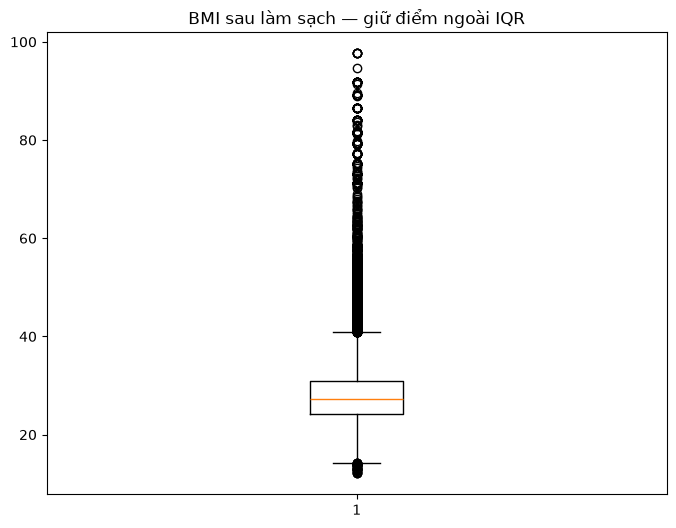

,_source_row,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,110385,0.0,0.0,0.0,1.0,12.11,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,3.0,0.0,0.0,1.0,0.0,13.0,5.0,2.0
1,41186,0.0,0.0,0.0,1.0,12.17,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,3.0,0.0,1.0,0.0,1.0,9.0,2.0,8.0
2,79909,0.0,0.0,0.0,1.0,12.20,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0,15.0,0.0,0.0,1.0,11.0,6.0,7.0
3,142346,0.0,0.0,1.0,1.0,12.37,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,6.0,2.0
4,97028,0.0,0.0,0.0,1.0,12.69,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,11.0,4.0,1.0
5,31479,1.0,1.0,1.0,1.0,12.75,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,30.0,30.0,1.0,0.0,10.0,5.0,1.0
6,142314,0.0,0.0,0.0,1.0,12.84,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,4.0,7.0,30.0,0.0,1.0,9.0,5.0,5.0
7,64487,0.0,1.0,1.0,1.0,12.91,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,3.0,0.0,0.0,0.0,1.0,10.0,6.0,5.0
8,198779,0.0,0.0,1.0,1.0,12.92,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,11.0,6.0,8.0
9,165031,0.0,0.0,0.0,1.0,12.95,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,3.0,7.0,0.0,0.0,0.0,9.0,2.0,1.0


,_source_row,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,63751,0.0,1.0,0.0,1.0,91.82,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,3.0,0.0,21.0,1.0,0.0,10.0,5.0,7.0
1,63762,1.0,0.0,0.0,1.0,91.82,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,3.0,0.0,0.0,1.0,0.0,13.0,6.0,4.0
2,63778,0.0,1.0,1.0,1.0,91.82,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,10.0,5.0,7.0
3,63821,0.0,1.0,1.0,1.0,91.82,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,6.0,8.0
4,62226,0.0,0.0,1.0,1.0,94.66,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,1.0,0.0,9.0,5.0,8.0
5,62164,1.0,1.0,1.0,1.0,97.65,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,4.0,15.0,10.0,1.0,0.0,11.0,5.0,6.0
6,62228,0.0,1.0,1.0,1.0,97.65,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,13.0,5.0,8.0
7,63796,0.0,1.0,1.0,1.0,97.65,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,3.0,4.0,0.0,1.0,0.0,10.0,4.0,6.0
8,63813,1.0,0.0,0.0,1.0,97.65,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,3.0,2.0,0.0,0.0,0.0,10.0,6.0,7.0
9,63830,0.0,0.0,1.0,1.0,97.65,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,20.0,0.0,0.0,10.0,6.0,7.0


In [13]:
NON_BINARY=['BMI']
s=prep_bmi_stats('clean_sql','BMI');lo,hi=s['lo'],s['hi']
display(iqr_summary(df_clean[['BMI']]))
extreme_bmi=prep_table('SELECT * FROM clean_sql WHERE BMI<? OR BMI>? ORDER BY BMI,_source_row',(lo,hi),index_col='_source_row').astype(analysis_dtypes)
plt.figure(figsize=(8,6));plt.boxplot(df_clean['BMI']);plt.title('BMI sau làm sạch — giữ điểm ngoài IQR');plt.show()
display(prep_table('SELECT * FROM clean_sql WHERE BMI<? OR BMI>? ORDER BY BMI,_source_row LIMIT 10',(lo,hi)))
display(prep_table('SELECT * FROM (SELECT * FROM clean_sql WHERE BMI<? OR BMI>? ORDER BY BMI DESC,_source_row DESC LIMIT 10) ORDER BY BMI,_source_row',(lo,hi)))
assert prep_scalar('SELECT COUNT(*) FROM clean_sql c JOIN raw_scope r USING(_source_row) WHERE c.BMI != r._BMI5/100.0')==0


### 3.5.2. So sánh phân bố trước/sau làm sạch
**Trước: 201,596 dòng | Sau: 121,839 dòng | Giảm: 39.56%.** So sánh cùng phạm vi từ 60 tuổi trở lên, đã loại DIABETE3=2: df_selected_raw với df_clean (bản chính giữ duplicate). Cột ghép dùng % trong từng bộ, kể cả NaN trong mẫu số; đỏ = trước, xanh lá cây = sau. Không cân bằng lại mẫu. Tỷ lệ mô tả file hiện tại, chưa dùng trọng số khảo sát.

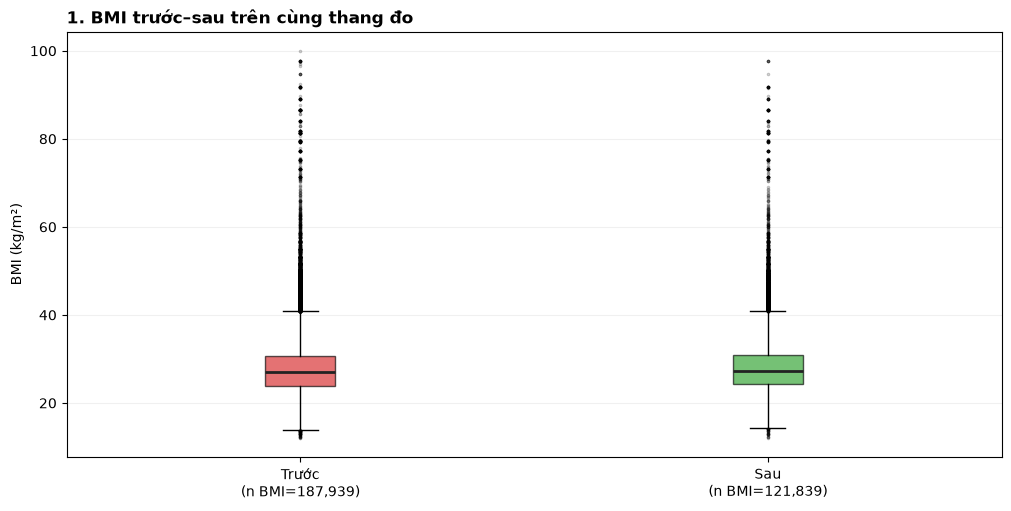

,Trước,Sau
Số BMI không thiếu,187939.00,121839.00
Số NaN,13657.00,0.00
Trung vị,26.96,27.26
Q1,23.91,24.21
Q3,30.67,30.90


Nhóm giữ phần thập phân của BMI trước và sau làm sạch. Nhóm đối chiếu phân bố để xem ảnh hưởng của việc loại hồ sơ.

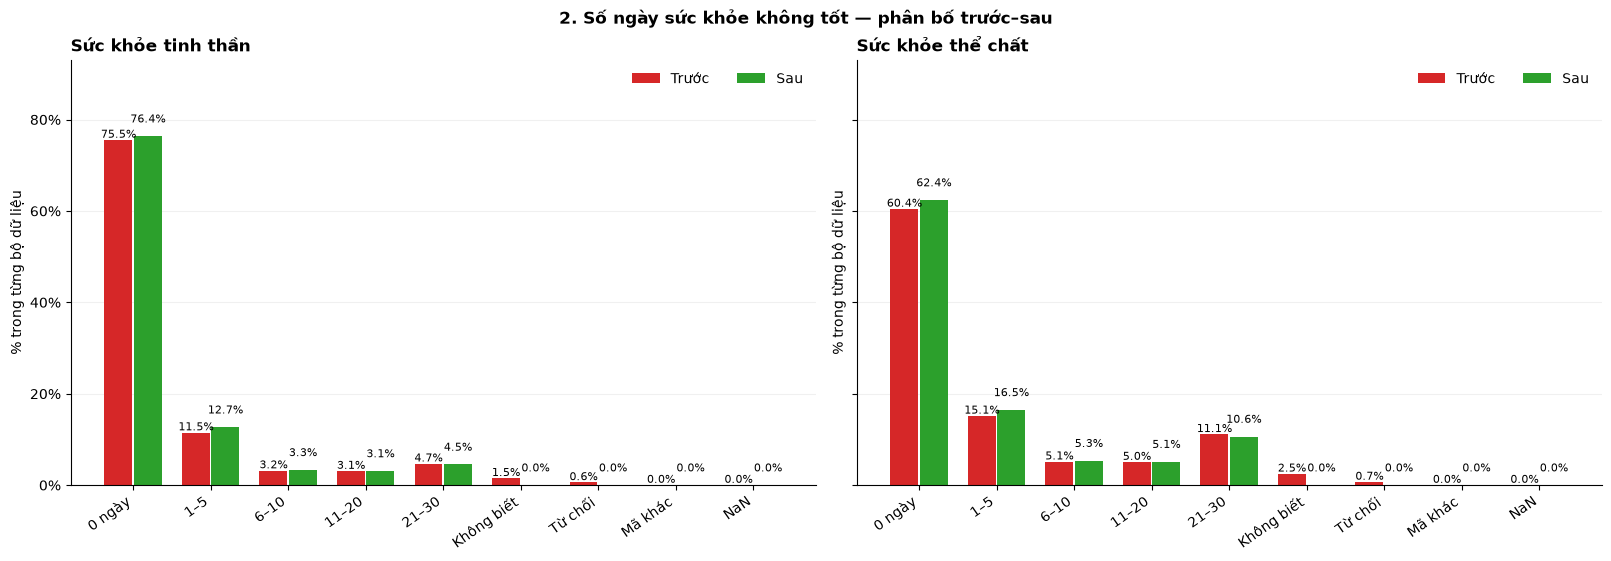

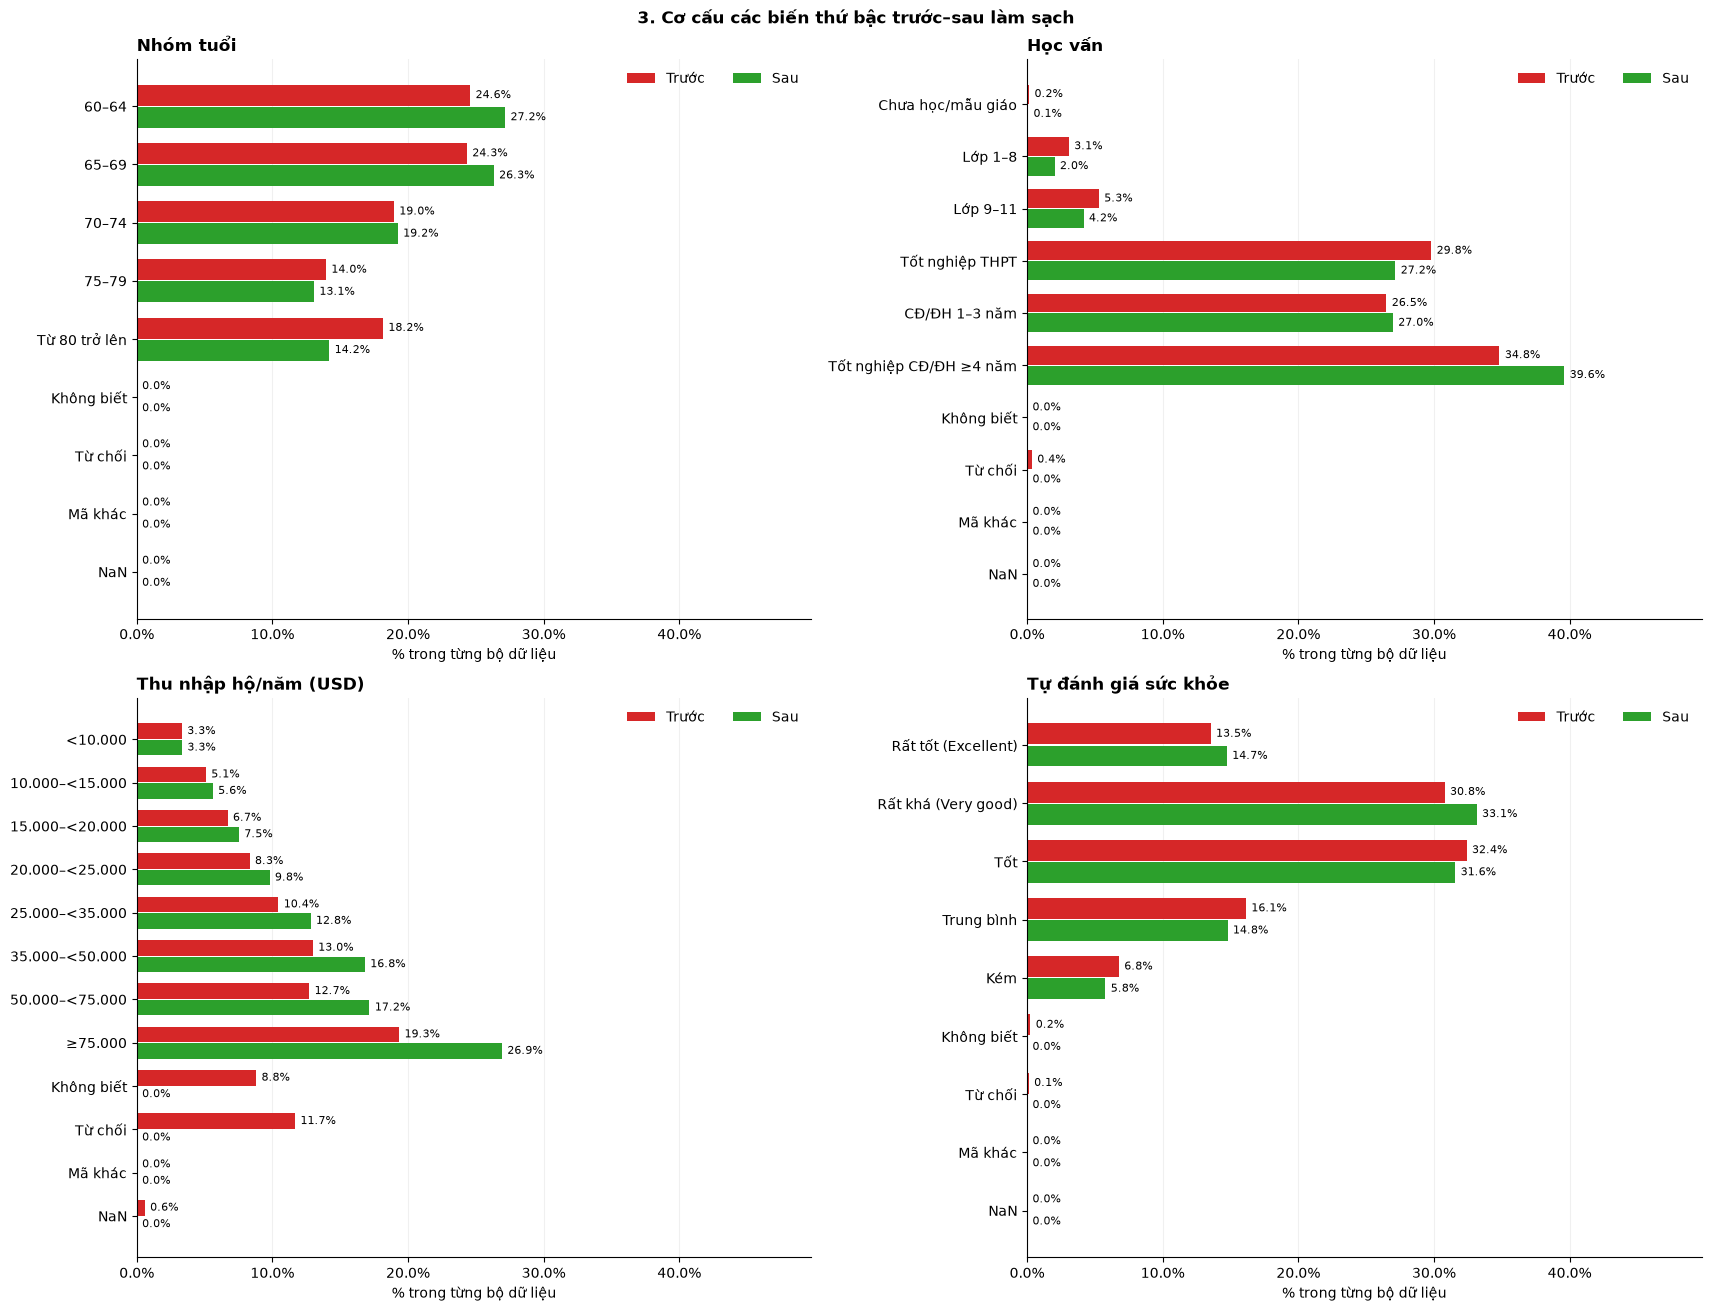

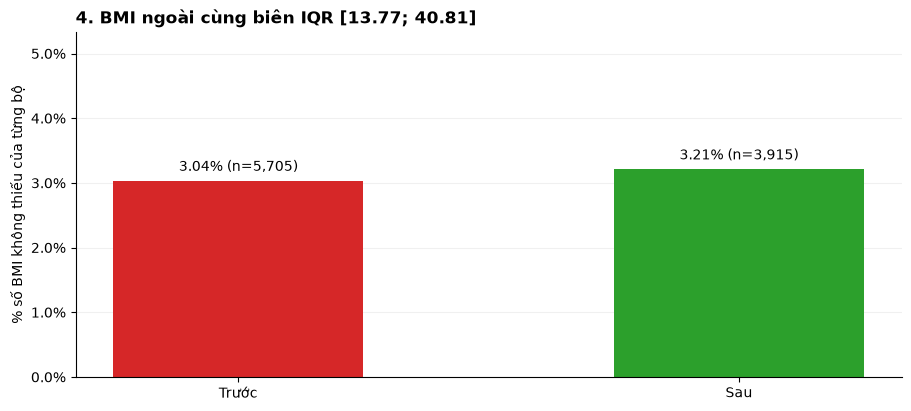

**Diễn giải:** ngưỡng BMI được tính một lần từ dữ liệu trước, áp dụng cho cả hai bộ; mẫu số biểu đồ 4 là số BMI không thiếu. Đây là điểm ngoài biên thống kê, chưa khẳng định là dữ liệu sai. Nhóm giữ các giá trị qua kiểm tra và đối chiếu nguồn ở mục 3.5.1; không tự động loại theo IQR. Các mã phản hồi và NaN vẫn được giữ trong biểu đồ trước để thấy tác động làm sạch. **Không sửa df_selected_raw hoặc df_clean.**

In [14]:
# SO SÁNH PHÂN BỐ TRƯỚC/SAU LÀM SẠCH — MỤC 3.5.2
# Chỉ đọc dữ liệu; đổi đơn vị/nhãn trên bản phục vụ vẽ.
def plot_cleaning_comparison(raw, clean):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter
    from IPython.display import display, Markdown

    nb, na = len(raw), len(clean)
    if nb == 0 or na == 0:
        raise ValueError('Cần dữ liệu trước và sau làm sạch có ít nhất một dòng.')
    before_color, after_color = '#D62728', '#2CA02C'
    display(Markdown(
        '### 3.5.2. So sánh phân bố trước/sau làm sạch\n'
        f'**Trước: {nb:,} dòng | Sau: {na:,} dòng | Giảm: {(1-na/nb)*100:.2f}%.** '
        'So sánh cùng phạm vi từ 60 tuổi trở lên, đã loại DIABETE3=2: df_selected_raw với df_clean (bản chính giữ duplicate). '
        'Cột ghép dùng % trong từng bộ, kể cả NaN trong mẫu số; '
        'đỏ = trước, xanh lá cây = sau. Không cân bằng lại mẫu. '
        'Tỷ lệ mô tả file hiện tại, chưa dùng trọng số khảo sát.'))

    def style(ax, horizontal=False):
        ax.set_axisbelow(True)
        ax.grid(axis='x' if horizontal else 'y', alpha=.18)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(PercentFormatter(100))

    def counts(series, mapping, order):
        return prep_distribution(series,mapping,order)

    def paired(ax, before, after, title, horizontal=False, limit=None):
        x = np.arange(len(before))
        bp, ap = before/nb*100, after/na*100
        if horizontal:
            b = ax.barh(x-.19, bp, height=.36, color=before_color, label='Trước')
            a = ax.barh(x+.19, ap, height=.36, color=after_color, label='Sau')
            ax.set_yticks(x, before.index)
            ax.invert_yaxis()
            ax.set_xlim(0, limit)
            ax.set_xlabel('% trong từng bộ dữ liệu')
            for bars, ps in [(b, bp), (a, ap)]:
                for bar, p in zip(bars, ps):
                    ax.text(p+.4, bar.get_y()+bar.get_height()/2,
                            f'{p:.1f}%', va='center', fontsize=8)
        else:
            b = ax.bar(x-.19, bp, width=.36, color=before_color, label='Trước')
            a = ax.bar(x+.19, ap, width=.36, color=after_color, label='Sau')
            ax.set_xticks(x, before.index, rotation=35, ha='right')
            ax.set_ylim(0, limit)
            ax.set_ylabel('% trong từng bộ dữ liệu')
            for bars, ps in [(b, bp), (a, ap)]:
                for bar, p in zip(bars, ps):
                    ax.text(bar.get_x()+bar.get_width()/2, p+(.5 if bars is b else 3),
                            f'{p:.1f}%', ha='center', fontsize=8)
        ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
        ax.legend(frameon=False, ncol=2, loc='upper right')
        style(ax, horizontal)

    with plt.rc_context({'font.family':'DejaVu Sans', 'font.size':10}):
        # 1. BMI cùng đơn vị, toàn bộ giá trị không thiếu, không cắt outlier.
        bmi_before = prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope WHERE _BMI5 IS NOT NULL ORDER BY _source_row')['BMI']
        bmi_after = prep_table('SELECT BMI FROM clean_sql WHERE BMI IS NOT NULL ORDER BY _source_row')['BMI']
        if bmi_before.empty or bmi_after.empty:
            raise ValueError('BMI không có giá trị quan sát ở một trong hai bộ.')
        fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
        boxes = ax.boxplot([bmi_before, bmi_after], patch_artist=True,
            tick_labels=[f'Trước\n(n BMI={len(bmi_before):,})', f'Sau\n(n BMI={len(bmi_after):,})'],
            flierprops={'marker':'.', 'markersize':3, 'alpha':.25},
            medianprops={'color':'#222222', 'linewidth':2})
        for box, color in zip(boxes['boxes'], [before_color, after_color]):
            box.set_facecolor(color)
            box.set_alpha(.65)
        ax.set_title('1. BMI trước–sau trên cùng thang đo', loc='left', fontweight='bold')
        ax.set_ylabel('BMI (kg/m²)')
        ax.grid(axis='y', alpha=.18)
        plt.show()
        display(pd.DataFrame({
            'Trước': [len(bmi_before), prep_scalar('SELECT COUNT(*)-COUNT(_BMI5) FROM raw_scope'), prep_quantile('raw_scope','_BMI5/100.0',.5),
                      prep_quantile('raw_scope','_BMI5/100.0',.25), prep_quantile('raw_scope','_BMI5/100.0',.75)],
            'Sau': [len(bmi_after), prep_scalar('SELECT COUNT(*)-COUNT(BMI) FROM clean_sql'), prep_quantile('clean_sql','BMI',.5),
                    prep_quantile('clean_sql','BMI',.25), prep_quantile('clean_sql','BMI',.75)]},
            index=['Số BMI không thiếu', 'Số NaN', 'Trung vị', 'Q1', 'Q3']).round(2))
        display(Markdown('Nhóm giữ phần thập phân của BMI trước và sau làm sạch. '
                         'Nhóm đối chiếu phân bố để xem ảnh hưởng của việc loại hồ sơ.'))

        # 2. Số ngày: 88 -> nhãn 0 ngày; 77/99 không phải ngày thực tế.
        day_map = {0:'0 ngày', 88:'0 ngày',
            **{i:'1–5' for i in range(1,6)}, **{i:'6–10' for i in range(6,11)},
            **{i:'11–20' for i in range(11,21)}, **{i:'21–30' for i in range(21,31)},
            77:'Không biết', 99:'Từ chối'}
        day_order = ['0 ngày','1–5','6–10','11–20','21–30','Không biết','Từ chối','Mã khác','NaN']
        day_data = [(counts(raw[r], day_map, day_order), counts(clean[c], day_map, day_order), t)
            for r, c, t in [('MENTHLTH','MentHlth','Sức khỏe tinh thần'),
                            ('PHYSHLTH','PhysHlth','Sức khỏe thể chất')]]
        day_limit = min(100, max(max(b.max()/nb*100, a.max()/na*100)
                                 for b, a, _ in day_data)*1.18+3)
        fig, axes = plt.subplots(1,2,figsize=(16,5.5),sharey=True,layout='constrained')
        fig.suptitle('2. Số ngày sức khỏe không tốt — phân bố trước–sau', fontweight='bold')
        for ax, (b,a,t) in zip(axes, day_data):
            paired(ax,b,a,t,limit=day_limit)
        plt.show()

        # 3. Bốn biến thứ bậc: cùng thứ tự nhóm, cùng trục tỷ lệ giữa các ô.
        age = ['60–64','65–69','70–74','75–79','Từ 80 trở lên']
        specs = [
            ('_AGEG5YR','Age','Nhóm tuổi', dict(enumerate(age,9)), {14:'Không biết'}),
            ('EDUCA','Education','Học vấn', {1:'Chưa học/mẫu giáo',2:'Lớp 1–8',3:'Lớp 9–11',
             4:'Tốt nghiệp THPT',5:'CĐ/ĐH 1–3 năm',6:'Tốt nghiệp CĐ/ĐH ≥4 năm'}, {9:'Từ chối'}),
            ('INCOME2','Income','Thu nhập hộ/năm (USD)', {1:'<10.000',2:'10.000–<15.000',
             3:'15.000–<20.000',4:'20.000–<25.000',5:'25.000–<35.000',
             6:'35.000–<50.000',7:'50.000–<75.000',8:'≥75.000'}, {77:'Không biết',99:'Từ chối'}),
            ('GENHLTH','GenHlth','Tự đánh giá sức khỏe', {1:'Rất tốt (Excellent)',
             2:'Rất khá (Very good)',3:'Tốt',4:'Trung bình',5:'Kém'}, {7:'Không biết',9:'Từ chối'})]
        ordinal_data = []
        for r,c,t,valid,special in specs:
            order = list(valid.values()) + ['Không biết','Từ chối','Mã khác','NaN']
            ordinal_data.append((counts(raw[r], {**valid,**special}, order),
                                 counts(clean[c], valid, order), t))
        ord_limit = min(100, max(max(b.max()/nb*100, a.max()/na*100)
                                 for b,a,_ in ordinal_data)*1.18+3)
        fig, axes = plt.subplots(2,2,figsize=(17,13),layout='constrained')
        fig.suptitle('3. Cơ cấu các biến thứ bậc trước–sau làm sạch', fontweight='bold')
        for ax,(b,a,t) in zip(axes.flat,ordinal_data):
            paired(ax,b,a,t,horizontal=True,limit=ord_limit)
        plt.show()

        # 4. BMI ngoài biên: một ngưỡng cố định từ dữ liệu trước đã đổi đơn vị.
        q1,q3 = prep_quantile('raw_scope','_BMI5/100.0',.25),prep_quantile('raw_scope','_BMI5/100.0',.75)
        lo,hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
        out_b = prep_scalar('SELECT SUM(_BMI5/100.0<? OR _BMI5/100.0>?) FROM raw_scope',(lo,hi))
        out_a = prep_scalar('SELECT SUM(BMI<? OR BMI>?) FROM clean_sql',(lo,hi))
        percentages = [out_b/len(bmi_before)*100, out_a/len(bmi_after)*100]
        fig, ax = plt.subplots(figsize=(9,4),layout='constrained')
        bars = ax.bar(['Trước','Sau'],percentages,color=[before_color,after_color],width=.5)
        ax.set_ylim(0,max(percentages)*1.35+1)
        for b,p,num in zip(bars,percentages,[out_b,out_a]):
            ax.text(b.get_x()+b.get_width()/2,p+.15,f'{p:.2f}% (n={num:,})',ha='center')
        ax.set_title(f'4. BMI ngoài cùng biên IQR [{lo:.2f}; {hi:.2f}]',loc='left',fontweight='bold')
        ax.set_ylabel('% số BMI không thiếu của từng bộ')
        style(ax)
        plt.show()
        display(Markdown('**Diễn giải:** ngưỡng BMI được tính một lần từ dữ liệu trước, '
            'áp dụng cho cả hai bộ; mẫu số biểu đồ 4 là số BMI không thiếu. '
            'Đây là điểm ngoài biên thống kê, chưa khẳng định là dữ liệu sai. '
            'Nhóm giữ các giá trị qua kiểm tra và đối chiếu nguồn ở mục 3.5.1; không tự động loại theo IQR. '
            'Các mã phản hồi và NaN vẫn được giữ trong biểu đồ trước để thấy tác động làm sạch. '
            '**Không sửa df_selected_raw hoặc df_clean.**'))

plot_cleaning_comparison(df_selected_raw, df_clean)


### 3.5.3. Bảng tổng hợp trước/sau làm sạch

Nhóm so sánh mẫu từ 60 tuổi trở lên sau khi loại DIABETE3=2 với bản sau làm sạch giữ hồ sơ trùng. Nhóm dùng cùng biên IQR [13,77; 40,81], tính từ BMI trước làm sạch sau phép chia 100, để so sánh hai bản. Nhóm lấy số BMI không thiếu trong mỗi bản làm mẫu số tỷ lệ ngoài biên.

Nhóm giữ phần thập phân của BMI và chưa loại hồ sơ theo IQR. Nhóm tính biên riêng trên bản sau làm sạch ở mục 3.5.1; hai phép kiểm tra có mục đích và mẫu tính biên khác nhau.

**Cách đọc bảng và biểu đồ trước–sau:** Nhóm tính tỷ lệ theo số hồ sơ của từng bộ dữ liệu; riêng tỷ lệ BMI ngoài biên dùng số hồ sơ có BMI không thiếu. Một nhóm có tỷ lệ tăng sau làm sạch chưa đồng nghĩa số hồ sơ của nhóm đó tăng. Nhóm giữ hồ sơ trùng; số hồ sơ trùng ngoài lần đầu giảm từ 2.107 xuống 1.277 do các điều kiện lọc thiếu/mã khảo sát và việc chuyển mã, không phải do nhóm chạy bước xóa trùng.

**Tổng kết Phần III**

Sau làm sạch, nhóm giữ 121.839 hồ sơ với 21 đặc trưng và một nhãn. Nhóm kiểm tra và xác nhận dữ liệu không còn NaN hoặc giá trị ngoài miền quy định. Nhóm giữ hồ sơ trùng và BMI thập phân, kể cả các giá trị ngoài biên IQR. Qua xử lý thiếu và mã khảo sát, nhóm loại 79.757 hồ sơ, chiếm 39,56% mẫu trước làm sạch. Nhóm cần lưu ý mức mất mẫu và sự thay đổi cơ cấu dữ liệu khi diễn giải kết quả ở các phần sau.


In [15]:
summary_comparison = pd.DataFrame({
    'Chỉ tiêu': ['Số dòng', 'Số cột', 'Số ô NaN', 'Dòng chứa NaN',
                'Duplicate ngoài lần đầu', 'Kiểu lưu trữ', 'Mã tuổi', 'Mã nhãn'],
    'Trước clean (đã chọn phạm vi)': [len(df_selected_raw), df_selected_raw.shape[1],
        int(missing_table('raw_scope',SOURCE_COLS).missing_count.sum()), prep_scalar('SELECT COUNT(*) FROM raw_scope WHERE '+' OR '.join(qi(c)+' IS NULL' for c in SOURCE_COLS)),
        duplicate_count('raw_scope',SOURCE_COLS), ', '.join(map(str, df_selected_raw.dtypes.unique())),
        '9–13 (từ 60 tuổi trở lên)', 'DIABETE3: 1/3/4 và mã không rõ/NaN nếu có'],
    'Sau clean (giữ duplicate)': [len(df_clean), df_clean.shape[1],
        int(missing_table('clean_sql',list(rename_dict.values())).missing_count.sum()), prep_scalar('SELECT COUNT(*) FROM clean_sql WHERE '+' OR '.join(qi(c)+' IS NULL' for c in rename_dict.values())),
        duplicate_count('clean_sql',list(rename_dict.values())), ', '.join(map(str, df_clean.dtypes.unique())),
        '9–13 (giữ mã gốc)', '0: DIABETE3=3; 1: DIABETE3=1/4']
})
# So sánh BMI theo cùng biên IQR từ dữ liệu trước làm sạch.
# Chỉ đổi thang trên bản phục vụ thống kê; không sửa dữ liệu.
bmi_before_compare = prep_table('SELECT _BMI5/100.0 AS BMI FROM raw_scope WHERE _BMI5 IS NOT NULL ORDER BY _source_row')['BMI']
bmi_after_compare = prep_table('SELECT BMI FROM clean_sql WHERE BMI IS NOT NULL ORDER BY _source_row')['BMI']
q1_compare,q3_compare=prep_quantile('raw_scope','_BMI5/100.0',.25),prep_quantile('raw_scope','_BMI5/100.0',.75)
lo_compare = q1_compare - 1.5 * (q3_compare - q1_compare)
hi_compare = q3_compare + 1.5 * (q3_compare - q1_compare)
outside_before_compare = prep_scalar('SELECT SUM(_BMI5/100.0<? OR _BMI5/100.0>?) FROM raw_scope',(lo_compare,hi_compare))
outside_after_compare = prep_scalar('SELECT SUM(BMI<? OR BMI>?) FROM clean_sql',(lo_compare,hi_compare))

def outlier_comparison_text(count, total):
    number = f'{count:,}'.replace(',', '.')
    percent = f'{count / total * 100:.2f}'.replace('.', ',')
    return f'{number} — {percent}%'

summary_comparison = pd.concat([
    summary_comparison,
    pd.DataFrame({
        'Chỉ tiêu': ['Biểu diễn BMI', 'Mã khảo sát đặc biệt', 'BMI ngoài cùng biên IQR'],
        'Trước clean (đã chọn phạm vi)': [
            'Giá trị nguồn nhân 100',
            'Còn mã không biết/từ chối và mã 88 ở biến số ngày',
            outlier_comparison_text(outside_before_compare, len(bmi_before_compare))],
        'Sau clean (giữ duplicate)': [
            'Chia 100, giữ phần thập phân',
            'Loại mã cần loại; chuyển 88 thành 0 ngày',
            outlier_comparison_text(outside_after_compare, len(bmi_after_compare))]
    })
], ignore_index=True)

display(summary_comparison)
print(f'Mẫu trước clean: {len(df_selected_raw):,}; sau clean: {len(df_clean):,}; '
      f'loại do làm sạch: {len(df_selected_raw)-len(df_clean):,} '
      f'({(1-len(df_clean)/len(df_selected_raw))*100:.2f}%).')
assert len(df_selected_raw) - sum(row[2] for row in audit_rows) == len(df_clean)


Mẫu trước clean: 201,596; sau clean: 121,839; loại do làm sạch: 79,757 (39.56%).


,Chỉ tiêu,Trước clean (đã chọn phạm vi),Sau clean (giữ duplicate)
0,Số dòng,201596,121839
1,Số cột,22,22
2,Số ô NaN,37494,0
3,Dòng chứa NaN,26813,0
4,Duplicate ngoài lần đầu,2107,1277
5,Kiểu lưu trữ,float64,"bool, float64, int16"
6,Mã tuổi,9–13 (từ 60 tuổi trở lên),9–13 (giữ mã gốc)
7,Mã nhãn,DIABETE3: 1/3/4 và mã không rõ/NaN nếu có,0: DIABETE3=3; 1: DIABETE3=1/4
8,Biểu diễn BMI,Giá trị nguồn nhân 100,"Chia 100, giữ phần thập phân"
9,Mã khảo sát đặc biệt,Còn mã không biết/từ chối và mã 88 ở biến số ngày,Loại mã cần loại; chuyển 88 thành 0 ngày


## Chuyển trực tiếp dữ liệu sạch sang phân tích

Nhóm tạo bản sao của `df_clean` để bảo toàn 121.839 hồ sơ và thứ tự của chúng, bao gồm hồ sơ trùng. Nhóm dùng bộ dữ liệu này cho các bước phân tích và mô hình phía sau.


In [16]:
analysis_input = df_clean.reset_index(drop=True).copy(deep=True)
pd.testing.assert_frame_equal(analysis_input, df_clean.reset_index(drop=True))
assert analysis_input is not df_clean
assert analysis_input.duplicated().sum() == df_clean.duplicated().sum()
print(f"Nhóm chuyển {len(analysis_input):,} hồ sơ sang đầu vào phân tích, giữ hồ sơ trùng.")


Nhóm chuyển 121,839 hồ sơ sang đầu vào phân tích, giữ hồ sơ trùng.


# IV. Phân tích pandas/NumPy và trực quan Python

## 4.1. Chia Train/Test và chuẩn bị EDA

Nhóm chia dữ liệu sạch của người **từ 60 tuổi trở lên** thành khoảng **80% Train và 20% Test**, giữ hồ sơ trùng. Nhóm gom các hồ sơ có cùng 21 đặc trưng vào một nhóm, kể cả khi khác nhãn, rồi đưa các thành viên trong nhóm vào cùng một tập.

Nhóm lấy lần chia đầu tiên của `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` để tạo Train/Test và cố gắng duy trì tỷ lệ nhãn. Do giữ nguyên các nhóm hồ sơ, nhóm chấp nhận tỷ lệ chia xấp xỉ 80/20. Nhóm chỉ dùng lần chia này để tách Train/Test; nhóm tạo một lượt StratifiedGroupKFold riêng trong Train để đánh giá chéo tại phần V.

Nhóm kiểm tra số hồ sơ, tỷ lệ nhãn và giao nhóm giữa hai tập trong bảng dưới, sau đó chỉ dùng **Train cho EDA**. Nhóm giữ Test cho bước đánh giá mô hình sau khi chốt quy trình. Nhãn 0 gồm DIABETE3=3; nhãn 1 gồm DIABETE3=1/4. Nhóm đã loại DIABETE3=2 trong phần tiền xử lý.

Nhóm mô tả mẫu khảo sát tự khai, chưa dùng trọng số khảo sát. Nhóm không suy luận quan hệ nhân quả từ các tỷ lệ này. Khi đọc tỷ lệ lớp 1 theo đặc trưng, nhóm cần xem cả số hồ sơ trong từng mức.

**Phạm vi xem dữ liệu:** Nhóm đã xem thống kê chất lượng, phân bố và nhãn của toàn bộ mẫu ở phần II–III trước khi tách Train/Test. Từ phần IV, nhóm chỉ dùng Train để phân tích chọn biến; nhóm giữ dự đoán và chỉ số hiệu năng trên Test đến bước đánh giá cuối. Vì vậy, nhóm không mô tả Test là hoàn toàn chưa từng quan sát ở mọi bước của dự án.


In [17]:
from pathlib import Path
import json,hashlib,math,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display,Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
# All database work ends at the preprocessing boundary.
if "PREP_DB" in globals(): PREP_DB.close()
PROJECT_ROOT=FINAL_ROOT
BASE=PROJECT_ROOT/"báo cáo"/".runtime_final_age60plus_bmi_decimal"/"sql_pandas_v2"
BASE.mkdir(parents=True,exist_ok=True)
TABLES,FIGS,MODELS=BASE/"tables",BASE/"figures",BASE/"models"
for folder in [TABLES,FIGS,MODELS]:folder.mkdir(exist_ok=True)
SEED = 42
TARGET = "Diabetes_binary"
FEATURES = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income",
]
NUMERIC_FEATURES = ["BMI", "MentHlth", "PhysHlth"]
ORDINAL_DOMAINS = {
    "Age": list(range(9, 14)),
    "Education": list(range(1, 7)),
    "Income": list(range(1, 9)),
    "GenHlth": list(range(1, 6)),
}
BINARY = [c for c in FEATURES if c not in NUMERIC_FEATURES and c not in ORDINAL_DOMAINS]
# Validate the analysis copy against the cleaned data from Part III.
clean_data = analysis_input.copy(deep=True)
pd.testing.assert_frame_equal(clean_data, df_clean.reset_index(drop=True))
assert clean_data is not df_clean
assert list(clean_data) == [TARGET] + FEATURES
assert not clean_data.isna().any().any()
assert len(clean_data) == len(df_clean)
pd.testing.assert_series_equal(
    clean_data[TARGET].value_counts().sort_index(),
    df_clean[TARGET].value_counts().sort_index())
assert clean_data.duplicated().sum() == df_clean.duplicated().sum()
assert clean_data.BMI.dtype == np.dtype("float64")
# Normalize bool to 0/1 only for hashing; preserve the existing CSV fingerprint.
actual_sha256 = hashlib.sha256(clean_data.astype({c: "int16" for c in [TARGET]+BINARY}).to_csv(index=False).encode("utf-8")).hexdigest()
# Part III verifies the source-label mapping; the checks below validate domains.
for col in [TARGET]+BINARY:assert clean_data[col].isin([0,1]).all()
for col,domain in ORDINAL_DOMAINS.items():assert clean_data[col].isin(domain).all()
assert clean_data[["MentHlth","PhysHlth"]].ge(0).all().all() and clean_data[["MentHlth","PhysHlth"]].le(30).all().all()
assert clean_data.BMI.gt(0).all()
clean_data.insert(0,"row_id",np.arange(len(clean_data),dtype=np.int64))
def save_frame(frame,name):frame.to_csv(TABLES/(name+".csv"),index=False)
display(clean_data.groupby(TARGET).size().rename("Số dòng").to_frame().assign(**{"Tỷ lệ (%)":lambda x:100*x["Số dòng"]/len(clean_data)}))
ORANGE, PURPLE, BLUE = "#E67E22", "#7E3FB2", "#1674B8"
PALETTE = {0: ORANGE, 1: PURPLE}
DISCRETE_COLOR = CONTINUOUS_COLOR = BLUE
CORRELATION_CMAP = LinearSegmentedColormap.from_list(
    "orange_white_red", [ORANGE, "#FFFFFF", "#C62828"]
)
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.facecolor": "white",
    }
)


def save_and_show_figure(name, fig=None):
    fig = fig or plt.gcf()
    fig.savefig(FIGS / (name + ".png"), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def note(text):
    display(Markdown(text))


,Số dòng,Tỷ lệ (%)
Diabetes_binary,,
False,94896,77.886391
True,26943,22.113609


In [18]:
# Group by predictors only, including identical profiles with different labels.
group_ids = pd.factorize(pd.MultiIndex.from_frame(clean_data[FEATURES]), sort=False)[0]
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_index, test_index = next(outer.split(clean_data[FEATURES], clean_data[TARGET], group_ids))
assert np.array_equal(np.sort(np.concatenate([train_index, test_index])), np.arange(len(clean_data)))
manifest = pd.DataFrame({"row_id": clean_data.row_id, "group_id": group_ids, "split": "test"})
manifest.loc[train_index, "split"] = "train"
assert manifest.row_id.is_unique
assert manifest.groupby("group_id").split.nunique().max() == 1
assert set(manifest.split) == {"train", "test"}
joined = clean_data.merge(manifest, on="row_id", validate="one_to_one", sort=False)
train_data = joined.loc[joined.split.eq("train"), ["row_id", TARGET]+FEATURES].sort_values("row_id").reset_index(drop=True)
test_data = joined.loc[joined.split.eq("test"), ["row_id", TARGET]+FEATURES].sort_values("row_id").reset_index(drop=True)
assert len(train_data) + len(test_data) == len(clean_data)
pd.testing.assert_frame_equal(
    pd.concat([train_data, test_data]).sort_values("row_id").reset_index(drop=True), clean_data)
split_summary = joined.groupby("split")[TARGET].agg(**{"Số dòng": "size", "Lớp 1": "sum"}).reindex(["train", "test"]).reset_index()
split_summary["Lớp 0"] = split_summary["Số dòng"] - split_summary["Lớp 1"]
split_summary["Tỷ lệ tập (%)"] = 100.0 * split_summary["Số dòng"] / len(clean_data)
split_summary["Lớp 1 (%)"] = 100.0 * split_summary["Lớp 1"] / split_summary["Số dòng"]
split_summary["Tập"] = split_summary["split"].map({"train": "Train", "test": "Test"})
split_summary = split_summary[["Tập", "Số dòng", "Tỷ lệ tập (%)", "Lớp 0", "Lớp 1", "Lớp 1 (%)"]]
display(split_summary)
save_frame(split_summary, "split_summary")
SPLITS = BASE / "splits"
SPLITS.mkdir(exist_ok=True)
manifest.to_csv(SPLITS / "split_manifest.csv", index=False)
split_meta = {
    "data_sha256": actual_sha256, "rows": len(clean_data), "features": FEATURES,
    "age_codes": list(range(9, 14)), "duplicate_policy": "keep",
    "method": "first split of StratifiedGroupKFold", "n_splits": 5,
    "shuffle": True, "seed": SEED, "group_by": FEATURES,
    "intended_train_fraction": 0.8, "train_rows": len(train_data), "test_rows": len(test_data),
    "group_overlap": 0, "cv_folds_created": False, "models_trained": False,
}
(SPLITS / "split_metadata.json").write_text(json.dumps(split_meta, ensure_ascii=False, indent=2), encoding="utf-8")
df_eda = train_data[[TARGET]+FEATURES].astype(analysis_dtypes)
X_train = df_eda[FEATURES].copy()
y_train = df_eda[TARGET].to_numpy(dtype=bool)
pandas_context = {"clean_data": clean_data, "manifest": manifest}
print("Nhóm giữ toàn bộ hồ sơ; số nhóm đặc trưng giao nhau giữa Train và Test: 0.")
print("Nhóm chỉ dùng Train cho EDA. Bước này chưa tạo các fold CV hoặc huấn luyện mô hình.")


Nhóm giữ toàn bộ hồ sơ; số nhóm đặc trưng giao nhau giữa Train và Test: 0.
Nhóm chỉ dùng Train cho EDA. Bước này chưa tạo các fold CV hoặc huấn luyện mô hình.


,Tập,Số dòng,Tỷ lệ tập (%),Lớp 0,Lớp 1,Lớp 1 (%)
0,Train,97472,80.000657,75917,21555,22.114043
1,Test,24367,19.999343,18979,5388,22.111873


In [19]:
AGE_LABELS = ["60–64", "65–69", "70–74", "75–79", "80+"]
EDU_LABELS = [
    "Chưa học/\nmẫu giáo",
    "Lớp 1–8",
    "Lớp 9–11",
    "THPT",
    "CĐ/ĐH\n1–3 năm",
    "CĐ/ĐH\n≥4 năm",
]
INCOME_LABELS = [
    "<10k",
    "10–<15k",
    "15–<20k",
    "20–<25k",
    "25–<35k",
    "35–<50k",
    "50–<75k",
    "≥75k",
]
GEN_LABELS = ["Excellent", "Very good", "Good", "Fair", "Poor"]
LABEL_MAPS = {
    "Age": dict(enumerate(AGE_LABELS, 9)),
    "Education": dict(enumerate(EDU_LABELS, 1)),
    "Income": dict(enumerate(INCOME_LABELS, 1)),
    "GenHlth": dict(enumerate(GEN_LABELS, 1)),
}
EDA_LEVELS = {
    **{feature: [0, 1] for feature in BINARY},
    **ORDINAL_DOMAINS,
    "MentHlth": list(range(31)),
    "PhysHlth": list(range(31)),
}


parts=[]
for feature,levels in EDA_LEVELS.items():
    grouped=train_data.groupby(feature)[TARGET].agg(sample_count="size",positive_count="sum").reindex(levels)
    grouped[["sample_count","positive_count"]]=grouped[["sample_count","positive_count"]].fillna(0).astype(int)
    grouped["positive_rate"]=100*grouped.positive_count/grouped.sample_count.replace(0,np.nan)
    grouped=grouped.rename_axis("level").reset_index();grouped.insert(0,"Feature",feature);grouped["position"]=np.arange(len(grouped));parts.append(grouped)
feature_summary=pd.concat(parts,ignore_index=True)
def plot_rate_grid(features,label_maps,min_count=1):
    selected=feature_summary[feature_summary.Feature.isin(features)&feature_summary.sample_count.ge(min_count)]
    maximum=selected.positive_rate.max();limit=min(100,max(10,np.ceil(maximum/10)*10+10))
    fig,axes=plt.subplots((len(features)+1)//2,2,figsize=(14,4*((len(features)+1)//2)),squeeze=False,sharey=True)
    for ax,feature in zip(axes.flat,features):
        values=feature_summary[feature_summary.Feature.eq(feature)].sort_values("position")
        rates=values.positive_rate.where(values.sample_count.ge(min_count))
        pos=np.arange(len(values));labels=[label_maps.get(feature,{}).get(level,str(level)) for level in values.level]
        step=5 if len(labels)>15 else 1
        ax.bar(pos,rates,color=BLUE);ax.set(xticks=pos[::step],xticklabels=labels[::step],title=feature,ylabel="Lớp 1 trong nhóm (%)",ylim=(0,limit))
        ax.tick_params(axis="x",labelrotation=20 if feature=="Income" else 0)
    for ax in list(axes.flat)[len(features):]:ax.set_visible(False)
    fig.tight_layout();return fig


## Tổng hợp bằng pandas: tỷ lệ nhãn 1 theo nhóm tuổi trên Train
Dùng groupby, agg và phép chia vector hóa để tính số hồ sơ, số nhãn 1 và tỷ lệ. Mẫu số là số hồ sơ Train của từng nhóm tuổi, khác bảng SQL trước làm sạch ở phần dữ liệu.


In [20]:
age_summary=train_data.groupby("Age",sort=True)[TARGET].agg(n="size",positive_count="sum")
age_summary["positive_percent"]=(100.0*age_summary.positive_count/age_summary.n).round(2)
age_summary = age_summary.reset_index()
age_summary.insert(1, "Nhóm tuổi", age_summary.Age.map(LABEL_MAPS["Age"]))
display(age_summary)


,Age,Nhóm tuổi,n,positive_count,positive_percent
0,9,60–64,26417,5161,19.54
1,10,65–69,25756,5799,22.52
2,11,70–74,18747,4599,24.53
3,12,75–79,12665,3053,24.11
4,13,80+,13887,2943,21.19


## 4.2. Tổng quan và phân bố trên Train

### a. Chất lượng dữ liệu và phân bố nhãn

Nhóm kiểm tra số hồ sơ, giá trị thiếu, giá trị khác nhau và miền giá trị trên Train sau tiền xử lý. Nhóm nhận dữ liệu sạch từ Phần III và dùng bản chia ở mục 4.1.

Trong bảng, nhóm ghi dtype của `df_eda` vào cột **Kiểu dữ liệu dùng cho EDA**. Nhóm dùng nhãn và 14 biến nhị phân đã được ép boolean từ Phần III, giữ BMI dạng float64 và Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16. Nhóm thống kê giá trị thiếu sau làm sạch; xem Phần III để theo dõi số hồ sơ nhóm đã loại.


Train: 97,472 dòng; trùng toàn bộ 22 cột: 1,018.


,Feature,Kiểu dữ liệu dùng cho EDA,Số thiếu,Số giá trị khác nhau,Nhỏ nhất,Lớn nhất
0,Diabetes_binary,bool,0,2,0.00,1.00
1,HighBP,bool,0,2,0.00,1.00
2,HighChol,bool,0,2,0.00,1.00
3,CholCheck,bool,0,2,0.00,1.00
4,BMI,float64,0,2537,12.17,97.65
5,Smoker,bool,0,2,0.00,1.00
6,Stroke,bool,0,2,0.00,1.00
7,HeartDiseaseorAttack,bool,0,2,0.00,1.00
8,PhysActivity,bool,0,2,0.00,1.00
9,Fruits,bool,0,2,0.00,1.00


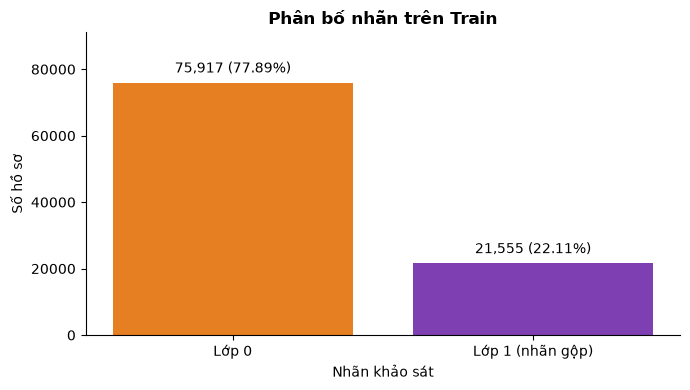

Lớp 1 chiếm **22.11%** Train. Nếu dự đoán toàn bộ là lớp 0, nhóm đạt Accuracy **77.89%** và Recall lớp 1 **0%**.

In [21]:
data_summary=pd.DataFrame({"Feature":[TARGET]+FEATURES,"Kiểu dữ liệu dùng cho EDA":[str(df_eda[c].dtype) for c in [TARGET]+FEATURES],"Số thiếu":df_eda.isna().sum().to_numpy(),"Số giá trị khác nhau":df_eda.nunique().to_numpy(),"Nhỏ nhất":df_eda.min().astype(float).to_numpy(),"Lớn nhất":df_eda.max().astype(float).to_numpy()})
display(data_summary);save_frame(data_summary,"ref_data_summary")
numeric_summary=train_data[NUMERIC_FEATURES].describe().T.rename_axis("Feature").reset_index()
row_count=len(train_data);duplicate_rows=int(train_data.duplicated(subset=[TARGET]+FEATURES).sum())
print(f"Train: {row_count:,} dòng; trùng toàn bộ 22 cột: {duplicate_rows:,}.")
assert df_eda.isna().sum().sum()==0
label_summary=train_data.groupby(TARGET).size().rename("sample_count").reset_index()
label_summary["percent"]=100*label_summary.sample_count/row_count
save_frame(label_summary,"eda_target_counts")
fig,ax=plt.subplots(figsize=(7,4));ax.bar(label_summary[TARGET],label_summary.sample_count,color=[PALETTE[v] for v in label_summary[TARGET]])
ax.set(title="Phân bố nhãn trên Train",xlabel="Nhãn khảo sát",ylabel="Số hồ sơ",xticks=[0,1],xticklabels=["Lớp 0","Lớp 1 (nhãn gộp)"],ylim=(0,1.2*label_summary.sample_count.max()))
ax.bar_label(ax.containers[0],labels=[f"{r.sample_count:,} ({r.percent:.2f}%)" for r in label_summary.itertuples()],padding=5)
fig.tight_layout();save_and_show_figure("eda_01_target",fig)
positive_percent=float(label_summary.loc[label_summary[TARGET].eq(1),"percent"].iloc[0])
note(f"Lớp 1 chiếm **{positive_percent:.2f}%** Train. Nếu dự đoán toàn bộ là lớp 0, nhóm đạt Accuracy **{100-positive_percent:.2f}%** và Recall lớp 1 **0%**.")


### b. Phân bố BMI và số ngày sức khỏe không tốt

Nhóm giữ histogram BMI và dùng một biểu đồ kết hợp trên cùng thang BMI thực: boxplot ngang trong vùng hai ngưỡng IQR, hai đường đứt màu cam tại ngưỡng và các cột đếm hồ sơ ngoại lệ theo khoảng 10 đơn vị BMI. Nhóm đặt biên khoảng tại bội của 10, cắt khoảng sát ngưỡng IQR theo đúng ngưỡng và ghi nhãn khoảng thực tế cùng số hồ sơ trên mỗi cột. Boxplot giữ các thống kê của BMI trên Train, ẩn điểm ngoại lệ vì nhóm đã đếm chúng bằng cột. Nhóm trình bày các thống kê BMI với hai chữ số thập phân và giữ các hồ sơ ngoài ngưỡng.

Với `MentHlth` và `PhysHlth`, nhóm đếm hồ sơ trong các khoảng **0–4, 5–9, 10–14, 15–19, 20–24, 25–29 và 30 ngày** rồi vẽ biểu đồ cột. Nhóm tách 30 ngày thành cột cuối vì dữ liệu chỉ nhận giá trị từ 0 đến 30. Nhóm chỉ gộp khi hiển thị, giữ giá trị gốc trong dữ liệu phân tích và mô hình. Nhóm dùng chung thang số hồ sơ để so sánh hai biến.


<ipython-input-22-e6d5ec1facdd>:53: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box_ax.boxplot(df_eda.BMI, vert=False, positions=[.55], widths=.16, showfliers=False,


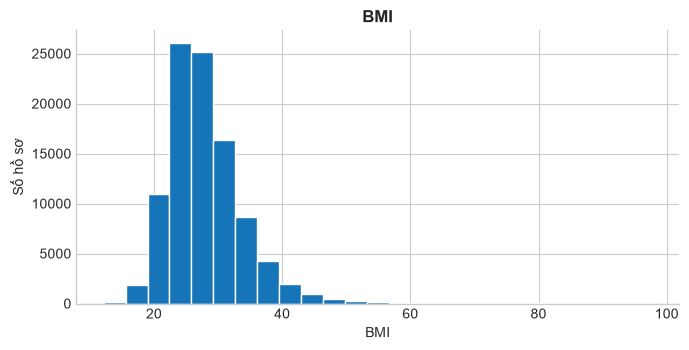

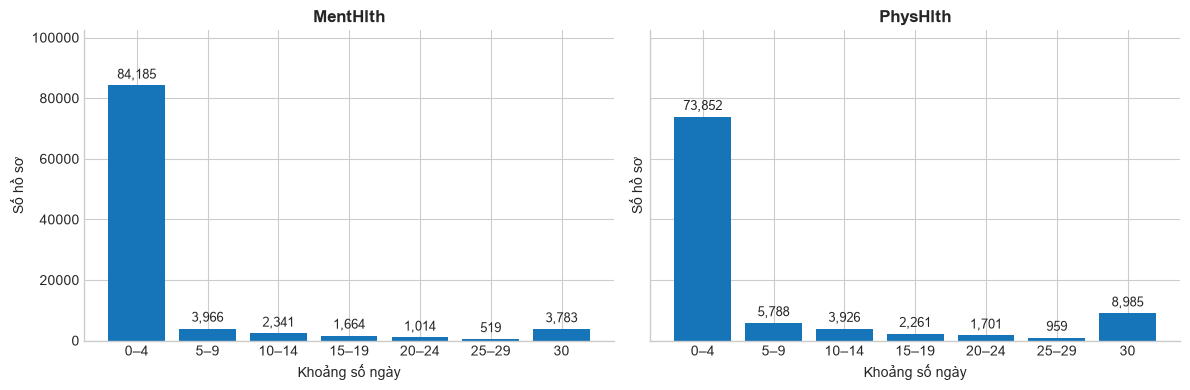

,Feature,count,mean,std,min,25%,50%,75%,max
0,BMI,97472.0,28.11,6.06,12.17,24.21,27.26,30.9,97.65
1,MentHlth,97472.0,2.47,6.72,0.00,0.00,0.00,0.0,30.00
2,PhysHlth,97472.0,4.84,9.33,0.00,0.00,0.00,4.0,30.00


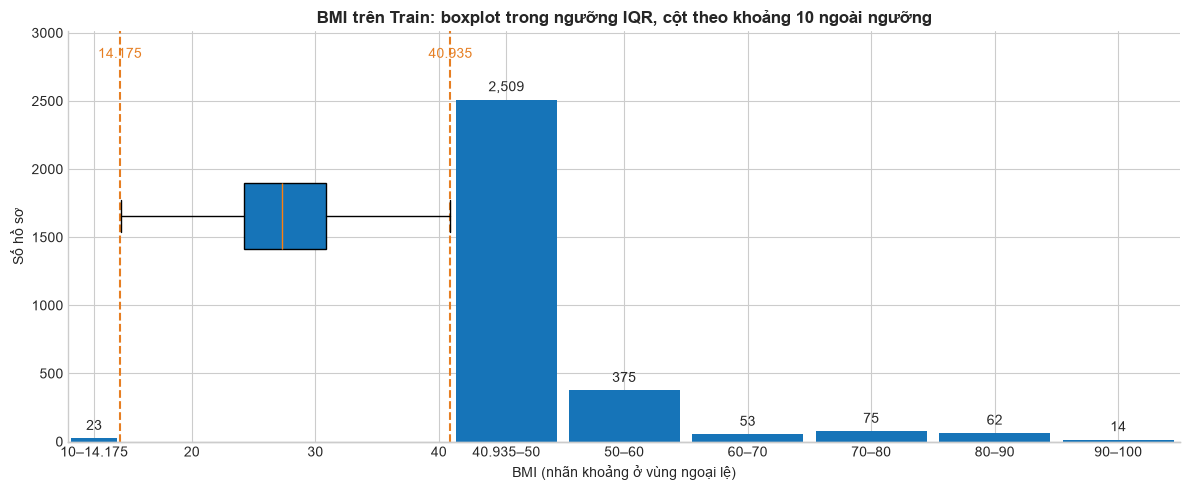

Nhóm ghi nhận BMI có Q1–Q3 **24.21–30.90**, trung vị **27.26**, nhỏ nhất **12.17** và lớn nhất **97.65**. Theo ngưỡng IQR, nhóm đếm **23** hồ sơ dưới **14.18** và **3,088** hồ sơ trên **40.93** (tổng **3,111**, **3.19%** Train). Nhóm giữ các hồ sơ này. Nhóm ghi nhận **76.39%** hồ sơ có MentHlth bằng 0 và **62.36%** có PhysHlth bằng 0; nhóm gộp các giá trị 0–4 khi vẽ biểu đồ nên cột đầu còn gồm hồ sơ có 1–4 ngày.

In [22]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(df_eda.BMI, bins=25, color=CONTINUOUS_COLOR, edgecolor="white")
ax.set(title="BMI", xlabel="BMI", ylabel="Số hồ sơ")
fig.tight_layout()
save_and_show_figure("eda_02_bmi_distribution", fig)

DAY_LABELS = ["0–4", "5–9", "10–14", "15–19", "20–24", "25–29", "30"]
day_parts = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, feature in zip(axes, ["MentHlth", "PhysHlth"]):
    grouped_days = pd.cut(train_data[feature], bins=[0,5,10,15,20,25,30,31], right=False, labels=DAY_LABELS)
    counts = grouped_days.value_counts(sort=False).reindex(DAY_LABELS)
    assert counts.sum() == len(train_data)
    bars = ax.bar(DAY_LABELS, counts.to_numpy(), color=CONTINUOUS_COLOR)
    ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=3, fontsize=9)
    ax.set(title=feature, xlabel="Khoảng số ngày", ylabel="Số hồ sơ")
    ax.set_ylim(0, len(train_data)*1.05)
    day_parts.append(pd.DataFrame({"Feature": feature, "Khoảng ngày": DAY_LABELS, "Số hồ sơ": counts.to_numpy()}))
fig.tight_layout()
save_and_show_figure("eda_02_health_days_grouped", fig)
day_distribution = pd.concat(day_parts, ignore_index=True)
save_frame(day_distribution, "eda_health_days_grouped")

display(numeric_summary.round(2));save_frame(numeric_summary,"eda_numeric_summary")
bmi_row=numeric_summary.set_index("Feature").loc["BMI"]
bmi_summary={"q1":bmi_row["25%"],"q2":bmi_row["50%"],"q3":bmi_row["75%"]}
bmi_iqr=bmi_summary["q3"]-bmi_summary["q1"];bmi_lower=bmi_summary["q1"]-1.5*bmi_iqr;bmi_upper=bmi_summary["q3"]+1.5*bmi_iqr
bmi_outliers = train_data.loc[~train_data.BMI.between(bmi_lower,bmi_upper), "BMI"]
bmi_outlier_total = len(bmi_outliers)
bmi_edges = np.arange(np.floor(train_data.BMI.min()/10)*10, np.floor(train_data.BMI.max()/10)*10+20, 10)
bmi_groups = []
for left, right in zip(bmi_edges[:-1], bmi_edges[1:]):
    for start, stop in [(left,min(right,bmi_lower)), (max(left,bmi_upper),right)]:
        if start < stop:
            count = int((bmi_outliers.ge(start) & bmi_outliers.lt(stop)).sum())
            bmi_groups.append({"BMI_group": f"{start:g}–{stop:g}", "BMI_lower": start,
                               "BMI_upper": stop, "sample_count": count})
bmi_outlier_counts = pd.DataFrame(bmi_groups)
assert int(bmi_outlier_counts.sample_count.sum()) == bmi_outlier_total
fig, ax = plt.subplots(figsize=(12, 5))
centers = (bmi_outlier_counts.BMI_lower+bmi_outlier_counts.BMI_upper)/2
widths = bmi_outlier_counts.BMI_upper-bmi_outlier_counts.BMI_lower
bars = ax.bar(centers, bmi_outlier_counts.sample_count, width=widths*.9, color=CONTINUOUS_COLOR)
ax.bar_label(bars, labels=[f"{n:,}" for n in bmi_outlier_counts.sample_count], padding=4)
ax.set(xticks=list(centers)+[20,30,40],
       xticklabels=list(bmi_outlier_counts.BMI_group)+["20","30","40"],
       title="BMI trên Train: boxplot trong ngưỡng IQR, cột theo khoảng 10 ngoài ngưỡng",
       xlabel="BMI (nhãn khoảng ở vùng ngoại lệ)", ylabel="Số hồ sơ")
ax.set_ylim(0, max(1,bmi_outlier_counts.sample_count.max())*1.2)
ax.set_xlim(bmi_edges[0],bmi_edges[-1])
box_ax = ax.twinx()
box_ax.boxplot(df_eda.BMI, vert=False, positions=[.55], widths=.16, showfliers=False,
               manage_ticks=False, patch_artist=True, boxprops={"facecolor": CONTINUOUS_COLOR})
box_ax.set(ylim=(0,1), yticks=[])
box_ax.grid(False)
box_ax.spines["left"].set_visible(False)
for threshold in [bmi_lower,bmi_upper]:
    ax.axvline(threshold, color=ORANGE, linestyle="--", linewidth=1.5)
    ax.text(threshold,.96,f"{threshold:g}",transform=ax.get_xaxis_transform(),
            ha="center",va="top",color=ORANGE)
fig.tight_layout()
save_and_show_figure("eda_03_bmi_outlier_detail", fig)
save_frame(bmi_outlier_counts,"eda_bmi_outlier_counts")
zero_rates={"mental":100*train_data.MentHlth.eq(0).mean(),"physical":100*train_data.PhysHlth.eq(0).mean()}
day_q3=numeric_summary.set_index("Feature")["75%"].to_dict()
bmi_outlier_percent = 100.0 * bmi_outlier_total / row_count
bmi_below = int(train_data.BMI.lt(bmi_lower).sum())
bmi_above = int(train_data.BMI.gt(bmi_upper).sum())
assert bmi_below + bmi_above == bmi_outlier_total
note(
    f"Nhóm ghi nhận BMI có Q1–Q3 **{bmi_summary['q1']:.2f}–{bmi_summary['q3']:.2f}**, "
    f"trung vị **{bmi_summary['q2']:.2f}**, nhỏ nhất **{train_data.BMI.min():.2f}** và lớn nhất **{train_data.BMI.max():.2f}**. "
    f"Theo ngưỡng IQR, nhóm đếm **{bmi_below:,}** hồ sơ dưới **{bmi_lower:.2f}** và **{bmi_above:,}** hồ sơ trên **{bmi_upper:.2f}** "
    f"(tổng **{bmi_outlier_total:,}**, **{bmi_outlier_percent:.2f}%** Train). Nhóm giữ các hồ sơ này. "
    f"Nhóm ghi nhận **{zero_rates['mental']:.2f}%** hồ sơ có MentHlth bằng 0 và **{zero_rates['physical']:.2f}%** có PhysHlth bằng 0; "
    f"nhóm gộp các giá trị 0–4 khi vẽ biểu đồ nên cột đầu còn gồm hồ sơ có 1–4 ngày."
)


### c. Phân bố biến nhị phân trên Train

Nhóm dùng biểu đồ thanh ngang để so sánh tỷ lệ mã 1 của các biến nhị phân trên Train. Nhóm ghi ý nghĩa mã 1 bên cạnh tên biến, số hồ sơ và tỷ lệ ở cuối thanh. Với Sex, nhóm mã hóa nam = 1 và nữ = 0. Nhóm chỉ mô tả phân bố tại mục này; nhóm sẽ xem quan hệ với nhãn ở mục tiếp theo.


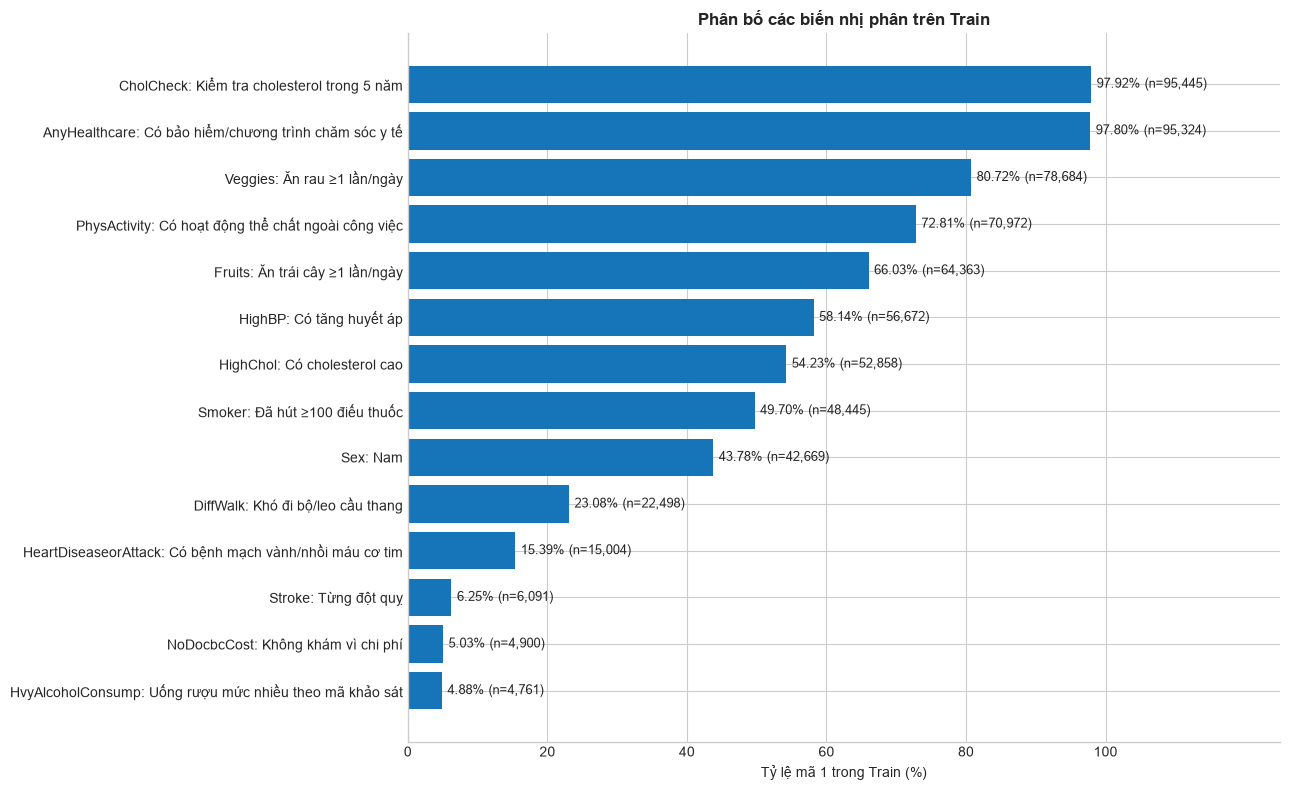

Nhóm ghi nhận tỷ lệ mã 1 thấp nhất ở **HvyAlcoholConsump (4.88%)** và cao nhất ở **CholCheck (97.92%)**. Nhóm chưa dùng phân bố này để kết luận biến nào liên quan mạnh đến nhãn.

In [23]:
binary_overall_summary = pd.concat([train_data.groupby(c).size().reindex([0,1],fill_value=0).rename("sample_count").rename_axis("Value").reset_index().assign(Feature=c) for c in BINARY],ignore_index=True)
binary_overall_summary["percent"] = 100.0*binary_overall_summary.sample_count/len(train_data)
save_frame(binary_overall_summary, "eda_binary_distribution_overall")
binary_meanings = {
    "HighBP": "Có tăng huyết áp", "HighChol": "Có cholesterol cao",
    "CholCheck": "Kiểm tra cholesterol trong 5 năm", "Smoker": "Đã hút ≥100 điếu thuốc",
    "Stroke": "Từng đột quỵ", "HeartDiseaseorAttack": "Có bệnh mạch vành/nhồi máu cơ tim",
    "PhysActivity": "Có hoạt động thể chất ngoài công việc", "Fruits": "Ăn trái cây ≥1 lần/ngày",
    "Veggies": "Ăn rau ≥1 lần/ngày", "HvyAlcoholConsump": "Uống rượu mức nhiều theo mã khảo sát",
    "AnyHealthcare": "Có bảo hiểm/chương trình chăm sóc y tế", "NoDocbcCost": "Không khám vì chi phí",
    "DiffWalk": "Khó đi bộ/leo cầu thang", "Sex": "Nam",
}
binary_positive = binary_overall_summary.query("Value == 1").sort_values("percent")
fig, ax = plt.subplots(figsize=(13,8))
labels = [f"{f}: {binary_meanings[f]}" for f in binary_positive.Feature]
bars = ax.barh(labels, binary_positive.percent, color=BLUE)
ax.bar_label(bars, labels=[f"{r.percent:.2f}% (n={r.sample_count:,})" for r in binary_positive.itertuples()], padding=4, fontsize=9)
ax.set(xlim=(0,125), xticks=[0,20,40,60,80,100], xlabel="Tỷ lệ mã 1 trong Train (%)", title="Phân bố các biến nhị phân trên Train")
fig.tight_layout()
save_and_show_figure("eda_04_binary_bars_overall", fig)
extremes = binary_positive.iloc[[0,-1]]
note("Nhóm ghi nhận tỷ lệ mã 1 thấp nhất ở **" + extremes.iloc[0].Feature + f" ({extremes.iloc[0]['percent']:.2f}%)** và cao nhất ở **" + extremes.iloc[1].Feature + f" ({extremes.iloc[1]['percent']:.2f}%)**. Nhóm chưa dùng phân bố này để kết luận biến nào liên quan mạnh đến nhãn.")


## 4.3. Tương quan từng cặp trên Train

Nhóm dùng một heatmap Pearson gồm 21 đặc trưng và nhãn `Diabetes_binary`. Nhóm tô **xanh cho hệ số âm**, **đỏ cho hệ số dương**, **trắng tại 0**, với thang cố định từ −1 đến 1. Nhóm hiển thị tam giác dưới và ghi hệ số trong từng ô để tránh lặp các cặp.

Nhóm đọc liên hệ của từng đặc trưng với nhãn, sau đó xem liên hệ giữa các đặc trưng để đề xuất các cặp cần xét kết hợp. Nhóm cân nhắc cả ý nghĩa của biến khi chọn cặp, chưa coi hệ số Pearson là bằng chứng về tác động độc lập, tương tác hoặc nhân quả. Với Age, Education, Income và GenHlth, nhóm tính Pearson trên mã thứ bậc; cách mã hóa có thể ảnh hưởng hệ số. Hệ số gần 0 cũng chưa đủ để loại một đặc trưng.


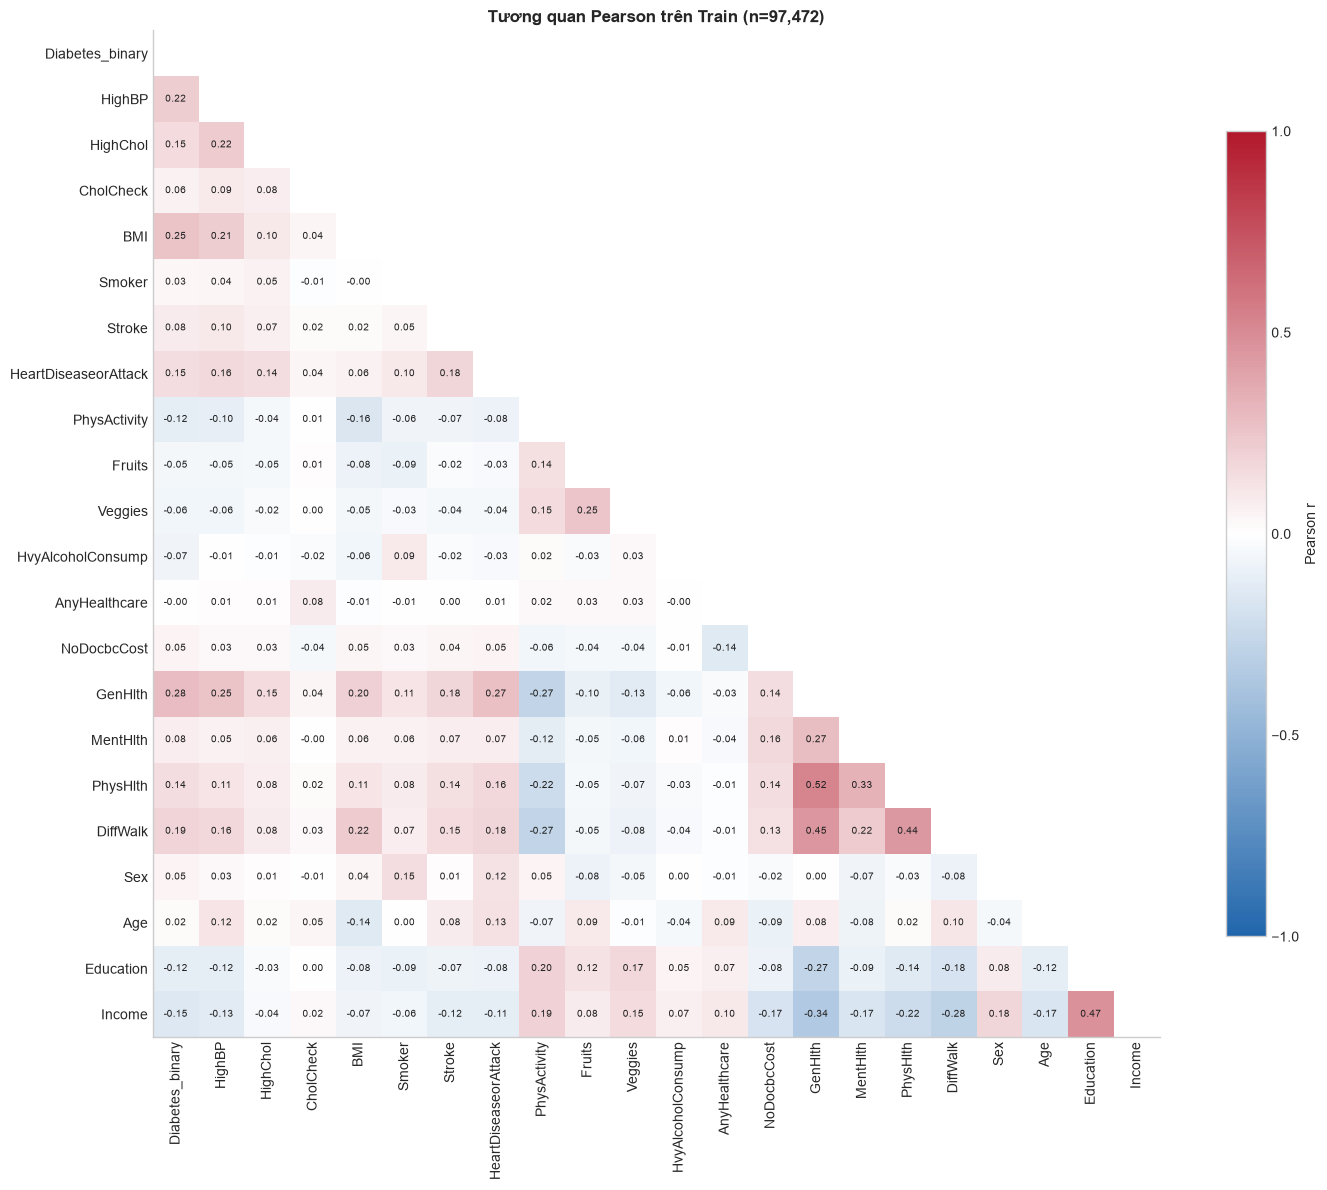

Nhóm dùng heatmap này để đề xuất cặp đặc trưng cho bước phân tích kết hợp. Nhóm trình bày bốn cặp đã chọn ở mục 4.4; nhóm chưa đánh giá tương tác thống kê.

In [24]:
correlation_columns = [TARGET] + FEATURES
correlation_frame = train_data[correlation_columns].corr(method="pearson")
assert correlation_frame.shape == (22,22)
assert not correlation_frame.isna().any().any()
pearson = correlation_frame.to_numpy()
correlation_target = correlation_frame[TARGET].drop(TARGET).rename("Pearson").rename_axis("Feature").reset_index()
correlation_pairs = pd.DataFrame([
    {"Feature A": a, "Feature B": b, "Pearson": correlation_frame.loc[a,b]}
    for i,a in enumerate(FEATURES) for b in FEATURES[i+1:]
])
CORRELATION_CMAP = LinearSegmentedColormap.from_list("blue_white_red", ["#2166AC", "#FFFFFF", "#B2182B"])
mask = np.triu(np.ones(pearson.shape,dtype=bool))
fig, ax = plt.subplots(figsize=(15,12))
heat = ax.imshow(np.ma.array(pearson,mask=mask), cmap=CORRELATION_CMAP,vmin=-1,vmax=1)
for i,j in zip(*np.where(~mask)):
    ax.text(j,i,f"{pearson[i,j]:.2f}",ha="center",va="center",fontsize=7,
            color="white" if abs(pearson[i,j]) > .65 else "#222222")
ax.set(xticks=np.arange(22),yticks=np.arange(22),xticklabels=correlation_columns,yticklabels=correlation_columns,
       title=f"Tương quan Pearson trên Train (n={len(train_data):,})")
ax.tick_params(axis="x",labelrotation=90)
ax.grid(False)
fig.colorbar(heat,ax=ax,shrink=.8,label="Pearson r",ticks=[-1,-.5,0,.5,1])
fig.tight_layout()
save_and_show_figure("eda_09_correlation",fig)
save_frame(correlation_frame.rename_axis("Feature").reset_index(),"correlation_matrix_22")
save_frame(correlation_target,"correlation_target")
save_frame(correlation_pairs,"correlation_pairs")
note("Nhóm dùng heatmap này để đề xuất cặp đặc trưng cho bước phân tích kết hợp. Nhóm trình bày bốn cặp đã chọn ở mục 4.4; nhóm chưa đánh giá tương tác thống kê.")


## 4.4. Xét cặp đặc trưng với nhãn

Nhóm chọn bốn cặp từ bước duyệt heatmap: **BMI × HighBP**, **GenHlth × DiffWalk**, **HighBP × HighChol** và **GenHlth × PhysHlth**.

Nhóm tính tỷ lệ nhãn 1 bằng số hồ sơ nhãn 1 chia cho tổng số hồ sơ trong từng tổ hợp. Nhóm ghi tỷ lệ và số hồ sơ `n` trong mỗi ô, dùng chung thang màu 0–100%. Ô xám có n=0; dấu * đánh dấu ô có 1–29 hồ sơ để người đọc cân nhắc quy mô mẫu.

Nhóm chia BMI thành <18,5; 18,5–<25; 25–<30; ≥30 để hiển thị. Với PhysHlth, nhóm dùng khoảng 0–4, 5–9, 10–14, 15–19, 20–24, 25–29 và 30 ngày. Nhóm giữ giá trị BMI thập phân và số ngày gốc trong dữ liệu mô hình. GenHlth có mã 1–5, từ sức khỏe tự đánh giá xuất sắc đến kém.

Nhóm mô tả các tổ hợp trên Train, chưa điều chỉnh theo các đặc trưng khác hoặc kiểm định tương tác thống kê. Nhóm chưa dùng kết quả này để kết luận nhân quả.


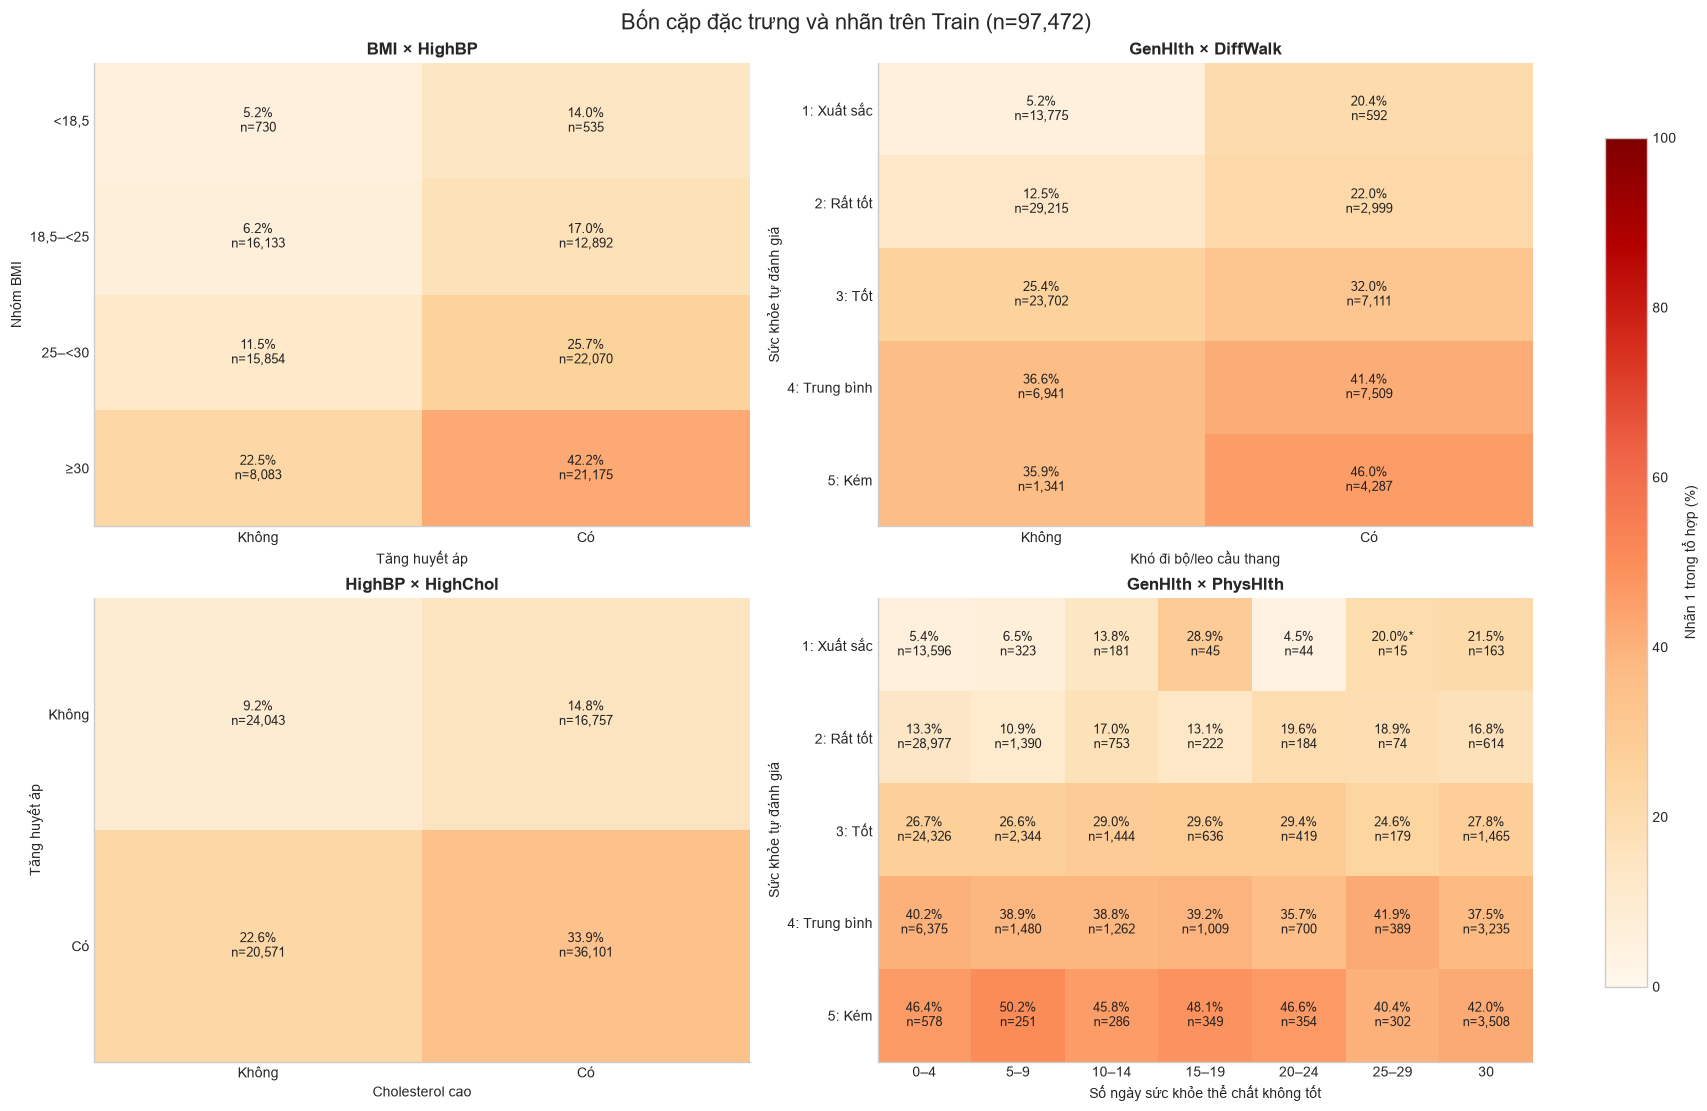

**BMI × HighBP:** Trong các ô có n ≥ 30, nhóm ghi nhận tỷ lệ nhãn 1 thấp nhất ở **<18,5 / nan**: **5.21%**, n=730; cao nhất ở **≥30 / nan**: **42.20%**, n=21,175.

**GenHlth × DiffWalk:** Trong các ô có n ≥ 30, nhóm ghi nhận tỷ lệ nhãn 1 thấp nhất ở **1: Xuất sắc / nan**: **5.17%**, n=13,775; cao nhất ở **5: Kém / nan**: **45.98%**, n=4,287.

**HighBP × HighChol:** Trong các ô có n ≥ 30, nhóm ghi nhận tỷ lệ nhãn 1 thấp nhất ở **nan / nan**: **9.17%**, n=24,043; cao nhất ở **nan / nan**: **33.87%**, n=36,101.

**GenHlth × PhysHlth:** Trong các ô có n ≥ 30, nhóm ghi nhận tỷ lệ nhãn 1 thấp nhất ở **1: Xuất sắc / 20–24**: **4.55%**, n=44; cao nhất ở **5: Kém / 5–9**: **50.20%**, n=251.

In [25]:
pair_data = train_data.copy(deep=True)
pair_data["BMI_group"] = pd.cut(pair_data.BMI, [-np.inf,18.5,25,30,np.inf], right=False, labels=False)
pair_data["PhysHlth_group"] = pd.cut(pair_data.PhysHlth, [0,5,10,15,20,25,30,31], right=False, labels=False)
bmi_pair_labels = ["<18,5", "18,5–<25", "25–<30", "≥30"]
gen_pair_labels = ["1: Xuất sắc", "2: Rất tốt", "3: Tốt", "4: Trung bình", "5: Kém"]
day_pair_labels = ["0–4", "5–9", "10–14", "15–19", "20–24", "25–29", "30"]
pair_specs = [
    ("BMI_group", "HighBP", range(4), [0,1], bmi_pair_labels, ["Không", "Có"], "Nhóm BMI", "Tăng huyết áp"),
    ("GenHlth", "DiffWalk", range(1,6), [0,1], gen_pair_labels, ["Không", "Có"], "Sức khỏe tự đánh giá", "Khó đi bộ/leo cầu thang"),
    ("HighBP", "HighChol", [0,1], [0,1], ["Không", "Có"], ["Không", "Có"], "Tăng huyết áp", "Cholesterol cao"),
    ("GenHlth", "PhysHlth_group", range(1,6), range(7), gen_pair_labels, day_pair_labels, "Sức khỏe tự đánh giá", "Số ngày sức khỏe thể chất không tốt"),
]
pair_tables = {}
fig, axes = plt.subplots(2,2,figsize=(17,11),layout="constrained")
pair_cmap = plt.get_cmap("OrRd").copy()
pair_cmap.set_bad("#DDDDDD")
for ax, (a,b,rows,cols,row_labels,col_labels,ylabel,xlabel) in zip(axes.flat,pair_specs):
    index = pd.MultiIndex.from_product([rows,cols], names=[a,b])
    summary = pair_data.groupby([a,b])[TARGET].agg(sample_count="size", positive_count="sum").reindex(index)
    summary[["sample_count","positive_count"]] = summary[["sample_count","positive_count"]].fillna(0).astype("int64")
    summary["positive_rate"] = 100.0*summary.positive_count/summary.sample_count.replace(0,np.nan)
    assert summary.sample_count.sum() == len(train_data)
    assert summary.positive_count.sum() == int(train_data[TARGET].sum())
    sizes = summary.sample_count.to_numpy().reshape(len(rows),len(cols))
    rates = summary.positive_rate.to_numpy().reshape(sizes.shape)
    heat = ax.imshow(np.ma.masked_invalid(rates),cmap=pair_cmap,vmin=0,vmax=100,aspect="auto")
    for i,j in np.ndindex(sizes.shape):
        label = "n=0" if sizes[i,j]==0 else f"{rates[i,j]:.1f}%{'*' if sizes[i,j]<30 else ''}\nn={sizes[i,j]:,}"
        ax.text(j,i,label,ha="center",va="center",fontsize=9,color="white" if rates[i,j]>65 else "#222222")
    ax.set(xticks=np.arange(len(cols)),yticks=np.arange(len(rows)),xticklabels=col_labels,yticklabels=row_labels,
           xlabel=xlabel,ylabel=ylabel,title=f"{a.replace('_group','')} × {b.replace('_group','')}")
    ax.grid(False)
    result = summary.reset_index()
    result["row_label"] = result[a].map(dict(zip(rows,row_labels)))
    result["column_label"] = result[b].map(dict(zip(cols,col_labels)))
    pair_tables[(a,b)] = result
    save_frame(result,f"eda_pair_{a}_{b}")
fig.colorbar(heat,ax=axes.ravel().tolist(),shrink=.85,label="Nhãn 1 trong tổ hợp (%)",ticks=[0,20,40,60,80,100])
fig.suptitle(f"Bốn cặp đặc trưng và nhãn trên Train (n={len(train_data):,})",fontsize=16)
save_and_show_figure("eda_four_pairs",fig)
for (a,b), result in pair_tables.items():
    valid = result.loc[result.sample_count.ge(30)]
    lowest = valid.loc[valid.positive_rate.idxmin()]
    highest = valid.loc[valid.positive_rate.idxmax()]
    note(f"**{a.replace('_group','')} × {b.replace('_group','')}:** Trong các ô có n ≥ 30, nhóm ghi nhận tỷ lệ nhãn 1 thấp nhất ở "
         f"**{lowest.row_label} / {lowest.column_label}**: **{lowest.positive_rate:.2f}%**, n={int(lowest.sample_count):,}; "
         f"cao nhất ở **{highest.row_label} / {highest.column_label}**: **{highest.positive_rate:.2f}%**, n={int(highest.sample_count):,}.")
pd.testing.assert_frame_equal(pair_data[train_data.columns],train_data)


### Cặp bổ sung: Income × Education

Nhóm xét 48 tổ hợp từ 8 mức thu nhập và 6 mức học vấn trên Train. Mỗi ô ghi tỷ lệ nhãn 1 và số hồ sơ; nhóm đánh dấu * với n < 30 và tô xám ô không có hồ sơ. Nhóm dùng tỷ lệ trong từng tổ hợp, chưa điều chỉnh các biến khác hoặc kiểm định tương tác.


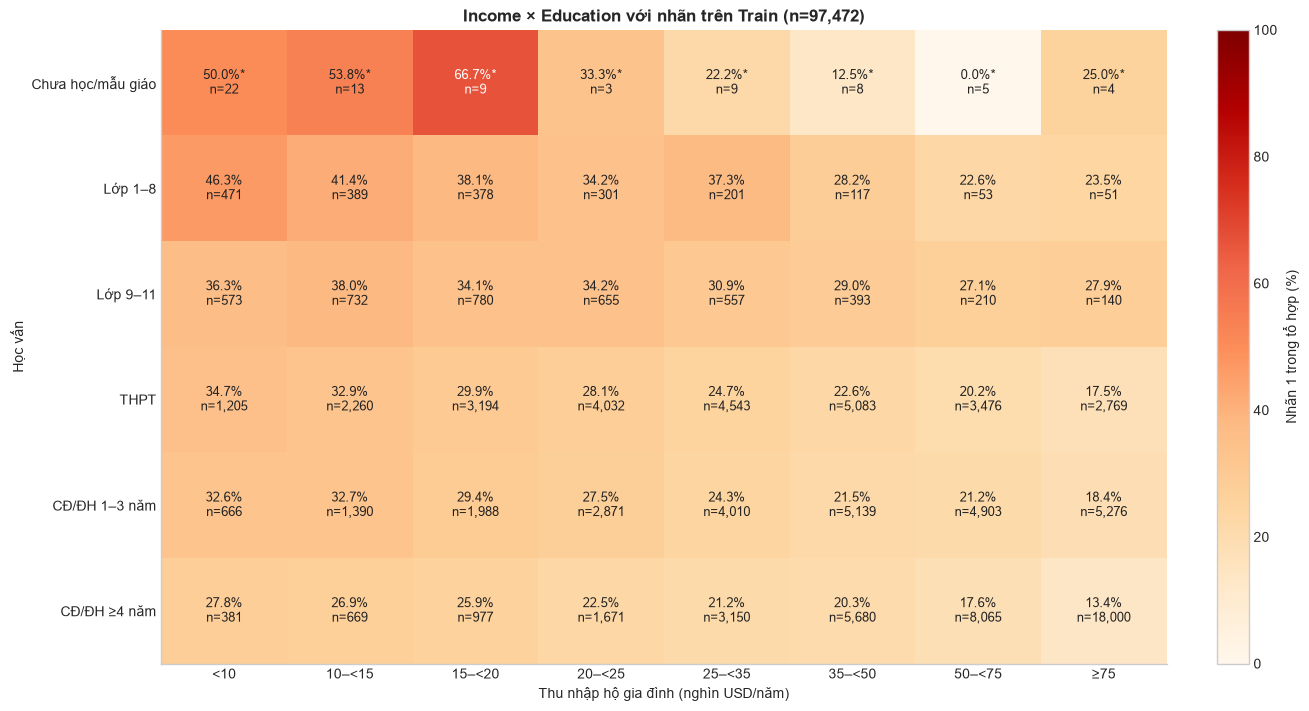

,Education,Income,sample_count,positive_count,positive_rate
0,1,1,22,11,50.000000
1,1,2,13,7,53.846154
2,1,3,9,6,66.666667
3,1,4,3,1,33.333333
4,1,5,9,2,22.222222
5,1,6,8,1,12.500000
6,1,7,5,0,0.000000
7,1,8,4,1,25.000000


Nhóm ghi nhận 48 tổ hợp có hồ sơ, 8 tổ hợp có 1–29 hồ sơ và 0 tổ hợp trống. Nhóm giữ các tổ hợp và đánh dấu mức ít hồ sơ để cân nhắc khi diễn giải.

In [26]:
income_labels = ["<10", "10–<15", "15–<20", "20–<25", "25–<35", "35–<50", "50–<75", "≥75"]
education_labels = ["Chưa học/mẫu giáo", "Lớp 1–8", "Lớp 9–11", "THPT", "CĐ/ĐH 1–3 năm", "CĐ/ĐH ≥4 năm"]
income_education_summary = train_data.groupby(["Education","Income"])[TARGET].agg(sample_count="size",positive_count="sum").reindex(pd.MultiIndex.from_product([range(1,7),range(1,9)],names=["Education","Income"]))
income_education_summary[["sample_count","positive_count"]] = income_education_summary[["sample_count","positive_count"]].fillna(0).astype("int64")
income_education_summary["positive_rate"] = 100.0*income_education_summary.positive_count/income_education_summary.sample_count.replace(0,np.nan)
assert income_education_summary.sample_count.sum() == len(train_data)
assert income_education_summary.positive_count.sum() == int(train_data[TARGET].sum())
rates = income_education_summary.positive_rate.to_numpy().reshape(6,8)
counts = income_education_summary.sample_count.to_numpy().reshape(6,8)
cmap = plt.get_cmap("OrRd").copy()
cmap.set_bad("#DDDDDD")
fig,ax = plt.subplots(figsize=(13,7),layout="constrained")
heat = ax.imshow(np.ma.masked_invalid(rates),cmap=cmap,vmin=0,vmax=100,aspect="auto")
for i,j in np.ndindex(counts.shape):
    label = "n=0" if counts[i,j]==0 else f"{rates[i,j]:.1f}%{'*' if counts[i,j]<30 else ''}\nn={counts[i,j]:,}"
    ax.text(j,i,label,ha="center",va="center",fontsize=9,color="white" if rates[i,j]>65 else "#222222")
ax.set(xticks=np.arange(8),yticks=np.arange(6),xticklabels=income_labels,yticklabels=education_labels,
       xlabel="Thu nhập hộ gia đình (nghìn USD/năm)",ylabel="Học vấn",title=f"Income × Education với nhãn trên Train (n={len(train_data):,})")
ax.grid(False)
fig.colorbar(heat,ax=ax,label="Nhãn 1 trong tổ hợp (%)",ticks=[0,20,40,60,80,100])
save_and_show_figure("eda_income_education",fig)
save_frame(income_education_summary.reset_index(),"eda_pair_Income_Education")
sparse_income_education = income_education_summary.loc[income_education_summary.sample_count.lt(30)].reset_index()
display(sparse_income_education)
note(f"Nhóm ghi nhận {(income_education_summary.sample_count>0).sum()} tổ hợp có hồ sơ, "
     f"{income_education_summary.sample_count.between(1,29).sum()} tổ hợp có 1–29 hồ sơ và "
     f"{income_education_summary.sample_count.eq(0).sum()} tổ hợp trống. Nhóm giữ các tổ hợp và đánh dấu mức ít hồ sơ để cân nhắc khi diễn giải.")


## 4.5. Bộ 17 biến và năm biến tương tác

Nhóm chốt loại **AnyHealthcare, Age, Smoker, Sex** khỏi bộ rút gọn theo ngưỡng |Pearson r| < 0,05 trên Train. Nhóm giữ **HighBP, HighChol, CholCheck, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, NoDocbcCost, GenHlth, MentHlth, PhysHlth, DiffWalk, Education, Income**. Nhóm giữ phạm vi người từ 60 tuổi trở lên và bộ 21 biến gốc để đối chứng; nhóm chưa kết luận bốn biến bị loại không có thông tin khi kết hợp với biến khác.

| Biến mới | Công thức | Mục đích |
|---|---|---|
| BMI_HighBP | BMI × HighBP | Kết hợp BMI và tăng huyết áp |
| GenHlth_DiffWalk | (GenHlth − 1) × DiffWalk | Kết hợp mức sức khỏe tự đánh giá và khó khăn đi lại |
| HighBP_HighChol | HighBP × HighChol | Đánh dấu đồng thời có tăng huyết áp và cholesterol cao |
| Income_Education | Ghép nhãn Income và Education, ví dụ I3_E4 | Biến phân loại tổ hợp thu nhập và học vấn |
| GenHlth_PhysHlth | (GenHlth − 1) × PhysHlth | Thăm dò kết hợp sức khỏe tự đánh giá và số ngày sức khỏe thể chất không tốt |

Nhóm dùng bộ 17 biến như phương án rút gọn ở lượt đầu. Sau khi đối chiếu CV, nhóm giữ 21 biến gốc làm điểm xuất phát cho các lượt thử tương tác, dùng BMI thập phân và số ngày gốc. Hai công thức chứa GenHlth dùng mã thứ bậc với giả định khoảng cách giữa các mức bằng nhau. Nhóm chỉ dùng các công thức cố định từ đặc trưng, không dùng nhãn để tính biến mới.

Nhóm chạy lượt đầu với baseline 21 biến và bộ 17 biến. Sau khi duyệt kết quả, nhóm sẽ thử từng biến mới trên bộ đang giữ. Nhóm đã duyệt giữ 21 biến gốc sau lượt đầu. Nhóm đã chốt Logistic Regression với 21 biến gốc và GenHlth_PhysHlth; XGBoost với 21 biến gốc, GenHlth_DiffWalk và HighBP_HighChol. Nhóm không giữ phương án Income_Education; nhóm giữ công thức năm biến mới để mô tả các lượt thử đã thực hiện.

Nhóm tạo Income_Education dưới dạng chuỗi phân loại (I2_E6 khác I3_E4), không nhân mã hoặc áp đặt thứ tự giữa các tổ hợp. Khi chạy mô hình, nhóm sẽ dùng one-hot cho biến này và fit bộ mã hóa trong từng fold Train; nhóm chưa fit bộ mã hóa tại bước tạo biến. Số cột sau mã hóa có thể khác số đặc trưng trước mã hóa. Nhóm chưa kết luận biến mới cải thiện mô hình.

### Ghi chú thuyết trình: vì sao bỏ Income và Education khi dùng biến kết hợp?

Trong lượt thử biến thứ năm tại mục 6.5 (lượt thứ sáu nếu tính cả so sánh 21/17 ban đầu), nhóm tạo `Income_Education` từ hai cột nguồn rồi bỏ `Income` và `Education` khỏi danh sách đặc trưng đầu vào của lượt đó. Nhóm vẫn giữ hai cột nguồn trong dữ liệu để tạo biến và đối chiếu. Ví dụ, từ `I3_E4`, nhóm xác định được Income = 3 và Education = 4; nhóm giữ nguyên thông tin về hai mã trong biến tổ hợp.

Nhóm chọn cách thay thế để hạn chế biểu diễn lặp thông tin. Nếu nhóm one-hot đầy đủ cả biến tổ hợp lẫn hai biến gốc, nhóm có thể cộng các cột tổ hợp tương ứng để thu được cột chỉ báo của từng mức Income hoặc Education. Nhóm khi đó tạo các cột phụ thuộc tuyến tính, khiến việc xác định và diễn giải riêng từng hệ số Logistic Regression gặp khó khăn. Nhóm cũng không cần đưa thêm hai biến gốc để lặp lại các mã đã có trong tổ hợp.

Nhóm không coi việc bỏ hai biến gốc là yêu cầu bắt buộc cho mọi mô hình hoặc bằng chứng giúp tăng chất lượng dự đoán. Khi thay thế, nhóm thay đổi cách biểu diễn và khả năng chia sẻ thông tin giữa các tổ hợp; nhóm cần lưu ý các tổ hợp ít hồ sơ hoặc chưa xuất hiện trong fold huấn luyện. Nhóm đánh giá phương án bằng cùng các fold trên Train trước khi chốt. Trong lượt này, nhóm so sánh **phương án thay thế hai biến bằng một biến tổ hợp**, thay vì chỉ đo tác dụng của việc thêm một biến.

**Phạm vi cập nhật:** Nhóm ghi nhận lý do thiết kế ở đây. Nhóm triển khai và đánh giá phương án thay thế ở mục 6.5 trên Train; nhóm đã chốt không giữ phương án này.


In [27]:
DROPPED_WEAK_FEATURES = ["AnyHealthcare", "Age", "Smoker", "Sex"]
BASE_FEATURES_17 = [c for c in FEATURES if c not in DROPPED_WEAK_FEATURES]
INTERACTION_FEATURES = ["BMI_HighBP", "GenHlth_DiffWalk", "HighBP_HighChol", "GenHlth_PhysHlth"]
CATEGORICAL_INTERACTION_FEATURES = ["Income_Education"]
assert len(BASE_FEATURES_17) == 17

def add_interaction_features(frame):
    """Create fixed interactions without changing the input or using its label."""
    result = frame.copy(deep=True)
    result["BMI_HighBP"] = frame["BMI"].astype(float) * frame["HighBP"].astype(float)
    result["GenHlth_DiffWalk"] = (frame["GenHlth"].astype(float)-1) * frame["DiffWalk"].astype(float)
    result["HighBP_HighChol"] = frame["HighBP"].astype(float) * frame["HighChol"].astype(float)
    result["GenHlth_PhysHlth"] = (frame["GenHlth"].astype(float)-1) * frame["PhysHlth"].astype(float)
    assert np.isfinite(result[INTERACTION_FEATURES].to_numpy()).all()
    assert frame.Income.isin(range(1,9)).all() and frame.Education.isin(range(1,7)).all()
    result["Income_Education"] = "I" + frame.Income.astype("int64").astype(str) + "_E" + frame.Education.astype("int64").astype(str)
    return result

# Distinct names keep these approved candidates separate from legacy model configurations.
candidate_feature_sets = {
    "baseline_21": FEATURES.copy(),
    "final_lr_22": FEATURES + ["GenHlth_PhysHlth"],
    "final_xgb_23": FEATURES + ["GenHlth_DiffWalk", "HighBP_HighChol"],
}
candidate_categorical_features = {name: [c for c in cols if c=="Income_Education"] for name,cols in candidate_feature_sets.items()}

modeling_data_with_interactions = add_interaction_features(clean_data)
train_data_with_interactions = add_interaction_features(train_data)
X_train_candidates = {
    name: train_data_with_interactions[columns].copy()
    for name,columns in candidate_feature_sets.items()
}
pd.testing.assert_frame_equal(modeling_data_with_interactions[clean_data.columns],clean_data)
pd.testing.assert_frame_equal(train_data_with_interactions[train_data.columns],train_data)
assert modeling_data_with_interactions.row_id.equals(clean_data.row_id)
assert train_data_with_interactions.BMI.dtype == np.dtype("float64")
assert train_data_with_interactions.loc[train_data.HighBP.eq(0),"BMI_HighBP"].eq(0).all()
assert train_data_with_interactions.loc[train_data.DiffWalk.eq(0),"GenHlth_DiffWalk"].eq(0).all()
assert train_data_with_interactions.HighBP_HighChol.eq(train_data.HighBP.eq(1)&train_data.HighChol.eq(1)).all()
assert train_data_with_interactions.GenHlth_PhysHlth.between(0,120).all()
assert TARGET not in {c for cols in candidate_feature_sets.values() for c in cols}
candidate_summary = pd.DataFrame([
    {"Bộ đặc trưng":name,"Số đặc trưng":len(cols),"Các biến":", ".join(cols)}
    for name,cols in candidate_feature_sets.items()
])
display(candidate_summary)
interaction_summary = train_data_with_interactions[INTERACTION_FEATURES].describe().T
display(interaction_summary.round(2))
save_frame(candidate_summary,"approved_candidate_feature_sets")
save_frame(interaction_summary.rename_axis("Feature").reset_index(),"interaction_train_summary")
print(f"Nhóm đã tạo 5 biến tương tác cho {len(modeling_data_with_interactions):,} hồ sơ; giữ nguyên row_id và bản chia Train/Test.")
print("Nhóm chỉ tạo các biến ứng viên tại bước này. Bộ cuối: Logistic Regression 22 đặc trưng; XGBoost 23 đặc trưng trước mã hóa. Kết quả thử nghiệm ở phần VI–VII.")


Nhóm đã tạo 5 biến tương tác cho 121,839 hồ sơ; giữ nguyên row_id và bản chia Train/Test.
Nhóm chỉ tạo các biến ứng viên tại bước này. Bộ cuối: Logistic Regression 22 đặc trưng; XGBoost 23 đặc trưng trước mã hóa. Kết quả thử nghiệm ở phần VI–VII.


,Bộ đặc trưng,Số đặc trưng,Các biến
0,baseline_21,21,"HighBP, HighChol, CholCheck, BMI, Smoker, Stro..."
1,final_lr_22,22,"HighBP, HighChol, CholCheck, BMI, Smoker, Stro..."
2,final_xgb_23,23,"HighBP, HighChol, CholCheck, BMI, Smoker, Stro..."


,count,mean,std,min,25%,50%,75%,max
BMI_HighBP,97472.0,16.98,15.18,0.0,0.0,23.44,29.18,97.65
GenHlth_DiffWalk,97472.0,0.58,1.17,0.0,0.0,0.00,0.00,4.00
HighBP_HighChol,97472.0,0.37,0.48,0.0,0.0,0.00,1.00,1.00
GenHlth_PhysHlth,97472.0,13.22,29.65,0.0,0.0,0.00,6.00,120.00


## 4.6. Kiểm tra VIF trên bộ 17 biến

Nhóm tính VIF trên 17 biến gốc đã chốt, dùng **Train**, giữ hồ sơ trùng, không đưa nhãn hoặc năm biến tương tác vào phép tính. Với mỗi biến j, nhóm hồi quy biến đó theo 16 biến còn lại và hệ số chặn, rồi tính **VIF = 1 / (1 − R²)**. Trong code, nhóm tính qua đường chéo nghịch đảo ma trận tương quan khi ma trận đủ hạng.

Nhóm dùng mã số gốc của GenHlth, Education và Income nên giả định quan hệ tuyến tính giữa các mã thứ bậc. Nhóm dùng kết quả để xem phụ thuộc tuyến tính trong bộ 17 biến; nhóm chưa kiểm tra ma trận sau one-hot hoặc bộ có tương tác. Nhóm không dùng VIF để đo liên hệ với nhãn hay chất lượng dự đoán.


,Feature,VIF,R2_auxiliary
0,GenHlth,1.7749,0.4366
1,PhysHlth,1.5680,0.3622
2,DiffWalk,1.4511,0.3109
3,Income,1.4442,0.3076
4,Education,1.3408,0.2542
5,MentHlth,1.1673,0.1433
6,PhysActivity,1.1643,0.1411
7,HighBP,1.1623,0.1396
8,HeartDiseaseorAttack,1.1198,0.1070
9,BMI,1.1150,0.1032


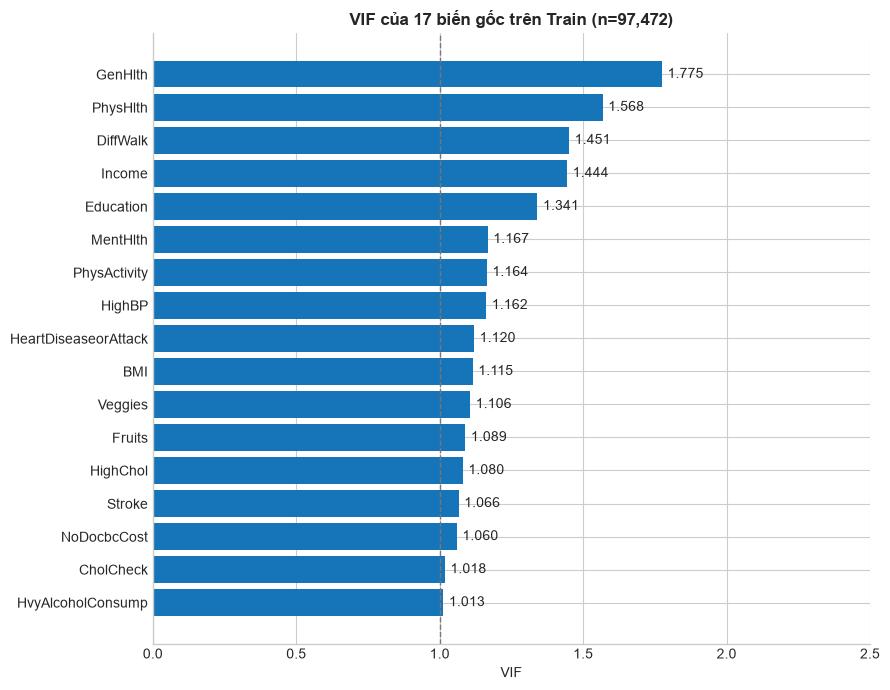

Nhóm ghi nhận VIF từ **1.013** đến **1.775**; cao nhất là **GenHlth**. Nhóm kiểm tra ma trận đủ hạng **17/17**. Nhóm chưa có lý do loại thêm biến trong bộ rút gọn từ kết quả VIF này. Nhóm đã thử bộ 17 biến rồi giữ 21 biến gốc theo CV; VIF ở đây không đại diện cho ma trận đầu vào cuối sau mã hóa và thêm tương tác. Nhóm cần kiểm tra riêng cách mã hóa và các biến tương tác khi xác định đầu vào Logistic Regression.

In [28]:
vif_input_17 = train_data[BASE_FEATURES_17].astype(float)
assert vif_input_17.shape == (len(train_data),17)
assert TARGET not in vif_input_17.columns
assert not vif_input_17.isna().any().any()
vif_scale = vif_input_17.std(ddof=0)
assert vif_scale.gt(0).all(), "VIF không xác định cho biến hằng."
vif_standardized = (vif_input_17-vif_input_17.mean())/vif_scale
vif_correlation_17 = vif_standardized.corr().to_numpy()
vif_rank_17 = np.linalg.matrix_rank(vif_correlation_17)
assert vif_rank_17 == 17, "Ma trận suy biến: cần kiểm tra phụ thuộc tuyến tính chính xác."
vif_values_17 = np.diag(np.linalg.inv(vif_correlation_17))
assert np.isfinite(vif_values_17).all() and np.all(vif_values_17>=1-1e-8)
vif_results_17 = pd.DataFrame({"Feature":BASE_FEATURES_17,"VIF":vif_values_17,
                             "R2_auxiliary":1-1/vif_values_17}).sort_values(["VIF","Feature"],ascending=[False,True]).reset_index(drop=True)
display(vif_results_17.round(4))
save_frame(vif_results_17,"vif_base17_train")
fig,ax = plt.subplots(figsize=(9,7))
ordered_vif = vif_results_17.sort_values("VIF")
bars = ax.barh(ordered_vif.Feature,ordered_vif.VIF,color=BLUE)
ax.bar_label(bars,fmt="%.3f",padding=4)
ax.axvline(1,color="#777777",linestyle="--",linewidth=1)
ax.set(xlim=(0,max(2.5,vif_values_17.max()*1.2)),xlabel="VIF",title=f"VIF của 17 biến gốc trên Train (n={len(train_data):,})")
fig.tight_layout()
save_and_show_figure("vif_base17_train",fig)
top_vif = vif_results_17.iloc[0]
note(f"Nhóm ghi nhận VIF từ **{vif_values_17.min():.3f}** đến **{vif_values_17.max():.3f}**; "
     f"cao nhất là **{top_vif.Feature}**. Nhóm kiểm tra ma trận đủ hạng **{vif_rank_17}/17**. "
     "Nhóm chưa có lý do loại thêm biến trong bộ rút gọn từ kết quả VIF này. Nhóm đã thử bộ 17 biến rồi giữ 21 biến gốc theo CV; VIF ở đây không đại diện cho ma trận đầu vào cuối sau mã hóa và thêm tương tác. "
     "Nhóm cần kiểm tra riêng cách mã hóa và các biến tương tác khi xác định đầu vào Logistic Regression.")


# V. Thiết lập thử nghiệm tuần tự

## 5.1. Lượt đầu: baseline 21 biến và bộ 17 biến

Nhóm so sánh **2 bộ đặc trưng × 4 mô hình × 1 cách xử lý mất cân bằng = 8 cấu hình**, mỗi cấu hình dùng 5 fold trên Train, tổng cộng 40 lần huấn luyện. Nhóm giữ hồ sơ trùng, dùng trọng số lớp và ngưỡng phân loại 0,5; nhóm chưa lấy mẫu NearMiss hoặc SMOTENC.

Nhóm dùng **Average Precision (AP) trung bình qua 5 fold** làm chỉ số chính; nhóm báo cáo độ lệch chuẩn giữa các fold cùng Precision, Recall, F1, Accuracy và ROC AUC. Nhóm dùng AP để so sánh khả năng xếp hạng nhãn 1; nhóm dùng ngưỡng 0,5 để tính các chỉ số phân loại. Nhóm giữ kết quả chưa làm tròn trong file CSV.

Nhóm tạo StratifiedGroupKFold 5 fold, shuffle=True, random_state=43, trong Train. Nhóm giữ các hồ sơ có cùng 21 đặc trưng gốc trong cùng fold và dùng chung fold cho cả hai bộ biến. Trong giai đoạn CV, nhóm chưa dùng chỉ số hiệu năng Test để chọn cấu hình.

| Mô hình | Thiết lập cố định |
|---|---|
| Logistic Regression | C=1; solver=lbfgs; max_iter=1500; class_weight=balanced |
| Decision Tree | max_depth=8; min_samples_leaf=50; class_weight=balanced |
| Random Forest | 100 cây; max_depth=16; min_samples_leaf=20; class_weight=balanced |
| XGBoost | 100 cây; max_depth=6; learning_rate=0,1; scale_pos_weight=n₀/n₁ trong phần huấn luyện của fold |

Nhóm giữ random_state=42 và tối đa 4 luồng tính toán. Nhóm chưa tối ưu siêu tham số. Với Logistic Regression, nhóm chuẩn hóa BMI, MentHlth và PhysHlth, one-hot các biến thứ bậc và giữ biến nhị phân 0/1. Với mô hình cây, nhóm dùng các giá trị số gốc. Nhóm fit scaler và encoder trong phần huấn luyện của từng fold.

## 5.2. Cách chốt qua từng lượt

Sau lượt đầu, nhóm giữ Logistic Regression và XGBoost theo quyết định đã duyệt từ AP trung bình, độ lệch chuẩn và các chỉ số phụ. Nhóm duyệt kết quả từng lượt trước khi thử biến tương tác tiếp theo. Mỗi lượt sau so sánh bộ đang giữ với đúng một thay đổi, dùng chung fold và thiết lập mô hình. Nhóm giữ baseline 21 biến làm mốc.

Nhóm đã chọn bộ 17 biến bằng EDA trên toàn bộ Train, nên kết quả CV là so sánh khám phá có thể lạc quan do bước chọn biến trước CV. Nhóm chưa thực hiện nested CV. Nhóm dành Test cho đánh giá cuối sau khi chốt quy trình; các kết quả CV chưa chứng minh khả năng chẩn đoán lâm sàng.

**Tổng số thực thi:** Nhóm thử 18 cấu hình qua CV: 8 cấu hình ở lượt đầu và 10 cấu hình qua năm lượt thử biến mới. Nhóm thực hiện 90 lần fit CV và 2 lần fit cuối trên toàn bộ Train. Nhóm dùng bộ 17 biến làm phương án so sánh; nhóm không chọn nó làm bộ cuối.


In [29]:
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBClassifier
from threadpoolctl import threadpool_limits
import sklearn, xgboost, warnings, time

INITIAL_FEATURE_SETS = {"baseline_21": FEATURES.copy(), "base_17": BASE_FEATURES_17.copy()}
MODEL_NAMES = ["LogisticRegression", "DecisionTree", "RandomForest", "XGBoost"]
CV_BASE = BASE / "initial_21_vs_17_cv5_ap"
CV_BASE.mkdir(exist_ok=True)
cv_data = train_data.sort_values("row_id").reset_index(drop=True).copy()
cv_groups = manifest.set_index("row_id").loc[cv_data.row_id,"group_id"].to_numpy()
assert set(cv_data.row_id) == set(manifest.loc[manifest.split.eq("train"),"row_id"])
cv_y = cv_data[TARGET].to_numpy(dtype=int)
# Use the same 0/1 serialization as the cleaned-data fingerprint.
cv_sha256 = hashlib.sha256(cv_data.astype({c: "int16" for c in [TARGET]+BINARY}).to_csv(index=False).encode()).hexdigest()
cv_path = CV_BASE / "cv_manifest.csv"
cv_design_path = CV_BASE / "cv_design.json"
cv_design = {"data_sha256":cv_sha256,"seed":43,"folds":5,"group_key":FEATURES,
             "outer_data_sha256":actual_sha256,"train_rows":len(cv_data)}
if cv_path.exists():
    assert json.loads(cv_design_path.read_text(encoding="utf-8")) == cv_design
    cv_manifest = pd.read_csv(cv_path)
else:
    cv_manifest = pd.DataFrame({"row_id":cv_data.row_id,"group_id":cv_groups,"fold":-1})
    splitter = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=43)
    for fold,(_,valid) in enumerate(splitter.split(cv_data[FEATURES],cv_y,cv_groups)):
        cv_manifest.loc[valid,"fold"] = fold
    cv_manifest.to_csv(cv_path,index=False)
    cv_design_path.write_text(json.dumps(cv_design,ensure_ascii=False,indent=2),encoding="utf-8")
assert np.array_equal(cv_manifest.row_id,cv_data.row_id)
assert np.array_equal(cv_manifest.group_id,cv_groups)
assert set(cv_manifest.fold)==set(range(5))
assert cv_manifest.groupby("group_id").fold.nunique().max()==1
fold_summary = cv_manifest.assign(label=cv_y).groupby("fold").agg(validation_rows=("label","size"),positive_rows=("label","sum"))
fold_summary["positive_percent"] = 100.0*fold_summary.positive_rows/fold_summary.validation_rows
fold_summary["fit_rows"] = len(cv_data)-fold_summary.validation_rows
display(fold_summary.reset_index().round(3))
save_frame(fold_summary.reset_index(),"cv5_train_fold_summary")

def initial_preprocessor(columns, linear):
    nominal=[c for c in columns if c=="Income_Education"]
    # Domains come from the survey codes, not observations or labels in validation/Test.
    joint_levels=[f"I{i}_E{e}" for i in range(1,9) for e in range(1,7)]
    nominal_transform=[("income_education",OneHotEncoder(categories=[joint_levels],drop="first" if linear else None,
                         handle_unknown="error",sparse_output=False),nominal)] if nominal else []
    if not linear:
        return ColumnTransformer([("features","passthrough",[c for c in columns if c not in nominal])]+nominal_transform,remainder="drop")
    numeric=[c for c in NUMERIC_FEATURES + ["BMI_HighBP", "GenHlth_DiffWalk", "GenHlth_PhysHlth"] if c in columns]
    ordinal=[c for c in ORDINAL_DOMAINS if c in columns]
    binary=[c for c in columns if c not in numeric+ordinal+nominal]
    return ColumnTransformer([
        ("numeric",StandardScaler(),numeric),
        ("ordinal",OneHotEncoder(categories=[ORDINAL_DOMAINS[c] for c in ordinal],drop="first",handle_unknown="error",sparse_output=False),ordinal),
        ("binary","passthrough",binary)]+nominal_transform,remainder="drop")

def initial_model(name, y_fit):
    if name=="LogisticRegression":
        return LogisticRegression(C=1.0,solver="lbfgs",max_iter=1500,random_state=42,class_weight="balanced")
    if name=="DecisionTree":
        return DecisionTreeClassifier(max_depth=8,min_samples_leaf=50,random_state=42,class_weight="balanced")
    if name=="RandomForest":
        return RandomForestClassifier(n_estimators=100,max_depth=16,min_samples_leaf=20,n_jobs=4,random_state=42,class_weight="balanced")
    if name=="XGBoost":
        ratio=int((y_fit==0).sum())/int((y_fit==1).sum())
        return XGBClassifier(n_estimators=100,max_depth=6,learning_rate=.1,n_jobs=4,random_state=42,eval_metric="logloss",scale_pos_weight=ratio,tree_method="hist")
    raise ValueError(name)


,fold,validation_rows,positive_rows,positive_percent,fit_rows
0,0,19495,4311,22.113,77977
1,1,19494,4311,22.114,77978
2,2,19494,4311,22.114,77978
3,3,19495,4311,22.113,77977
4,4,19494,4311,22.114,77978


# VI. Kết quả CV và các quyết định chọn biến

## 6.0. Lượt đầu: 21 biến và 17 biến

Nhóm thực hiện 40 lần huấn luyện trên các fold đã chốt. Nhóm lưu dự đoán out-of-fold cho từng cấu hình và kết quả từng fold để kiểm tra lại. Nhóm chưa fit mô hình cuối trên toàn bộ Train và chưa dự đoán Test.


In [30]:
metric_names=["AP","ROC_AUC","Precision","Recall","F1","Accuracy"]
study_protocol={"feature_sets":INITIAL_FEATURE_SETS,"models":MODEL_NAMES,"primary_metric":"mean_fold_AP",
                "threshold":.5,"cv_design":cv_design,"weighting":"fit-fold class counts only",
                "versions":{"sklearn":sklearn.__version__,"xgboost":xgboost.__version__},
                "model_parameters":{name:initial_model(name,cv_y).get_params() for name in MODEL_NAMES}}
protocol_file=CV_BASE/"protocol.json"
if protocol_file.exists():
    assert protocol_file.read_text(encoding="utf-8")==json.dumps(study_protocol,ensure_ascii=False,indent=2)
else:
    protocol_file.write_text(json.dumps(study_protocol,ensure_ascii=False,indent=2),encoding="utf-8")
fold_file=CV_BASE/"fold_metrics.csv"
cv_records=pd.read_csv(fold_file).to_dict("records") if fold_file.exists() else []
for set_name,columns in INITIAL_FEATURE_SETS.items():
    for model_name in MODEL_NAMES:
        for fold in range(5):
            key=f"{set_name}__{model_name}__fold{fold}"
            pred_path=CV_BASE/(key+"_validation.csv")
            if any(r["key"]==key for r in cv_records):
                assert pred_path.exists()
                continue
            fit_idx=np.flatnonzero(cv_manifest.fold.to_numpy()!=fold)
            valid_idx=np.flatnonzero(cv_manifest.fold.to_numpy()==fold)
            assert not set(cv_groups[fit_idx]) & set(cv_groups[valid_idx])
            x_fit=cv_data.iloc[fit_idx][columns]
            x_valid=cv_data.iloc[valid_idx][columns]
            y_fit,y_valid=cv_y[fit_idx],cv_y[valid_idx]
            model=initial_model(model_name,y_fit)
            pipeline=Pipeline([("preprocess",initial_preprocessor(columns,model_name=="LogisticRegression")),("model",model)])
            start=time.monotonic()
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
                warnings.simplefilter("always")
                pipeline.fit(x_fit,y_fit)
                probability=pipeline.predict_proba(x_valid)[:,1]
            if any(issubclass(w.category,ConvergenceWarning) for w in caught):
                raise RuntimeError(f"{key}: convergence warning: {[str(w.message) for w in caught]}")
            assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
            pred=(probability>=.5).astype(int)
            record={"key":key,"FeatureSet":set_name,"Model":model_name,"Fold":fold,
                    "Features":len(columns),"FitRows":len(fit_idx),"ValidationRows":len(valid_idx),
                    "AP":average_precision_score(y_valid,probability),"ROC_AUC":roc_auc_score(y_valid,probability),
                    "Precision":precision_score(y_valid,pred,zero_division=0),"Recall":recall_score(y_valid,pred),
                    "F1":f1_score(y_valid,pred),"Accuracy":accuracy_score(y_valid,pred),
                    "Seconds":time.monotonic()-start,"Warnings":json.dumps([str(w.message) for w in caught]),
                    "EncodedColumns":len(pipeline.named_steps["preprocess"].get_feature_names_out())}
            pd.DataFrame({"row_id":cv_data.iloc[valid_idx].row_id.to_numpy(),"actual":y_valid,"probability":probability}).to_csv(pred_path,index=False)
            cv_records.append(record)
            pd.DataFrame(cv_records).to_csv(fold_file,index=False)
            print(f"[{len(cv_records)}/40] {key}: AP={record['AP']:.4f}",flush=True)
cv_metrics=pd.DataFrame(cv_records)
assert len(cv_metrics)==40 and cv_metrics.key.is_unique
assert cv_metrics.groupby(["FeatureSet","Model"]).size().eq(5).all()
cv_summary=cv_metrics.groupby(["FeatureSet","Model"])[metric_names].agg(["mean","std"])
cv_summary.columns=[f"{metric}_{stat}" for metric,stat in cv_summary.columns]
cv_summary=cv_summary.reset_index().sort_values("AP_mean",ascending=False).reset_index(drop=True)
display(cv_summary.round(4))
cv_summary.to_csv(CV_BASE/"summary.csv",index=False)
ap_comparison=cv_summary.pivot(index="Model",columns="FeatureSet",values="AP_mean")
ap_comparison["AP_delta_17_minus_21"]=ap_comparison.base_17-ap_comparison.baseline_21
display(ap_comparison.reset_index().round(4))
ap_comparison.reset_index().to_csv(CV_BASE/"ap_comparison.csv",index=False)
tree_candidates=cv_summary.loc[cv_summary.Model.ne("LogisticRegression")]
best_tree=tree_candidates.iloc[0]
note(f"Nhóm ghi nhận cấu hình cây có AP trung bình cao nhất là **{best_tree.Model} / {best_tree.FeatureSet}**, "
     f"AP **{best_tree.AP_mean:.4f} ± {best_tree.AP_std:.4f}**. Nhóm đã duyệt giữ Logistic Regression và XGBoost với 21 biến gốc để bắt đầu các lượt thử tương tác.")


[1/40] baseline_21__LogisticRegression__fold0: AP=0.4715
[2/40] baseline_21__LogisticRegression__fold1: AP=0.4631
[3/40] baseline_21__LogisticRegression__fold2: AP=0.4492
[4/40] baseline_21__LogisticRegression__fold3: AP=0.4624
[5/40] baseline_21__LogisticRegression__fold4: AP=0.4749
[6/40] baseline_21__DecisionTree__fold0: AP=0.4559
[7/40] baseline_21__DecisionTree__fold1: AP=0.4532
[8/40] baseline_21__DecisionTree__fold2: AP=0.4505
[9/40] baseline_21__DecisionTree__fold3: AP=0.4581
[10/40] baseline_21__DecisionTree__fold4: AP=0.4662
[11/40] baseline_21__RandomForest__fold0: AP=0.4817
[12/40] baseline_21__RandomForest__fold1: AP=0.4792
[13/40] baseline_21__RandomForest__fold2: AP=0.4671
[14/40] baseline_21__RandomForest__fold3: AP=0.4808
[15/40] baseline_21__RandomForest__fold4: AP=0.4882
[16/40] baseline_21__XGBoost__fold0: AP=0.4825
[17/40] baseline_21__XGBoost__fold1: AP=0.4804
[18/40] baseline_21__XGBoost__fold2: AP=0.4675
[19/40] baseline_21__XGBoost__fold3: AP=0.4815
[20/40] bas

,FeatureSet,Model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,baseline_21,XGBoost,0.4799,0.0075,0.7716,0.0033,0.3894,0.0045,0.7213,0.0110,0.5057,0.0056,0.6882,0.0043
1,baseline_21,RandomForest,0.4794,0.0077,0.7708,0.0042,0.3915,0.0046,0.7159,0.0119,0.5062,0.0056,0.6911,0.0046
2,base_17,RandomForest,0.4756,0.0083,0.7676,0.0043,0.3890,0.0039,0.7154,0.0108,0.5040,0.0043,0.6886,0.0042
3,base_17,XGBoost,0.4751,0.0095,0.7673,0.0040,0.3868,0.0026,0.7157,0.0100,0.5022,0.0036,0.6862,0.0028
4,baseline_21,LogisticRegression,0.4642,0.0099,0.7689,0.0045,0.3891,0.0039,0.7158,0.0104,0.5041,0.0048,0.6886,0.0038
5,base_17,LogisticRegression,0.4610,0.0110,0.7659,0.0051,0.3884,0.0042,0.7117,0.0101,0.5025,0.0048,0.6884,0.0042
6,baseline_21,DecisionTree,0.4568,0.0060,0.7574,0.0031,0.3773,0.0041,0.7126,0.0139,0.4933,0.0025,0.6762,0.0061
7,base_17,DecisionTree,0.4555,0.0063,0.7567,0.0030,0.3762,0.0036,0.7157,0.0073,0.4931,0.0020,0.6746,0.0049


FeatureSet,Model,base_17,baseline_21,AP_delta_17_minus_21
0,DecisionTree,0.4555,0.4568,-0.0013
1,LogisticRegression,0.4610,0.4642,-0.0032
2,RandomForest,0.4756,0.4794,-0.0038
3,XGBoost,0.4751,0.4799,-0.0049


Nhóm ghi nhận cấu hình cây có AP trung bình cao nhất là **XGBoost / baseline_21**, AP **0.4799 ± 0.0075**. Nhóm đã duyệt giữ Logistic Regression và XGBoost với 21 biến gốc để bắt đầu các lượt thử tương tác.

## 6.1. Lượt thêm tương tác thứ nhất: BMI × HighBP

Nhóm đã chốt **giữ 21 biến gốc** sau lượt so sánh với bộ 17 biến, đồng thời giữ **Logistic Regression và XGBoost** cho lượt thử tương tác. Nhóm thêm `BMI_HighBP = BMI × HighBP` để tạo bộ 22 đặc trưng; nhóm giữ cả BMI và HighBP gốc.

Nhóm dùng lại 5 fold, trọng số lớp, siêu tham số và ngưỡng 0,5 của lượt đầu. Với Logistic Regression, nhóm chuẩn hóa biến tương tác cùng các biến số trong phần huấn luyện của từng fold. Nhóm chạy 10 lần huấn luyện mới và dùng lại kết quả baseline đã kiểm tra. Nhóm chọn theo AP trung bình và xem chênh lệch AP trên từng fold; nhóm chưa đánh giá Test.

Nhóm chưa mặc định giữ biến tương tác. Sau khi xem kết quả, nhóm sẽ chốt giữ hoặc bỏ trước khi thử biến tiếp theo.

**Quyết định sau lượt này:** Nhóm không giữ BMI_HighBP; nhóm tiếp tục với 21 biến gốc để thử GenHlth_DiffWalk.


In [31]:
INTERACTION_FEATURE_SETS = {"baseline21_plus_BMI_HighBP": FEATURES + ["BMI_HighBP"]}
INTERACTION_MODELS = ["LogisticRegression", "XGBoost"]
INTERACTION_CV_BASE = BASE / "step1_BMI_HighBP_cv5_ap"
INTERACTION_CV_BASE.mkdir(exist_ok=True)
# Create predictors without using labels; retain original row order and fold assignments.
cv_data = add_interaction_features(cv_data)
metric_names=["AP","ROC_AUC","Precision","Recall","F1","Accuracy"]
study_protocol={"feature_sets":INTERACTION_FEATURE_SETS,"models":INTERACTION_MODELS,"primary_metric":"mean_fold_AP",
                "threshold":.5,"cv_design":cv_design,"weighting":"fit-fold class counts only",
                "versions":{"sklearn":sklearn.__version__,"xgboost":xgboost.__version__},
                "model_parameters":{name:initial_model(name,cv_y).get_params() for name in INTERACTION_MODELS}}
protocol_file=INTERACTION_CV_BASE/"protocol.json"
if protocol_file.exists():
    assert protocol_file.read_text(encoding="utf-8")==json.dumps(study_protocol,ensure_ascii=False,indent=2)
else:
    protocol_file.write_text(json.dumps(study_protocol,ensure_ascii=False,indent=2),encoding="utf-8")
fold_file=INTERACTION_CV_BASE/"fold_metrics.csv"
cv_records=pd.read_csv(fold_file).to_dict("records") if fold_file.exists() else []
for set_name,columns in INTERACTION_FEATURE_SETS.items():
    for model_name in INTERACTION_MODELS:
        for fold in range(5):
            key=f"{set_name}__{model_name}__fold{fold}"
            pred_path=INTERACTION_CV_BASE/(key+"_validation.csv")
            if any(r["key"]==key for r in cv_records):
                assert pred_path.exists()
                continue
            fit_idx=np.flatnonzero(cv_manifest.fold.to_numpy()!=fold)
            valid_idx=np.flatnonzero(cv_manifest.fold.to_numpy()==fold)
            assert not set(cv_groups[fit_idx]) & set(cv_groups[valid_idx])
            x_fit=cv_data.iloc[fit_idx][columns]
            x_valid=cv_data.iloc[valid_idx][columns]
            y_fit,y_valid=cv_y[fit_idx],cv_y[valid_idx]
            model=initial_model(model_name,y_fit)
            pipeline=Pipeline([("preprocess",initial_preprocessor(columns,model_name=="LogisticRegression")),("model",model)])
            start=time.monotonic()
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
                warnings.simplefilter("always")
                pipeline.fit(x_fit,y_fit)
                probability=pipeline.predict_proba(x_valid)[:,1]
            if any(issubclass(w.category,ConvergenceWarning) for w in caught):
                raise RuntimeError(f"{key}: convergence warning: {[str(w.message) for w in caught]}")
            assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
            pred=(probability>=.5).astype(int)
            record={"key":key,"FeatureSet":set_name,"Model":model_name,"Fold":fold,
                    "Features":len(columns),"FitRows":len(fit_idx),"ValidationRows":len(valid_idx),
                    "AP":average_precision_score(y_valid,probability),"ROC_AUC":roc_auc_score(y_valid,probability),
                    "Precision":precision_score(y_valid,pred,zero_division=0),"Recall":recall_score(y_valid,pred),
                    "F1":f1_score(y_valid,pred),"Accuracy":accuracy_score(y_valid,pred),
                    "Seconds":time.monotonic()-start,"Warnings":json.dumps([str(w.message) for w in caught]),
                    "EncodedColumns":len(pipeline.named_steps["preprocess"].get_feature_names_out())}
            pd.DataFrame({"row_id":cv_data.iloc[valid_idx].row_id.to_numpy(),"actual":y_valid,"probability":probability}).to_csv(pred_path,index=False)
            cv_records.append(record)
            pd.DataFrame(cv_records).to_csv(fold_file,index=False)
            print(f"[{len(cv_records)}/10] {key}: AP={record['AP']:.4f}",flush=True)
cv_metrics=pd.DataFrame(cv_records)
assert len(cv_metrics)==10 and cv_metrics.key.is_unique
assert cv_metrics.groupby(["FeatureSet","Model"]).size().eq(5).all()

interaction_fold_metrics = cv_metrics.copy()
interaction_summary = cv_metrics.groupby(["FeatureSet","Model"])[metric_names].agg(["mean","std"])
interaction_summary.columns = [f"{metric}_{stat}" for metric,stat in interaction_summary.columns]
interaction_summary = interaction_summary.reset_index()
interaction_summary.to_csv(INTERACTION_CV_BASE/"summary.csv",index=False)
baseline_fold_metrics = pd.read_csv(CV_BASE/"fold_metrics.csv",float_precision="round_trip")
baseline_fold_metrics = baseline_fold_metrics.loc[baseline_fold_metrics.FeatureSet.eq("baseline_21") & baseline_fold_metrics.Model.isin(INTERACTION_MODELS)]
paired_ap = interaction_fold_metrics[["Model","Fold","AP"]].merge(
    baseline_fold_metrics[["Model","Fold","AP"]], on=["Model","Fold"],suffixes=("_interaction","_baseline"),validate="one_to_one")
paired_ap["AP_delta"] = paired_ap.AP_interaction-paired_ap.AP_baseline
paired_ap.to_csv(INTERACTION_CV_BASE/"paired_ap.csv",index=False)
baseline_summary = pd.read_csv(CV_BASE/"summary.csv",float_precision="round_trip")
baseline_summary = baseline_summary.loc[baseline_summary.FeatureSet.eq("baseline_21") & baseline_summary.Model.isin(INTERACTION_MODELS)]
step1_comparison = baseline_summary[["Model","AP_mean","AP_std"]].merge(
    interaction_summary[["Model","AP_mean","AP_std"]],on="Model",suffixes=("_baseline","_interaction"),validate="one_to_one")
step1_comparison["AP_delta"] = step1_comparison.AP_mean_interaction-step1_comparison.AP_mean_baseline
step1_comparison["Improved_folds"] = step1_comparison.Model.map(paired_ap.groupby("Model").AP_delta.apply(lambda x:int(x.gt(0).sum())))
display(step1_comparison.round(5))
display(interaction_summary.round(4))
display(paired_ap.round(5))
step1_comparison.to_csv(INTERACTION_CV_BASE/"baseline_comparison.csv",index=False)
note("Nhóm so sánh AP trên cùng các fold, chưa thực hiện kiểm định khác biệt hoặc đánh giá cuối trên Test. Nhóm đã chốt không giữ BMI_HighBP.")


[1/10] baseline21_plus_BMI_HighBP__LogisticRegression__fold0: AP=0.4713
[2/10] baseline21_plus_BMI_HighBP__LogisticRegression__fold1: AP=0.4628
[3/10] baseline21_plus_BMI_HighBP__LogisticRegression__fold2: AP=0.4489
[4/10] baseline21_plus_BMI_HighBP__LogisticRegression__fold3: AP=0.4619
[5/10] baseline21_plus_BMI_HighBP__LogisticRegression__fold4: AP=0.4745
[6/10] baseline21_plus_BMI_HighBP__XGBoost__fold0: AP=0.4845
[7/10] baseline21_plus_BMI_HighBP__XGBoost__fold1: AP=0.4781
[8/10] baseline21_plus_BMI_HighBP__XGBoost__fold2: AP=0.4685
[9/10] baseline21_plus_BMI_HighBP__XGBoost__fold3: AP=0.4789
[10/10] baseline21_plus_BMI_HighBP__XGBoost__fold4: AP=0.4870


,Model,AP_mean_baseline,AP_std_baseline,AP_mean_interaction,AP_std_interaction,AP_delta,Improved_folds
0,XGBoost,0.47994,0.00753,0.47939,0.00715,-0.00055,2
1,LogisticRegression,0.46420,0.00994,0.46388,0.00997,-0.00032,0


,FeatureSet,Model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,baseline21_plus_BMI_HighBP,LogisticRegression,0.4639,0.0100,0.7689,0.0045,0.3882,0.0044,0.7178,0.0111,0.5038,0.0054,0.6874,0.0043
1,baseline21_plus_BMI_HighBP,XGBoost,0.4794,0.0071,0.7710,0.0037,0.3902,0.0049,0.7217,0.0121,0.5065,0.0062,0.6890,0.0045


,Model,Fold,AP_interaction,AP_baseline,AP_delta
0,LogisticRegression,0,0.47132,0.47145,-0.00013
1,LogisticRegression,1,0.46284,0.46306,-0.00023
2,LogisticRegression,2,0.44890,0.44923,-0.00033
3,LogisticRegression,3,0.46187,0.46240,-0.00053
4,LogisticRegression,4,0.47447,0.47487,-0.00040
5,XGBoost,0,0.48448,0.48251,0.00196
6,XGBoost,1,0.47812,0.48040,-0.00228
7,XGBoost,2,0.46849,0.46746,0.00103
8,XGBoost,3,0.47889,0.48155,-0.00266
9,XGBoost,4,0.48699,0.48778,-0.00079


Nhóm so sánh AP trên cùng các fold, chưa thực hiện kiểm định khác biệt hoặc đánh giá cuối trên Test. Nhóm đã chốt không giữ BMI_HighBP.

## 6.2. Lượt thêm tương tác thứ hai: GenHlth × DiffWalk

Nhóm đã chốt **không giữ BMI_HighBP**, vì AP trung bình giảm ở cả Logistic Regression và XGBoost trong lượt trước. Nhóm tiếp tục từ **21 biến gốc**, thêm `GenHlth_DiffWalk = (GenHlth − 1) × DiffWalk` để thử bộ 22 đặc trưng. Nhóm giữ GenHlth và DiffWalk gốc.

Nhóm dùng lại hai mô hình, 5 fold, trọng số lớp, siêu tham số và ngưỡng 0,5. Với Logistic Regression, nhóm chuẩn hóa biến tương tác trong phần huấn luyện của từng fold và one-hot GenHlth gốc. Phép nhân dùng mã sức khỏe có thứ tự và giả định khoảng cách giữa các mức bằng nhau.

Nhóm thực hiện 10 lần huấn luyện mới và so sánh với baseline 21 biến đã chạy. Nhóm chưa đánh giá Test và chưa chốt giữ biến tương tác mới.

**Quyết định sau lượt này:** Nhóm giữ GenHlth_DiffWalk cho XGBoost và giữ 21 biến gốc cho Logistic Regression. Nhóm dùng hai bộ này làm đối chiếu ở lượt thử HighBP_HighChol.


In [32]:
INTERACTION_FEATURE_SETS = {"baseline21_plus_GenHlth_DiffWalk": FEATURES + ["GenHlth_DiffWalk"]}
INTERACTION_MODELS = ["LogisticRegression", "XGBoost"]
INTERACTION_CV_BASE = BASE / "step2_GenHlth_DiffWalk_cv5_ap"
INTERACTION_CV_BASE.mkdir(exist_ok=True)
# Create predictors without using labels; retain original row order and fold assignments.
cv_data = add_interaction_features(cv_data)
metric_names=["AP","ROC_AUC","Precision","Recall","F1","Accuracy"]
study_protocol={"feature_sets":INTERACTION_FEATURE_SETS,"models":INTERACTION_MODELS,"primary_metric":"mean_fold_AP",
                "threshold":.5,"cv_design":cv_design,"weighting":"fit-fold class counts only",
                "versions":{"sklearn":sklearn.__version__,"xgboost":xgboost.__version__},
                "model_parameters":{name:initial_model(name,cv_y).get_params() for name in INTERACTION_MODELS}}
protocol_file=INTERACTION_CV_BASE/"protocol.json"
if protocol_file.exists():
    assert protocol_file.read_text(encoding="utf-8")==json.dumps(study_protocol,ensure_ascii=False,indent=2)
else:
    protocol_file.write_text(json.dumps(study_protocol,ensure_ascii=False,indent=2),encoding="utf-8")
fold_file=INTERACTION_CV_BASE/"fold_metrics.csv"
cv_records=pd.read_csv(fold_file).to_dict("records") if fold_file.exists() else []
for set_name,columns in INTERACTION_FEATURE_SETS.items():
    for model_name in INTERACTION_MODELS:
        for fold in range(5):
            key=f"{set_name}__{model_name}__fold{fold}"
            pred_path=INTERACTION_CV_BASE/(key+"_validation.csv")
            if any(r["key"]==key for r in cv_records):
                assert pred_path.exists()
                continue
            fit_idx=np.flatnonzero(cv_manifest.fold.to_numpy()!=fold)
            valid_idx=np.flatnonzero(cv_manifest.fold.to_numpy()==fold)
            assert not set(cv_groups[fit_idx]) & set(cv_groups[valid_idx])
            x_fit=cv_data.iloc[fit_idx][columns]
            x_valid=cv_data.iloc[valid_idx][columns]
            y_fit,y_valid=cv_y[fit_idx],cv_y[valid_idx]
            model=initial_model(model_name,y_fit)
            pipeline=Pipeline([("preprocess",initial_preprocessor(columns,model_name=="LogisticRegression")),("model",model)])
            start=time.monotonic()
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
                warnings.simplefilter("always")
                pipeline.fit(x_fit,y_fit)
                probability=pipeline.predict_proba(x_valid)[:,1]
            if any(issubclass(w.category,ConvergenceWarning) for w in caught):
                raise RuntimeError(f"{key}: convergence warning: {[str(w.message) for w in caught]}")
            assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
            pred=(probability>=.5).astype(int)
            record={"key":key,"FeatureSet":set_name,"Model":model_name,"Fold":fold,
                    "Features":len(columns),"FitRows":len(fit_idx),"ValidationRows":len(valid_idx),
                    "AP":average_precision_score(y_valid,probability),"ROC_AUC":roc_auc_score(y_valid,probability),
                    "Precision":precision_score(y_valid,pred,zero_division=0),"Recall":recall_score(y_valid,pred),
                    "F1":f1_score(y_valid,pred),"Accuracy":accuracy_score(y_valid,pred),
                    "Seconds":time.monotonic()-start,"Warnings":json.dumps([str(w.message) for w in caught]),
                    "EncodedColumns":len(pipeline.named_steps["preprocess"].get_feature_names_out())}
            pd.DataFrame({"row_id":cv_data.iloc[valid_idx].row_id.to_numpy(),"actual":y_valid,"probability":probability}).to_csv(pred_path,index=False)
            cv_records.append(record)
            pd.DataFrame(cv_records).to_csv(fold_file,index=False)
            print(f"[{len(cv_records)}/10] {key}: AP={record['AP']:.4f}",flush=True)
cv_metrics=pd.DataFrame(cv_records)
assert len(cv_metrics)==10 and cv_metrics.key.is_unique
assert cv_metrics.groupby(["FeatureSet","Model"]).size().eq(5).all()

interaction_fold_metrics = cv_metrics.copy()
interaction_summary = cv_metrics.groupby(["FeatureSet","Model"])[metric_names].agg(["mean","std"])
interaction_summary.columns = [f"{metric}_{stat}" for metric,stat in interaction_summary.columns]
interaction_summary = interaction_summary.reset_index()
interaction_summary.to_csv(INTERACTION_CV_BASE/"summary.csv",index=False)
baseline_fold_metrics = pd.read_csv(CV_BASE/"fold_metrics.csv",float_precision="round_trip")
baseline_fold_metrics = baseline_fold_metrics.loc[baseline_fold_metrics.FeatureSet.eq("baseline_21") & baseline_fold_metrics.Model.isin(INTERACTION_MODELS)]
paired_ap = interaction_fold_metrics[["Model","Fold","AP"]].merge(
    baseline_fold_metrics[["Model","Fold","AP"]], on=["Model","Fold"],suffixes=("_interaction","_baseline"),validate="one_to_one")
paired_ap["AP_delta"] = paired_ap.AP_interaction-paired_ap.AP_baseline
paired_ap.to_csv(INTERACTION_CV_BASE/"paired_ap.csv",index=False)
baseline_summary = pd.read_csv(CV_BASE/"summary.csv",float_precision="round_trip")
baseline_summary = baseline_summary.loc[baseline_summary.FeatureSet.eq("baseline_21") & baseline_summary.Model.isin(INTERACTION_MODELS)]
step2_comparison = baseline_summary[["Model","AP_mean","AP_std"]].merge(
    interaction_summary[["Model","AP_mean","AP_std"]],on="Model",suffixes=("_baseline","_interaction"),validate="one_to_one")
step2_comparison["AP_delta"] = step2_comparison.AP_mean_interaction-step2_comparison.AP_mean_baseline
step2_comparison["Improved_folds"] = step2_comparison.Model.map(paired_ap.groupby("Model").AP_delta.apply(lambda x:int(x.gt(0).sum())))
display(step2_comparison.round(5))
display(interaction_summary.round(4))
display(paired_ap.round(5))
step2_comparison.to_csv(INTERACTION_CV_BASE/"baseline_comparison.csv",index=False)
note("Nhóm so sánh AP trên cùng các fold, chưa thực hiện kiểm định khác biệt hoặc đánh giá cuối trên Test. Nhóm đã chốt giữ GenHlth_DiffWalk cho XGBoost; Logistic Regression giữ 21 biến gốc.")


[1/10] baseline21_plus_GenHlth_DiffWalk__LogisticRegression__fold0: AP=0.4720
[2/10] baseline21_plus_GenHlth_DiffWalk__LogisticRegression__fold1: AP=0.4627
[3/10] baseline21_plus_GenHlth_DiffWalk__LogisticRegression__fold2: AP=0.4492
[4/10] baseline21_plus_GenHlth_DiffWalk__LogisticRegression__fold3: AP=0.4623
[5/10] baseline21_plus_GenHlth_DiffWalk__LogisticRegression__fold4: AP=0.4746
[6/10] baseline21_plus_GenHlth_DiffWalk__XGBoost__fold0: AP=0.4851
[7/10] baseline21_plus_GenHlth_DiffWalk__XGBoost__fold1: AP=0.4788
[8/10] baseline21_plus_GenHlth_DiffWalk__XGBoost__fold2: AP=0.4684
[9/10] baseline21_plus_GenHlth_DiffWalk__XGBoost__fold3: AP=0.4842
[10/10] baseline21_plus_GenHlth_DiffWalk__XGBoost__fold4: AP=0.4884


,Model,AP_mean_baseline,AP_std_baseline,AP_mean_interaction,AP_std_interaction,AP_delta,Improved_folds
0,XGBoost,0.47994,0.00753,0.48096,0.00783,0.00102,4
1,LogisticRegression,0.46420,0.00994,0.46416,0.01001,-0.00005,1


,FeatureSet,Model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,baseline21_plus_GenHlth_DiffWalk,LogisticRegression,0.4642,0.0100,0.7692,0.0045,0.3891,0.0046,0.7177,0.0117,0.5046,0.0058,0.6884,0.0043
1,baseline21_plus_GenHlth_DiffWalk,XGBoost,0.4810,0.0078,0.7714,0.0034,0.3897,0.0045,0.7203,0.0137,0.5058,0.0065,0.6887,0.0039


,Model,Fold,AP_interaction,AP_baseline,AP_delta
0,LogisticRegression,0,0.47201,0.47145,0.00056
1,LogisticRegression,1,0.46272,0.46306,-0.00034
2,LogisticRegression,2,0.44917,0.44923,-0.00006
3,LogisticRegression,3,0.46230,0.46240,-0.00011
4,LogisticRegression,4,0.47458,0.47487,-0.00029
5,XGBoost,0,0.48506,0.48251,0.00254
6,XGBoost,1,0.47881,0.48040,-0.00159
7,XGBoost,2,0.46837,0.46746,0.00092
8,XGBoost,3,0.48421,0.48155,0.00266
9,XGBoost,4,0.48836,0.48778,0.00058


Nhóm so sánh AP trên cùng các fold, chưa thực hiện kiểm định khác biệt hoặc đánh giá cuối trên Test. Nhóm đã chốt giữ GenHlth_DiffWalk cho XGBoost; Logistic Regression giữ 21 biến gốc.

## 6.3. Lượt thêm tương tác thứ ba: HighBP × HighChol

Nhóm đã chốt giữ **GenHlth_DiffWalk cho XGBoost**, còn **Logistic Regression giữ 21 biến gốc**. Nhóm thêm `HighBP_HighChol = HighBP × HighChol` vào bộ đang giữ của từng mô hình, giữ cả HighBP và HighChol gốc.

| Mô hình | Bộ đối chiếu đã chốt | Bộ thử ở lượt này |
|---|---|---|
| Logistic Regression | 21 biến gốc | 21 biến gốc + HighBP_HighChol (22 biến) |
| XGBoost | 21 biến gốc + GenHlth_DiffWalk (22 biến) | Bộ đang giữ + HighBP_HighChol (23 biến) |

Nhóm dùng cùng 5 fold, cấu hình mô hình, trọng số lớp và ngưỡng 0,5; nhóm dùng AP trung bình để so sánh. Nhóm giữ biến HighBP_HighChol dạng 0/1. Nhóm chạy 10 lần huấn luyện mới và dùng lại kết quả các bộ đối chiếu. Nhóm chưa đánh giá Test.

**Quyết định sau lượt này:** Nhóm giữ HighBP_HighChol cho XGBoost, nâng bộ đang giữ lên 23 biến. Logistic Regression tiếp tục dùng 21 biến gốc.


In [33]:
INTERACTION_FEATURE_SETS = {
    "lr_base21_plus_HighBP_HighChol": FEATURES + ["HighBP_HighChol"],
    "xgb_base21_plus_GenHlth_DiffWalk_HighBP_HighChol": FEATURES + ["GenHlth_DiffWalk","HighBP_HighChol"],
}
TRIAL_MODEL_BY_SET = dict(zip(INTERACTION_FEATURE_SETS,["LogisticRegression","XGBoost"]))
INTERACTION_MODELS = ["LogisticRegression","XGBoost"]
INTERACTION_CV_BASE = BASE / "step3_HighBP_HighChol_cv5_ap"
INTERACTION_CV_BASE.mkdir(exist_ok=True)
cv_data = add_interaction_features(cv_data)
metric_names=["AP","ROC_AUC","Precision","Recall","F1","Accuracy"]
study_protocol={"feature_sets":INTERACTION_FEATURE_SETS,"models":INTERACTION_MODELS,"primary_metric":"mean_fold_AP",
                "threshold":.5,"cv_design":cv_design,"weighting":"fit-fold class counts only",
                "versions":{"sklearn":sklearn.__version__,"xgboost":xgboost.__version__},
                "model_parameters":{name:initial_model(name,cv_y).get_params() for name in INTERACTION_MODELS}}
protocol_file=INTERACTION_CV_BASE/"protocol.json"
if protocol_file.exists():
    assert protocol_file.read_text(encoding="utf-8")==json.dumps(study_protocol,ensure_ascii=False,indent=2)
else:
    protocol_file.write_text(json.dumps(study_protocol,ensure_ascii=False,indent=2),encoding="utf-8")
fold_file=INTERACTION_CV_BASE/"fold_metrics.csv"
cv_records=pd.read_csv(fold_file).to_dict("records") if fold_file.exists() else []
for set_name,columns in INTERACTION_FEATURE_SETS.items():
    for model_name in [TRIAL_MODEL_BY_SET[set_name]]:
        for fold in range(5):
            key=f"{set_name}__{model_name}__fold{fold}"
            pred_path=INTERACTION_CV_BASE/(key+"_validation.csv")
            if any(r["key"]==key for r in cv_records):
                assert pred_path.exists()
                continue
            fit_idx=np.flatnonzero(cv_manifest.fold.to_numpy()!=fold)
            valid_idx=np.flatnonzero(cv_manifest.fold.to_numpy()==fold)
            assert not set(cv_groups[fit_idx]) & set(cv_groups[valid_idx])
            x_fit=cv_data.iloc[fit_idx][columns]
            x_valid=cv_data.iloc[valid_idx][columns]
            y_fit,y_valid=cv_y[fit_idx],cv_y[valid_idx]
            model=initial_model(model_name,y_fit)
            pipeline=Pipeline([("preprocess",initial_preprocessor(columns,model_name=="LogisticRegression")),("model",model)])
            start=time.monotonic()
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
                warnings.simplefilter("always")
                pipeline.fit(x_fit,y_fit)
                probability=pipeline.predict_proba(x_valid)[:,1]
            if any(issubclass(w.category,ConvergenceWarning) for w in caught):
                raise RuntimeError(f"{key}: convergence warning: {[str(w.message) for w in caught]}")
            assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
            pred=(probability>=.5).astype(int)
            record={"key":key,"FeatureSet":set_name,"Model":model_name,"Fold":fold,
                    "Features":len(columns),"FitRows":len(fit_idx),"ValidationRows":len(valid_idx),
                    "AP":average_precision_score(y_valid,probability),"ROC_AUC":roc_auc_score(y_valid,probability),
                    "Precision":precision_score(y_valid,pred,zero_division=0),"Recall":recall_score(y_valid,pred),
                    "F1":f1_score(y_valid,pred),"Accuracy":accuracy_score(y_valid,pred),
                    "Seconds":time.monotonic()-start,"Warnings":json.dumps([str(w.message) for w in caught]),
                    "EncodedColumns":len(pipeline.named_steps["preprocess"].get_feature_names_out())}
            pd.DataFrame({"row_id":cv_data.iloc[valid_idx].row_id.to_numpy(),"actual":y_valid,"probability":probability}).to_csv(pred_path,index=False)
            cv_records.append(record)
            pd.DataFrame(cv_records).to_csv(fold_file,index=False)
            print(f"[{len(cv_records)}/10] {key}: AP={record['AP']:.4f}",flush=True)
cv_metrics=pd.DataFrame(cv_records)
assert len(cv_metrics)==10 and cv_metrics.key.is_unique
assert cv_metrics.groupby(["FeatureSet","Model"]).size().eq(5).all()


interaction_fold_metrics = cv_metrics.copy()
interaction_summary = cv_metrics.groupby(["FeatureSet","Model"])[metric_names].agg(["mean","std"])
interaction_summary.columns = [f"{metric}_{stat}" for metric,stat in interaction_summary.columns]
interaction_summary = interaction_summary.reset_index()
interaction_summary.to_csv(INTERACTION_CV_BASE/"summary.csv",index=False)
reference_lr = pd.read_csv(CV_BASE/"fold_metrics.csv",float_precision="round_trip")
reference_lr = reference_lr.loc[reference_lr.FeatureSet.eq("baseline_21") & reference_lr.Model.eq("LogisticRegression")]
reference_xgb = pd.read_csv(BASE/"step2_GenHlth_DiffWalk_cv5_ap"/"fold_metrics.csv",float_precision="round_trip")
reference_xgb = reference_xgb.loc[reference_xgb.Model.eq("XGBoost")]
reference_metrics = pd.concat([reference_lr,reference_xgb],ignore_index=True)
assert len(reference_metrics)==10
paired_ap = interaction_fold_metrics[["Model","Fold","AP"]].merge(
    reference_metrics[["Model","Fold","AP"]],on=["Model","Fold"],suffixes=("_trial","_current"),validate="one_to_one")
paired_ap["AP_delta"] = paired_ap.AP_trial-paired_ap.AP_current
paired_ap.to_csv(INTERACTION_CV_BASE/"paired_ap.csv",index=False)
current_summary = reference_metrics.groupby("Model").agg(AP_mean_current=("AP","mean"),AP_std_current=("AP","std"),Current_features=("Features","first")).reset_index()
step3_comparison = current_summary.merge(interaction_summary[["Model","AP_mean","AP_std"]],on="Model",validate="one_to_one").rename(columns={"AP_mean":"AP_mean_trial","AP_std":"AP_std_trial"})
step3_comparison["Trial_features"] = step3_comparison.Current_features+1
step3_comparison["AP_delta"] = step3_comparison.AP_mean_trial-step3_comparison.AP_mean_current
step3_comparison["Improved_folds"] = step3_comparison.Model.map(paired_ap.groupby("Model").AP_delta.apply(lambda x:int(x.gt(0).sum())))
display(step3_comparison.round(6))
display(interaction_summary.round(4))
display(paired_ap.round(6))
step3_comparison.to_csv(INTERACTION_CV_BASE/"current_comparison.csv",index=False)
note("Nhóm so sánh mỗi mô hình với bộ đang giữ của chính mô hình đó: Logistic Regression dùng 21 biến gốc; XGBoost dùng 21 biến gốc và GenHlth_DiffWalk. Ở lượt này, nhóm chưa đánh giá Test. Sau khi duyệt, nhóm giữ HighBP_HighChol cho XGBoost và không thêm vào Logistic Regression.")


[1/10] lr_base21_plus_HighBP_HighChol__LogisticRegression__fold0: AP=0.4714
[2/10] lr_base21_plus_HighBP_HighChol__LogisticRegression__fold1: AP=0.4631
[3/10] lr_base21_plus_HighBP_HighChol__LogisticRegression__fold2: AP=0.4492
[4/10] lr_base21_plus_HighBP_HighChol__LogisticRegression__fold3: AP=0.4624
[5/10] lr_base21_plus_HighBP_HighChol__LogisticRegression__fold4: AP=0.4748
[6/10] xgb_base21_plus_GenHlth_DiffWalk_HighBP_HighChol__XGBoost__fold0: AP=0.4844
[7/10] xgb_base21_plus_GenHlth_DiffWalk_HighBP_HighChol__XGBoost__fold1: AP=0.4800
[8/10] xgb_base21_plus_GenHlth_DiffWalk_HighBP_HighChol__XGBoost__fold2: AP=0.4692
[9/10] xgb_base21_plus_GenHlth_DiffWalk_HighBP_HighChol__XGBoost__fold3: AP=0.4861
[10/10] xgb_base21_plus_GenHlth_DiffWalk_HighBP_HighChol__XGBoost__fold4: AP=0.4892


,Model,AP_mean_current,AP_std_current,Current_features,AP_mean_trial,AP_std_trial,Trial_features,AP_delta,Improved_folds
0,LogisticRegression,0.464203,0.009940,21,0.464200,0.009934,22,-0.000004,2
1,XGBoost,0.480962,0.007828,22,0.481784,0.007785,23,0.000822,4


,FeatureSet,Model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,lr_base21_plus_HighBP_HighChol,LogisticRegression,0.4642,0.0099,0.7689,0.0045,0.3889,0.0042,0.7158,0.0107,0.504,0.0051,0.6884,0.0041
1,xgb_base21_plus_GenHlth_DiffWalk_HighBP_HighChol,XGBoost,0.4818,0.0078,0.7718,0.0036,0.3908,0.0045,0.7215,0.0132,0.507,0.0064,0.6897,0.0038


,Model,Fold,AP_trial,AP_current,AP_delta
0,LogisticRegression,0,0.471423,0.471452,-0.000030
1,LogisticRegression,1,0.463115,0.463064,0.000052
2,LogisticRegression,2,0.449195,0.449227,-0.000032
3,LogisticRegression,3,0.462431,0.462404,0.000027
4,LogisticRegression,4,0.474835,0.474871,-0.000036
5,XGBoost,0,0.484393,0.485058,-0.000665
6,XGBoost,1,0.480024,0.478812,0.001212
7,XGBoost,2,0.469185,0.468374,0.000811
8,XGBoost,3,0.486112,0.484210,0.001902
9,XGBoost,4,0.489205,0.488358,0.000847


Nhóm so sánh mỗi mô hình với bộ đang giữ của chính mô hình đó: Logistic Regression dùng 21 biến gốc; XGBoost dùng 21 biến gốc và GenHlth_DiffWalk. Ở lượt này, nhóm chưa đánh giá Test. Sau khi duyệt, nhóm giữ HighBP_HighChol cho XGBoost và không thêm vào Logistic Regression.

## 6.4. Lượt thêm tương tác thứ tư: GenHlth × PhysHlth

Nhóm đã chốt giữ **GenHlth_DiffWalk và HighBP_HighChol cho XGBoost**, còn **Logistic Regression giữ 21 biến gốc**. Nhóm thử thêm `GenHlth_PhysHlth = (GenHlth − 1) × PhysHlth` vào từng bộ; nhóm giữ GenHlth và PhysHlth gốc.

| Mô hình | Bộ đối chiếu đã chốt | Bộ thử |
|---|---|---|
| Logistic Regression | 21 biến gốc | 21 biến gốc + GenHlth_PhysHlth (22 biến) |
| XGBoost | 21 biến gốc + GenHlth_DiffWalk + HighBP_HighChol (23 biến) | Bộ đang giữ + GenHlth_PhysHlth (24 biến) |

Nhóm dùng số ngày PhysHlth gốc, không dùng các khoảng ngày của biểu đồ. Nhóm giữ nguyên 5 fold, trọng số lớp, siêu tham số và ngưỡng 0,5. Với Logistic Regression, nhóm chuẩn hóa biến tương tác trong phần huấn luyện của từng fold. Nhóm chạy 10 lần huấn luyện mới và dùng lại kết quả bộ đối chiếu của từng mô hình. Nhóm chưa đánh giá Test.

Nhóm xem biến này là ứng viên thăm dò: biểu đồ trước đó chưa cho thấy tỷ lệ nhãn tăng theo số ngày trong từng mức GenHlth. Nhóm dùng AP trung bình để quyết định giữ hoặc bỏ sau khi duyệt kết quả.

**Quyết định sau lượt này:** Nhóm giữ GenHlth_PhysHlth cho Logistic Regression (22 biến), còn XGBoost giữ bộ 23 biến của lượt trước.


In [34]:
INTERACTION_FEATURE_SETS = {
    "lr_base21_plus_GenHlth_PhysHlth": FEATURES + ["GenHlth_PhysHlth"],
    "xgb_current23_plus_GenHlth_PhysHlth": FEATURES + ["GenHlth_DiffWalk","HighBP_HighChol","GenHlth_PhysHlth"],
}
TRIAL_MODEL_BY_SET = dict(zip(INTERACTION_FEATURE_SETS,["LogisticRegression","XGBoost"]))
INTERACTION_MODELS = ["LogisticRegression","XGBoost"]
INTERACTION_CV_BASE = BASE / "step4_GenHlth_PhysHlth_cv5_ap"
INTERACTION_CV_BASE.mkdir(exist_ok=True)
cv_data = add_interaction_features(cv_data)
metric_names=["AP","ROC_AUC","Precision","Recall","F1","Accuracy"]
study_protocol={"feature_sets":INTERACTION_FEATURE_SETS,"models":INTERACTION_MODELS,"primary_metric":"mean_fold_AP",
                "threshold":.5,"cv_design":cv_design,"weighting":"fit-fold class counts only",
                "versions":{"sklearn":sklearn.__version__,"xgboost":xgboost.__version__},
                "model_parameters":{name:initial_model(name,cv_y).get_params() for name in INTERACTION_MODELS}}
protocol_file=INTERACTION_CV_BASE/"protocol.json"
if protocol_file.exists():
    assert protocol_file.read_text(encoding="utf-8")==json.dumps(study_protocol,ensure_ascii=False,indent=2)
else:
    protocol_file.write_text(json.dumps(study_protocol,ensure_ascii=False,indent=2),encoding="utf-8")
fold_file=INTERACTION_CV_BASE/"fold_metrics.csv"
cv_records=pd.read_csv(fold_file).to_dict("records") if fold_file.exists() else []
for set_name,columns in INTERACTION_FEATURE_SETS.items():
    for model_name in [TRIAL_MODEL_BY_SET[set_name]]:
        for fold in range(5):
            key=f"{set_name}__{model_name}__fold{fold}"
            pred_path=INTERACTION_CV_BASE/(key+"_validation.csv")
            if any(r["key"]==key for r in cv_records):
                assert pred_path.exists()
                continue
            fit_idx=np.flatnonzero(cv_manifest.fold.to_numpy()!=fold)
            valid_idx=np.flatnonzero(cv_manifest.fold.to_numpy()==fold)
            assert not set(cv_groups[fit_idx]) & set(cv_groups[valid_idx])
            x_fit=cv_data.iloc[fit_idx][columns]
            x_valid=cv_data.iloc[valid_idx][columns]
            y_fit,y_valid=cv_y[fit_idx],cv_y[valid_idx]
            model=initial_model(model_name,y_fit)
            pipeline=Pipeline([("preprocess",initial_preprocessor(columns,model_name=="LogisticRegression")),("model",model)])
            start=time.monotonic()
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
                warnings.simplefilter("always")
                pipeline.fit(x_fit,y_fit)
                probability=pipeline.predict_proba(x_valid)[:,1]
            if any(issubclass(w.category,ConvergenceWarning) for w in caught):
                raise RuntimeError(f"{key}: convergence warning: {[str(w.message) for w in caught]}")
            assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
            pred=(probability>=.5).astype(int)
            record={"key":key,"FeatureSet":set_name,"Model":model_name,"Fold":fold,
                    "Features":len(columns),"FitRows":len(fit_idx),"ValidationRows":len(valid_idx),
                    "AP":average_precision_score(y_valid,probability),"ROC_AUC":roc_auc_score(y_valid,probability),
                    "Precision":precision_score(y_valid,pred,zero_division=0),"Recall":recall_score(y_valid,pred),
                    "F1":f1_score(y_valid,pred),"Accuracy":accuracy_score(y_valid,pred),
                    "Seconds":time.monotonic()-start,"Warnings":json.dumps([str(w.message) for w in caught]),
                    "EncodedColumns":len(pipeline.named_steps["preprocess"].get_feature_names_out())}
            pd.DataFrame({"row_id":cv_data.iloc[valid_idx].row_id.to_numpy(),"actual":y_valid,"probability":probability}).to_csv(pred_path,index=False)
            cv_records.append(record)
            pd.DataFrame(cv_records).to_csv(fold_file,index=False)
            print(f"[{len(cv_records)}/10] {key}: AP={record['AP']:.4f}",flush=True)
cv_metrics=pd.DataFrame(cv_records)
assert len(cv_metrics)==10 and cv_metrics.key.is_unique
assert cv_metrics.groupby(["FeatureSet","Model"]).size().eq(5).all()


interaction_fold_metrics = cv_metrics.copy()
interaction_summary = cv_metrics.groupby(["FeatureSet","Model"])[metric_names].agg(["mean","std"])
interaction_summary.columns = [f"{metric}_{stat}" for metric,stat in interaction_summary.columns]
interaction_summary = interaction_summary.reset_index()
interaction_summary.to_csv(INTERACTION_CV_BASE/"summary.csv",index=False)
reference_lr = pd.read_csv(CV_BASE/"fold_metrics.csv",float_precision="round_trip")
reference_lr = reference_lr.loc[reference_lr.FeatureSet.eq("baseline_21") & reference_lr.Model.eq("LogisticRegression")]
reference_xgb = pd.read_csv(BASE/"step3_HighBP_HighChol_cv5_ap"/"fold_metrics.csv",float_precision="round_trip")
reference_xgb = reference_xgb.loc[reference_xgb.Model.eq("XGBoost")]
reference_metrics = pd.concat([reference_lr,reference_xgb],ignore_index=True)
assert len(reference_metrics)==10
paired_ap = interaction_fold_metrics[["Model","Fold","AP"]].merge(
    reference_metrics[["Model","Fold","AP"]],on=["Model","Fold"],suffixes=("_trial","_current"),validate="one_to_one")
paired_ap["AP_delta"] = paired_ap.AP_trial-paired_ap.AP_current
paired_ap.to_csv(INTERACTION_CV_BASE/"paired_ap.csv",index=False)
current_summary = reference_metrics.groupby("Model").agg(AP_mean_current=("AP","mean"),AP_std_current=("AP","std"),Current_features=("Features","first")).reset_index()
step4_comparison = current_summary.merge(interaction_summary[["Model","AP_mean","AP_std"]],on="Model",validate="one_to_one").rename(columns={"AP_mean":"AP_mean_trial","AP_std":"AP_std_trial"})
step4_comparison["Trial_features"] = step4_comparison.Current_features+1
step4_comparison["AP_delta"] = step4_comparison.AP_mean_trial-step4_comparison.AP_mean_current
step4_comparison["Improved_folds"] = step4_comparison.Model.map(paired_ap.groupby("Model").AP_delta.apply(lambda x:int(x.gt(0).sum())))
display(step4_comparison.round(6))
display(interaction_summary.round(4))
display(paired_ap.round(6))
step4_comparison.to_csv(INTERACTION_CV_BASE/"current_comparison.csv",index=False)
note("Nhóm so sánh mỗi mô hình với bộ đang giữ của chính mô hình đó: Logistic Regression dùng 21 biến gốc; XGBoost dùng 21 biến gốc, GenHlth_DiffWalk và HighBP_HighChol. Ở lượt này, nhóm chưa đánh giá Test. Sau khi duyệt, nhóm giữ GenHlth_PhysHlth cho Logistic Regression và không thêm vào XGBoost.")


[1/10] lr_base21_plus_GenHlth_PhysHlth__LogisticRegression__fold0: AP=0.4722
[2/10] lr_base21_plus_GenHlth_PhysHlth__LogisticRegression__fold1: AP=0.4635
[3/10] lr_base21_plus_GenHlth_PhysHlth__LogisticRegression__fold2: AP=0.4496
[4/10] lr_base21_plus_GenHlth_PhysHlth__LogisticRegression__fold3: AP=0.4636
[5/10] lr_base21_plus_GenHlth_PhysHlth__LogisticRegression__fold4: AP=0.4753
[6/10] xgb_current23_plus_GenHlth_PhysHlth__XGBoost__fold0: AP=0.4840
[7/10] xgb_current23_plus_GenHlth_PhysHlth__XGBoost__fold1: AP=0.4791
[8/10] xgb_current23_plus_GenHlth_PhysHlth__XGBoost__fold2: AP=0.4670
[9/10] xgb_current23_plus_GenHlth_PhysHlth__XGBoost__fold3: AP=0.4850
[10/10] xgb_current23_plus_GenHlth_PhysHlth__XGBoost__fold4: AP=0.4894


,Model,AP_mean_current,AP_std_current,Current_features,AP_mean_trial,AP_std_trial,Trial_features,AP_delta,Improved_folds
0,LogisticRegression,0.464203,0.009940,21,0.464838,0.010004,22,0.000634,5
1,XGBoost,0.481784,0.007785,23,0.480893,0.008600,24,-0.000890,1


,FeatureSet,Model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,lr_base21_plus_GenHlth_PhysHlth,LogisticRegression,0.4648,0.0100,0.7692,0.0046,0.3892,0.0044,0.7166,0.0112,0.5044,0.0056,0.6886,0.0042
1,xgb_current23_plus_GenHlth_PhysHlth,XGBoost,0.4809,0.0086,0.7716,0.0038,0.3905,0.0049,0.7212,0.0132,0.5066,0.0066,0.6894,0.0043


,Model,Fold,AP_trial,AP_current,AP_delta
0,LogisticRegression,0,0.472161,0.471452,0.000708
1,LogisticRegression,1,0.463544,0.463064,0.000481
2,LogisticRegression,2,0.449554,0.449227,0.000328
3,LogisticRegression,3,0.463606,0.462404,0.001202
4,LogisticRegression,4,0.475323,0.474871,0.000452
5,XGBoost,0,0.484003,0.484393,-0.000389
6,XGBoost,1,0.479121,0.480024,-0.000903
7,XGBoost,2,0.466965,0.469185,-0.002220
8,XGBoost,3,0.484977,0.486112,-0.001135
9,XGBoost,4,0.489401,0.489205,0.000196


Nhóm so sánh mỗi mô hình với bộ đang giữ của chính mô hình đó: Logistic Regression dùng 21 biến gốc; XGBoost dùng 21 biến gốc, GenHlth_DiffWalk và HighBP_HighChol. Ở lượt này, nhóm chưa đánh giá Test. Sau khi duyệt, nhóm giữ GenHlth_PhysHlth cho Logistic Regression và không thêm vào XGBoost.

## 6.5. Lượt thử biến thứ năm: thay Income và Education bằng tổ hợp

Nhóm đã chốt **Logistic Regression dùng 21 biến gốc + GenHlth_PhysHlth (22 biến)**; **XGBoost dùng 21 biến gốc + GenHlth_DiffWalk + HighBP_HighChol (23 biến)**. Nhóm không thêm GenHlth_PhysHlth cho XGBoost.

Ở lượt này, nhóm bỏ Income và Education khỏi danh sách đầu vào rồi thêm `Income_Education`. Nhóm vẫn giữ hai cột nguồn để tạo tổ hợp. Logistic Regression có 21 đặc trưng trước mã hóa; XGBoost có 22 đặc trưng trước mã hóa.

Nhóm one-hot biến tổ hợp cho cả hai mô hình: Logistic Regression bỏ mức tham chiếu I1_E1, XGBoost giữ các cột chỉ báo. Nhóm khai báo 48 tổ hợp từ miền mã khảo sát và fit encoder trong phần huấn luyện của từng fold. Nhóm không dùng nhãn, validation hoặc Test để xác định miền mã. Với tổ hợp vắng trong phần huấn luyện, mô hình chưa học được hiệu ứng riêng của tổ hợp đó; nhóm lưu ý giới hạn này cùng các tổ hợp ít hồ sơ.

Nhóm giữ nguyên 5 fold, trọng số lớp, siêu tham số và ngưỡng 0,5; nhóm thực hiện 10 lần huấn luyện mới và so sánh với bộ đang giữ của từng mô hình theo AP trung bình. Nhóm xét phương án **thay cách biểu diễn hai biến**, không coi đây là phép thử chỉ thêm một biến. Nhóm chưa đánh giá Test.

**Quyết định sau lượt này:** Nhóm không giữ Income_Education, giữ Income và Education gốc. Nhóm chốt Logistic Regression với 22 biến và XGBoost với 23 biến để đánh giá cuối trên Test.


In [35]:
INTERACTION_FEATURE_SETS = {
    "lr_current22_replace_Income_Education": [c for c in FEATURES if c not in ["Income","Education"]] + ["GenHlth_PhysHlth","Income_Education"],
    "xgb_current23_replace_Income_Education": [c for c in FEATURES if c not in ["Income","Education"]] + ["GenHlth_DiffWalk","HighBP_HighChol","Income_Education"],
}
TRIAL_MODEL_BY_SET = dict(zip(INTERACTION_FEATURE_SETS,["LogisticRegression","XGBoost"]))
INTERACTION_MODELS = ["LogisticRegression","XGBoost"]
INTERACTION_CV_BASE = BASE / "step5_Income_Education_cv5_ap"
INTERACTION_CV_BASE.mkdir(exist_ok=True)
cv_data = add_interaction_features(cv_data)
assert all("Income" not in cols and "Education" not in cols for cols in INTERACTION_FEATURE_SETS.values())
metric_names=["AP","ROC_AUC","Precision","Recall","F1","Accuracy"]
study_protocol={"feature_sets":INTERACTION_FEATURE_SETS,"models":INTERACTION_MODELS,"primary_metric":"mean_fold_AP",
                "threshold":.5,"cv_design":cv_design,"weighting":"fit-fold class counts only",
                "versions":{"sklearn":sklearn.__version__,"xgboost":xgboost.__version__},
                "model_parameters":{name:initial_model(name,cv_y).get_params() for name in INTERACTION_MODELS}}
protocol_file=INTERACTION_CV_BASE/"protocol.json"
if protocol_file.exists():
    assert protocol_file.read_text(encoding="utf-8")==json.dumps(study_protocol,ensure_ascii=False,indent=2)
else:
    protocol_file.write_text(json.dumps(study_protocol,ensure_ascii=False,indent=2),encoding="utf-8")
fold_file=INTERACTION_CV_BASE/"fold_metrics.csv"
cv_records=pd.read_csv(fold_file).to_dict("records") if fold_file.exists() else []
for set_name,columns in INTERACTION_FEATURE_SETS.items():
    for model_name in [TRIAL_MODEL_BY_SET[set_name]]:
        for fold in range(5):
            key=f"{set_name}__{model_name}__fold{fold}"
            pred_path=INTERACTION_CV_BASE/(key+"_validation.csv")
            if any(r["key"]==key for r in cv_records):
                assert pred_path.exists()
                continue
            fit_idx=np.flatnonzero(cv_manifest.fold.to_numpy()!=fold)
            valid_idx=np.flatnonzero(cv_manifest.fold.to_numpy()==fold)
            assert not set(cv_groups[fit_idx]) & set(cv_groups[valid_idx])
            x_fit=cv_data.iloc[fit_idx][columns]
            x_valid=cv_data.iloc[valid_idx][columns]
            y_fit,y_valid=cv_y[fit_idx],cv_y[valid_idx]
            model=initial_model(model_name,y_fit)
            pipeline=Pipeline([("preprocess",initial_preprocessor(columns,model_name=="LogisticRegression")),("model",model)])
            start=time.monotonic()
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=4):
                warnings.simplefilter("always")
                pipeline.fit(x_fit,y_fit)
                probability=pipeline.predict_proba(x_valid)[:,1]
            if any(issubclass(w.category,ConvergenceWarning) for w in caught):
                raise RuntimeError(f"{key}: convergence warning: {[str(w.message) for w in caught]}")
            assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
            pred=(probability>=.5).astype(int)
            record={"key":key,"FeatureSet":set_name,"Model":model_name,"Fold":fold,
                    "Features":len(columns),"FitRows":len(fit_idx),"ValidationRows":len(valid_idx),
                    "AP":average_precision_score(y_valid,probability),"ROC_AUC":roc_auc_score(y_valid,probability),
                    "Precision":precision_score(y_valid,pred,zero_division=0),"Recall":recall_score(y_valid,pred),
                    "F1":f1_score(y_valid,pred),"Accuracy":accuracy_score(y_valid,pred),
                    "Seconds":time.monotonic()-start,"Warnings":json.dumps([str(w.message) for w in caught]),
                    "EncodedColumns":len(pipeline.named_steps["preprocess"].get_feature_names_out())}
            pd.DataFrame({"row_id":cv_data.iloc[valid_idx].row_id.to_numpy(),"actual":y_valid,"probability":probability}).to_csv(pred_path,index=False)
            cv_records.append(record)
            pd.DataFrame(cv_records).to_csv(fold_file,index=False)
            print(f"[{len(cv_records)}/10] {key}: AP={record['AP']:.4f}",flush=True)
cv_metrics=pd.DataFrame(cv_records)
assert len(cv_metrics)==10 and cv_metrics.key.is_unique
assert cv_metrics.groupby(["FeatureSet","Model"]).size().eq(5).all()


interaction_fold_metrics = cv_metrics.copy()
interaction_summary = cv_metrics.groupby(["FeatureSet","Model"])[metric_names].agg(["mean","std"])
interaction_summary.columns = [f"{metric}_{stat}" for metric,stat in interaction_summary.columns]
interaction_summary = interaction_summary.reset_index()
interaction_summary.to_csv(INTERACTION_CV_BASE/"summary.csv",index=False)
reference_lr = pd.read_csv(BASE/"step4_GenHlth_PhysHlth_cv5_ap"/"fold_metrics.csv",float_precision="round_trip")
reference_lr = reference_lr.loc[reference_lr.Model.eq("LogisticRegression")]
reference_xgb = pd.read_csv(BASE/"step3_HighBP_HighChol_cv5_ap"/"fold_metrics.csv",float_precision="round_trip")
reference_xgb = reference_xgb.loc[reference_xgb.Model.eq("XGBoost")]
reference_metrics = pd.concat([reference_lr,reference_xgb],ignore_index=True)
assert len(reference_metrics)==10
paired_ap = interaction_fold_metrics[["Model","Fold","AP"]].merge(
    reference_metrics[["Model","Fold","AP"]],on=["Model","Fold"],suffixes=("_trial","_current"),validate="one_to_one")
paired_ap["AP_delta"] = paired_ap.AP_trial-paired_ap.AP_current
paired_ap.to_csv(INTERACTION_CV_BASE/"paired_ap.csv",index=False)
current_summary = reference_metrics.groupby("Model").agg(AP_mean_current=("AP","mean"),AP_std_current=("AP","std"),Current_features=("Features","first")).reset_index()
step5_comparison = current_summary.merge(interaction_summary[["Model","AP_mean","AP_std"]],on="Model",validate="one_to_one").rename(columns={"AP_mean":"AP_mean_trial","AP_std":"AP_std_trial"})
step5_comparison["Trial_features"] = step5_comparison.Current_features-1
step5_comparison["AP_delta"] = step5_comparison.AP_mean_trial-step5_comparison.AP_mean_current
step5_comparison["Improved_folds"] = step5_comparison.Model.map(paired_ap.groupby("Model").AP_delta.apply(lambda x:int(x.gt(0).sum())))
display(step5_comparison.round(6))
display(interaction_summary.round(4))
display(paired_ap.round(6))
step5_comparison.to_csv(INTERACTION_CV_BASE/"current_comparison.csv",index=False)
note("Nhóm so sánh phương án thay Income và Education bằng biến tổ hợp với bộ đang giữ của từng mô hình. Nhóm phân biệt số đặc trưng trước mã hóa với số cột one-hot; số cột sau mã hóa tăng dù số đặc trưng giảm một. Ở lượt này, nhóm chưa đánh giá Test. Sau khi duyệt, nhóm không giữ phương án thay thế Income và Education.")


[1/10] lr_current22_replace_Income_Education__LogisticRegression__fold0: AP=0.4712
[2/10] lr_current22_replace_Income_Education__LogisticRegression__fold1: AP=0.4624
[3/10] lr_current22_replace_Income_Education__LogisticRegression__fold2: AP=0.4500
[4/10] lr_current22_replace_Income_Education__LogisticRegression__fold3: AP=0.4638
[5/10] lr_current22_replace_Income_Education__LogisticRegression__fold4: AP=0.4755
[6/10] xgb_current23_replace_Income_Education__XGBoost__fold0: AP=0.4829
[7/10] xgb_current23_replace_Income_Education__XGBoost__fold1: AP=0.4777
[8/10] xgb_current23_replace_Income_Education__XGBoost__fold2: AP=0.4666
[9/10] xgb_current23_replace_Income_Education__XGBoost__fold3: AP=0.4842
[10/10] xgb_current23_replace_Income_Education__XGBoost__fold4: AP=0.4892


,Model,AP_mean_current,AP_std_current,Current_features,AP_mean_trial,AP_std_trial,Trial_features,AP_delta,Improved_folds
0,LogisticRegression,0.464838,0.010004,22,0.464586,0.009767,21,-0.000251,3
1,XGBoost,0.481784,0.007785,23,0.480114,0.008583,22,-0.001670,0


,FeatureSet,Model,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,Accuracy_mean,Accuracy_std
0,lr_current22_replace_Income_Education,LogisticRegression,0.4646,0.0098,0.7690,0.0047,0.3901,0.0044,0.7172,0.0107,0.5053,0.0054,0.6895,0.0041
1,xgb_current23_replace_Income_Education,XGBoost,0.4801,0.0086,0.7712,0.0040,0.3897,0.0044,0.7203,0.0096,0.5058,0.0051,0.6887,0.0042


,Model,Fold,AP_trial,AP_current,AP_delta
0,LogisticRegression,0,0.471249,0.472161,-0.000912
1,LogisticRegression,1,0.462433,0.463544,-0.001112
2,LogisticRegression,2,0.449974,0.449554,0.000420
3,LogisticRegression,3,0.463808,0.463606,0.000202
4,LogisticRegression,4,0.475469,0.475323,0.000146
5,XGBoost,0,0.482916,0.484393,-0.001477
6,XGBoost,1,0.477651,0.480024,-0.002373
7,XGBoost,2,0.466622,0.469185,-0.002563
8,XGBoost,3,0.484215,0.486112,-0.001897
9,XGBoost,4,0.489164,0.489205,-0.000041


Nhóm so sánh phương án thay Income và Education bằng biến tổ hợp với bộ đang giữ của từng mô hình. Nhóm phân biệt số đặc trưng trước mã hóa với số cột one-hot; số cột sau mã hóa tăng dù số đặc trưng giảm một. Ở lượt này, nhóm chưa đánh giá Test. Sau khi duyệt, nhóm không giữ phương án thay thế Income và Education.

# VII. Đánh giá cuối trên Test

Nhóm đã chốt hai bộ từ các lượt CV trước khi đánh giá Test:

- **Logistic Regression:** 21 biến gốc + GenHlth_PhysHlth, tổng cộng 22 đặc trưng trước mã hóa.
- **XGBoost:** 21 biến gốc + GenHlth_DiffWalk + HighBP_HighChol, tổng cộng 23 đặc trưng trước mã hóa.

Nhóm giữ Income và Education gốc, không dùng Income_Education hoặc BMI_HighBP. Nhóm chọn XGBoost làm mô hình chính theo AP trên CV; nhóm giữ Logistic Regression làm đối chiếu. Nhóm không chọn lại mô hình, bộ biến hoặc ngưỡng dựa trên Test.

Nhóm fit scaler, encoder và mô hình trên toàn bộ Train, dùng trọng số lớp từ Train, giữ siêu tham số đã thử và ngưỡng 0,5. Nhóm đánh giá trên Test đã tách theo nhóm hồ sơ có cùng 21 đặc trưng gốc. Nhóm lưu mô hình, dự đoán và các chỉ số để đối chiếu.


Đã đánh giá LogisticRegression: 97,472 Train; 24,367 Test.
Đã đánh giá XGBoost: 97,472 Train; 24,367 Test.


,Model,Features,TestRows,AP,ROC_AUC,Precision,Recall,F1,Accuracy,TN,FP,FN,TP
0,LogisticRegression,22,24367,0.46407,0.76783,0.39169,0.71214,0.50540,0.6918,13020,5959,1551,3837
1,XGBoost,23,24367,0.48220,0.77298,0.39489,0.71678,0.50923,0.6945,13061,5918,1526,3862


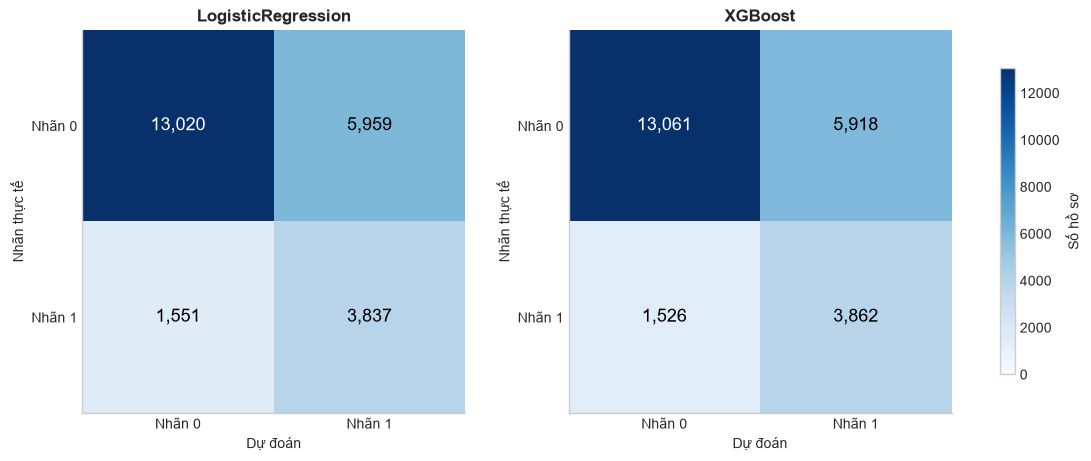

Nhóm đánh giá trên **24,367** hồ sơ Test, gồm **5,388** nhãn 1 (**22.11%**). Nhóm giữ ngưỡng 0,5 và không điều chỉnh mô hình theo kết quả Test.

In [36]:
import joblib
from sklearn.metrics import confusion_matrix

FINAL_FEATURE_SETS = {
    "LogisticRegression": FEATURES + ["GenHlth_PhysHlth"],
    "XGBoost": FEATURES + ["GenHlth_DiffWalk","HighBP_HighChol"],
}
FINAL_BASE = BASE / "final_test_lr22_xgb23"
FINAL_BASE.mkdir(exist_ok=True)
final_data = add_interaction_features(clean_data)
final_joined = final_data.merge(manifest[["row_id","group_id","split"]],on="row_id",validate="one_to_one")
final_train = final_joined.loc[final_joined.split.eq("train")].sort_values("row_id").reset_index(drop=True)
final_test = final_joined.loc[final_joined.split.eq("test")].sort_values("row_id").reset_index(drop=True)
assert len(final_train)+len(final_test)==len(clean_data)
assert not set(final_train.row_id)&set(final_test.row_id)
assert not set(final_train.group_id)&set(final_test.group_id)
assert len(final_train)==len(train_data)
final_y_train = final_train[TARGET].to_numpy(dtype=int)
final_y_test = final_test[TARGET].to_numpy(dtype=int)
final_protocol = {
    "feature_sets":FINAL_FEATURE_SETS,"primary_model_from_cv":"XGBoost","threshold":.5,
    "source_data_sha256":actual_sha256,
    "split_sha256":hashlib.sha256(manifest.to_csv(index=False).encode()).hexdigest(),
    "train_rows":len(final_train),"test_rows":len(final_test),
    "parameters":{name:initial_model(name,final_y_train).get_params() for name in FINAL_FEATURE_SETS},
    "versions":{"sklearn":sklearn.__version__,"xgboost":xgboost.__version__},
}
protocol_text=json.dumps(final_protocol,ensure_ascii=False,indent=2)
protocol_path=FINAL_BASE/"protocol.json"
if protocol_path.exists():
    assert protocol_path.read_text(encoding="utf-8")==protocol_text
else:
    protocol_path.write_text(protocol_text,encoding="utf-8")
final_records=[]
final_matrices={}
for name,columns in FINAL_FEATURE_SETS.items():
    model_file=FINAL_BASE/(name+".joblib")
    predictions_file=FINAL_BASE/(name+"_predictions.csv")
    audit_file=FINAL_BASE/(name+"_audit.json")
    if model_file.exists() and predictions_file.exists() and audit_file.exists():
        pipeline=joblib.load(model_file)
        saved=pd.read_csv(predictions_file,float_precision="round_trip")
        np.testing.assert_array_equal(saved.row_id,final_test.row_id)
        np.testing.assert_array_equal(saved.actual,final_y_test)
        probability=saved.probability.to_numpy()
    else:
        pipeline=Pipeline([("preprocess",initial_preprocessor(columns,name=="LogisticRegression")),
                           ("model",initial_model(name,final_y_train))])
        start=time.monotonic()
        with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=4):
            warnings.simplefilter("always")
            pipeline.fit(final_train[columns],final_y_train)
            probability=pipeline.predict_proba(final_test[columns])[:,1]
        if any(issubclass(w.category,ConvergenceWarning) for w in caught):
            raise RuntimeError(f"{name}: convergence warning")
        joblib.dump(pipeline,model_file)
        pd.DataFrame({"row_id":final_test.row_id,"actual":final_y_test,"probability":probability,
                      "predicted":(probability>=.5).astype(int)}).to_csv(predictions_file,index=False)
        audit_file.write_text(json.dumps({"seconds":time.monotonic()-start,
            "warnings":[str(w.message) for w in caught],"fit_rows":len(final_train),
            "encoded_columns":len(pipeline.named_steps['preprocess'].get_feature_names_out())},indent=2),encoding="utf-8")
    assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
    pred=(probability>=.5).astype(int)
    matrix=confusion_matrix(final_y_test,pred,labels=[0,1])
    tn,fp,fn,tp=map(int,matrix.ravel())
    final_matrices[name]=matrix
    final_records.append({"Model":name,"Features":len(columns),"TestRows":len(final_test),
        "AP":average_precision_score(final_y_test,probability),"ROC_AUC":roc_auc_score(final_y_test,probability),
        "Precision":precision_score(final_y_test,pred,zero_division=0),"Recall":recall_score(final_y_test,pred),
        "F1":f1_score(final_y_test,pred),"Accuracy":accuracy_score(final_y_test,pred),
        "TN":tn,"FP":fp,"FN":fn,"TP":tp})
    print(f"Đã đánh giá {name}: {len(final_train):,} Train; {len(final_test):,} Test.",flush=True)
final_test_results=pd.DataFrame(final_records)
display(final_test_results.round(5))
final_test_results.to_csv(FINAL_BASE/"test_metrics.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
vmax=max(matrix.max() for matrix in final_matrices.values())
for ax,(name,matrix) in zip(axes,final_matrices.items()):
    heat=ax.imshow(matrix,cmap="Blues",vmin=0,vmax=vmax)
    for i,j in np.ndindex(matrix.shape):
        ax.text(j,i,f"{matrix[i,j]:,}",ha="center",va="center",fontsize=13,color="white" if matrix[i,j]>vmax*.6 else "black")
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["Nhãn 0","Nhãn 1"],yticklabels=["Nhãn 0","Nhãn 1"],
           xlabel="Dự đoán",ylabel="Nhãn thực tế",title=name)
    ax.grid(False)
fig.colorbar(heat,ax=axes.tolist(),label="Số hồ sơ",shrink=.8)
save_and_show_figure("final_test_confusion_matrices",fig)
note(f"Nhóm đánh giá trên **{len(final_test):,}** hồ sơ Test, gồm **{int((final_y_test==1).sum()):,}** nhãn 1 "
     f"(**{100*final_y_test.mean():.2f}%**). Nhóm giữ ngưỡng 0,5 và không điều chỉnh mô hình theo kết quả Test.")


# VIII. Kết luận, giới hạn và hướng nghiên cứu tiếp theo

## 8.1. Kết quả và mức cải thiện

Nhóm đã so sánh bộ 21 với bộ 17 biến trên bốn mô hình, sau đó thử từng biến tương tác trên Logistic Regression và XGBoost bằng cùng 5 fold. Nhóm chọn AP trung bình để quyết định qua từng lượt và chốt hai bộ trước khi đánh giá Test.

Khi đối chiếu trên cùng CV, nhóm ghi nhận AP và F1 tăng nhẹ so với baseline 21 biến:

| Mô hình | AP baseline | AP bộ cuối | F1 baseline | F1 bộ cuối |
|---|---:|---:|---:|---:|
| Logistic Regression | 0,464203 | 0,464838 | 0,504094 | 0,504434 |
| XGBoost | 0,479941 | 0,481784 | 0,505711 | 0,506974 |

Nhóm chưa chứng minh khác biệt có ý nghĩa thống kê. Nhóm kết luận các biến tương tác chỉ đem lại mức cải thiện nhỏ trong thiết lập đã thử. Nhóm đánh giá các bộ cuối trên Test ở phần VII; nhóm không so sánh trực tiếp CV của baseline với Test của bộ cuối để khẳng định mức cải thiện.


**Trả lời câu hỏi nghiên cứu:** Nhóm quan sát trên Train các liên hệ từng cặp với nhãn, nổi bật là GenHlth, BMI và HighBP trong heatmap Pearson. Nhóm chưa diễn giải các liên hệ này như nguyên nhân hoặc đóng góp độc lập. Trên Test, nhóm ghi nhận Logistic Regression có AP=0,464075, Precision=39,17%, Recall=71,21%, F1=50,54%; XGBoost có AP=0,482203, Precision=39,49%, Recall=71,68%, F1=50,92% tại ngưỡng 0,5.

Với XGBoost, nhóm nhận diện 3.862/5.388 hồ sơ nhãn 1, bỏ sót 1.526 hồ sơ và dự đoán nhãn 1 cho 5.918 hồ sơ nhãn 0. Nhóm cần nêu cả mức nhận diện và báo nhầm. Nếu chỉ dự đoán nhãn 0, nhóm đạt Accuracy=77,89% trên Test nhưng Recall nhãn 1 bằng 0; hai mô hình dùng trọng số lớp đạt Accuracy khoảng 69% cùng Recall khoảng 71%. Vì vậy, nhóm không dùng Accuracy riêng lẻ để kết luận mô hình tốt hơn.

## 8.2. Giả thuyết cho nghiên cứu tiếp theo: BMI cao và nhãn 0

Nhóm giữ BMI thập phân và các hồ sơ ngoài ngưỡng IQR trong nghiên cứu này. Nhóm đã kiểm tra phép chuyển đổi BMI, nhưng chưa xác minh độ chính xác của thông tin chiều cao/cân nặng tự khai hoặc đánh giá tác động riêng của các hồ sơ BMI rất cao lên kết quả mô hình.

Trong 121.839 hồ sơ sạch, nhóm ghi nhận **375 hồ sơ có BMI > 50 và nhãn 0**, gồm **14 hồ sơ có BMI > 90**; BMI lớn nhất trong nhóm này là **97,65**. Nhãn 0 biểu thị câu trả lời DIABETE3=3, không phải xác nhận độc lập qua xét nghiệm.

Nhóm đặt giả thuyết rằng việc rà soát chất lượng dữ liệu ở các hồ sơ BMI cao có thể cung cấp thông tin cho nghiên cứu sau. Nhóm đề xuất quy tắc gắn cờ **`(BMI > 50) & (Diabetes_binary == 0)`** như một cách xác định hồ sơ cần kiểm tra. Nhóm chọn ngưỡng 50 để đề xuất rà soát, chưa xác nhận đó là ngưỡng phát hiện lỗi hoặc khẳng định các hồ sơ này gây ra mức cải thiện nhỏ của mô hình.

Nhóm chưa kết luận BMI cao đi kèm nhãn 0 là dữ liệu nhiễu hay nhãn sai. CDC trình bày BMI như chỉ số sàng lọc cần xem cùng thông tin sức khỏe khác; nhóm không suy ra tình trạng tiểu đường từ riêng BMI. Tham khảo [CDC — About BMI](https://www.cdc.gov/bmi/about/).

Nhóm chỉ nêu giả thuyết, không thực hiện gắn cờ, sửa nhãn, xóa hồ sơ hoặc fine-tuning trong dự án này. Nếu một nghiên cứu sau sử dụng cờ, nhóm chỉ dùng nó để rà soát vì công thức chứa nhãn; nhóm không đưa cờ vào đầu vào dự đoán. Việc đánh giá quy tắc mới cũng cần kế hoạch xác thực riêng, vì nhóm đã xem kết quả Test hiện tại.

## 8.3. Giới hạn nghiên cứu

Nhóm phân loại nhãn tự khai gộp tiền tiểu đường/tiểu đường trong mẫu khảo sát từ 60 tuổi trở lên. Nhóm đã loại 39,56% hồ sơ ở bước làm sạch và chưa dùng trọng số khảo sát; nhóm cần cân nhắc thiên lệch chọn mẫu. Nhóm chọn biến qua EDA và nhiều lượt CV trên cùng Train nên kết quả CV có thể lạc quan. Nhóm chưa thực hiện nested CV hoặc xác thực trên dữ liệu bên ngoài. Nhóm đã xem thống kê toàn mẫu trước khi chia dữ liệu; sau khi chia, nhóm chỉ dùng Train để chọn cấu hình và giữ chỉ số hiệu năng Test đến đánh giá cuối.

Nhóm chưa coi kết quả là bằng chứng chẩn đoán lâm sàng, dự báo phát bệnh tương lai hoặc thay thế quyết định của nhân viên y tế. Nhóm kết thúc dự án tại mục VIII, giữ nguyên dữ liệu, mô hình và kết quả đã báo cáo.


## Tài liệu tham khảo

- [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html) và [BRFSS2015 Codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf): nguồn dữ liệu, nội dung câu hỏi, mã phản hồi và nhánh câu hỏi.
- [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) và [notebook Alex Teboul](https://www.kaggle.com/code/alexteboul/diabetes-health-indicators-dataset-notebook): căn cứ kế thừa bộ 21 feature và phần lớn quy trình xử lý. Nhóm chọn người từ 60 tuổi trở lên trong báo cáo này, loại hồ sơ chỉ tiểu đường khi mang thai, và gộp tiền tiểu đường/tiểu đường thành lớp 1 theo định nghĩa nghiên cứu.
- Các nghiên cứu và nguồn chuyên ngành được dẫn trực tiếp trong bảng căn cứ chọn biến. Nhóm xem xét khác biệt về quần thể, năm khảo sát, nhãn và cách đo khi sử dụng kết quả tham khảo.
